# Read and check data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# res_df   = pd.read_csv('/perm/mokr/reservoir_gradient_importance.csv')

In [3]:
# nonres_df = pd.read_csv('/perm/mokr/nonreservoir_gradient_importance.csv')


res_df   = pd.read_csv('/perm/mokr/1505_reservoir_gradient_importance.csv')
nonres_df = pd.read_csv('/perm/mokr/1505_nonreservoir_gradient_importance.csv')

In [4]:
res_models = res_df["model"].unique()
nonres_models = nonres_df["model"].unique()


In [5]:
nonres_df 

,model,sample_idx,static__inter_high_perc,static__inter_mod_perc,static__inter_low_perc,static__frac_high_perc,static__frac_mod_perc,static__frac_low_perc,static__no_gw_perc,static__low_nsig_perc,...,temporal__windspeed_day_80,temporal__windspeed_day_81,temporal__windspeed_day_82,temporal__windspeed_day_83,temporal__windspeed_day_84,temporal__windspeed_day_85,temporal__windspeed_day_86,temporal__windspeed_day_87,temporal__windspeed_day_88,temporal__windspeed_day_89
0,Reservoir_Embedded_LSTM,0,0.001856,0.000372,0.007438,0.002561,0.002179,0.000149,0.002468,0.000625,...,0.000334,0.000342,0.000919,0.001271,0.000336,0.000837,0.001212,0.004125,0.000094,0.012189
1,NonReservoir_Embedded_LSTM,0,0.000978,0.021090,0.001710,0.002415,0.001750,0.005607,0.004270,0.000106,...,0.000088,0.000073,0.000408,0.000286,0.000105,0.001595,0.007981,0.012537,0.002250,0.004053
2,Full_Embedded_LSTM,0,0.000729,0.014720,0.002008,0.007375,0.003038,0.003659,0.001073,0.000914,...,0.000651,0.000163,0.000207,0.000472,0.000095,0.000836,0.008608,0.009720,0.000077,0.010515
3,Hydra_Main,0,0.000674,0.009428,0.004826,0.006306,0.001260,0.001358,0.000590,0.000626,...,0.001901,0.000349,0.000854,0.000175,0.000773,0.008771,0.013211,0.007352,0.001531,0.005467
4,Hydra_ResHead,0,0.000665,0.008714,0.005062,0.006009,0.000751,0.000403,0.000580,0.001028,...,0.002629,0.000831,0.001802,0.000478,0.000756,0.008265,0.009281,0.008199,0.002846,0.005617
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75055,NonReservoir_Embedded_LSTM,12509,0.000006,0.040947,0.002801,0.001802,0.003198,0.003567,0.006720,0.000242,...,0.000278,0.001481,0.000435,0.001492,0.000250,0.000858,0.000605,0.006371,0.000152,0.002915
75056,Full_Embedded_LSTM,12509,0.000032,0.036222,0.001020,0.001420,0.000534,0.004143,0.003193,0.001134,...,0.006067,0.000288,0.005439,0.000452,0.000067,0.001312,0.000455,0.008096,0.013636,0.001813
75057,Hydra_Main,12509,0.000188,0.028407,0.008031,0.000088,0.001167,0.002446,0.002838,0.001677,...,0.001549,0.003496,0.022079,0.001074,0.002855,0.001339,0.000845,0.001549,0.005905,0.000606
75058,Hydra_ResHead,12509,0.000133,0.025946,0.007542,0.001336,0.001600,0.002411,0.002278,0.001697,...,0.001544,0.003649,0.022581,0.001334,0.002406,0.002201,0.001109,0.000903,0.010477,0.000590


In [6]:
res_df_list = []
for mod in res_models:
    res_df_list.append(res_df[res_df["model"] == mod] )


nonres_df_list = []
for mod in nonres_models:
    nonres_df_list.append(nonres_df[nonres_df["model"] == mod] )


# Merging temporal columns

In [7]:
import re
def plot_temporal_feature(df, feature, label):
    precip_cols = sorted(
        [c for c in df.columns if f"temporal__{feature}_day_" in c],
        key=lambda x: int(re.search(r"_day_(\d+)", x).group(1))
    )
    days = [int(re.search(r"_day_(\d+)", c).group(1)) for c in precip_cols]
    model_mean = df.groupby("model")[precip_cols].mean()

    for model_name in model_mean.index:
        plt.plot(days, model_mean.loc[model_name].values, label=model_name, linewidth=1.5)

    plt.title(f"Temporal Gradient Importance: {feature}\n({label})")
    plt.xlabel("Days into the Sequence")
    plt.ylabel("Mean Absolute Gradient Importance")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)

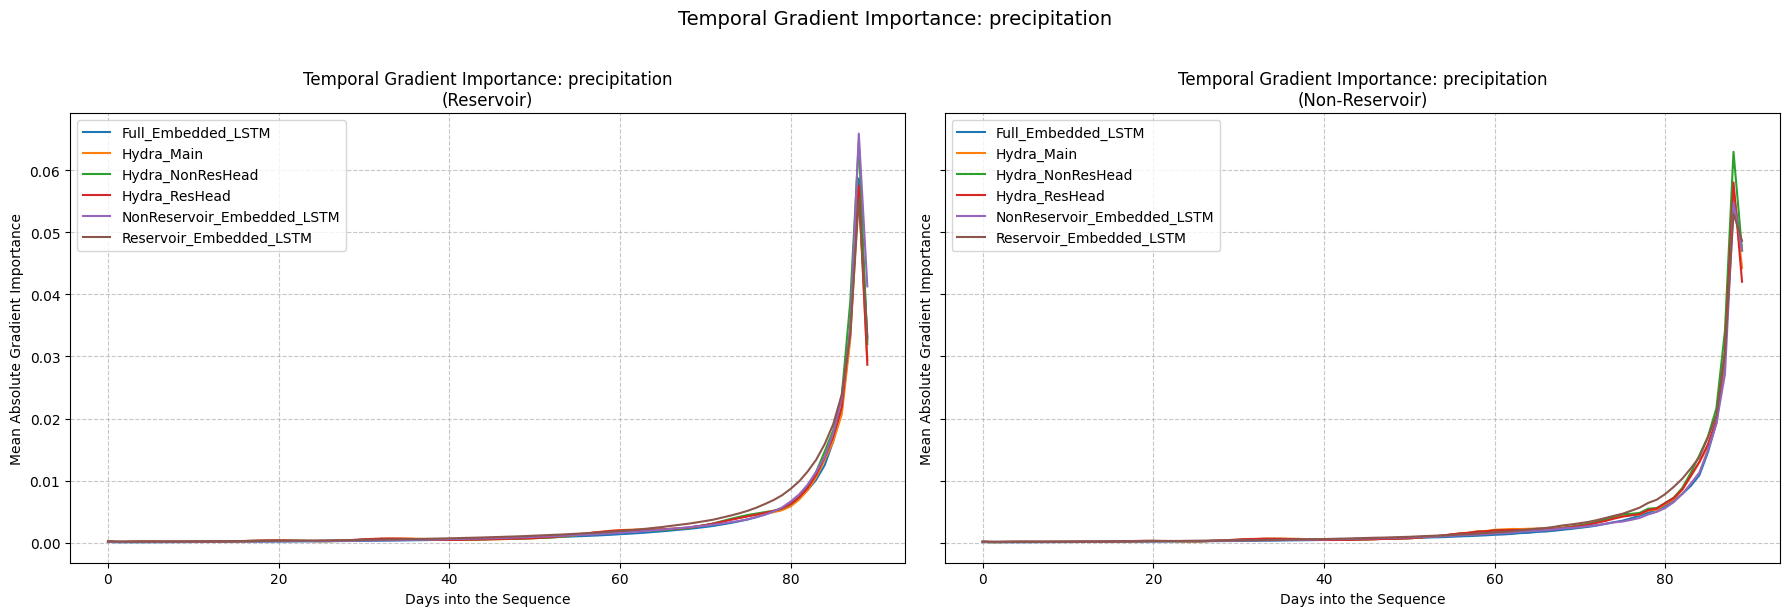

In [8]:
DATASETS = {'Reservoir': res_df, 'Non-Reservoir': nonres_df}
FEATURE   = "precipitation" #"precipitation", "temperature", "humidity", "windspeed", "longwave_rad", "shortwave_rad", "peti", "pet"
N         = 10


# ── Temporal feature plots ────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)

for ax, (name, df) in zip(axes, DATASETS.items()):
    plt.sca(ax)
    plot_temporal_feature(df, FEATURE, name)

plt.suptitle(f"Temporal Gradient Importance: {FEATURE}", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [9]:
def aggregate_temporal_features(df, variables, buckets=None, combine_sources=False):
    """
    For each variable in `variables`, sum absolute values of integrated gradients
    across day-range buckets.

    Parameters
    ----------
    df              : pd.DataFrame
    variables       : list[str]  – variable name fragments to aggregate, e.g.
                                   ["precipitation", "temperature", "humidity"]
    buckets         : list of (int, int, str) – (day_lo, day_hi, label)
                      Defaults to the standard 5 precip buckets if None.
    combine_sources : bool - If True, aggregates across all sources (e.g. haduk, cehgear) 
                      for a given variable. If False, keeps sources separate.

    Returns
    -------
    pd.DataFrame with original temporal columns replaced by bucketed abs-sums.
    """
    if buckets is None:
        buckets = [
            (0,  89, "day_0_30"),
            (31, 60, "day_31_60"),
            (61, 75, "day_61_75"),
            (76, 82, "day_76_82"),
            (83, 89, "day_83_89"),
        ]

    # matches e.g. "temporal__precipitation_haduk_day_86"
    #                            ^--- source+var ----^ ^day^
    pattern = re.compile(r"^temporal__((\w+?)(?:_\w+?)?)_day_(\d+)$")

    # index all temporal day columns
    all_temporal = {}   # col -> (full_source_str, day)
    for col in df.columns:
        m = pattern.match(col)
        if m:
            all_temporal[col] = (m.group(1), int(m.group(3)))

    cols_to_drop = set()
    new_cols = {}

    for variable in variables:
        # filter to columns belonging to this variable
        var_cols = {
            col: (source, day)
            for col, (source, day) in all_temporal.items()
            if re.search(rf"(^|_){re.escape(variable)}(_|$)", source)
        }

        if not var_cols:
            print(f"  Warning: no columns found for variable '{variable}'")
            continue

        if combine_sources:
            # Group purely by bucket, ignoring the specific source
            for lo, hi, label in buckets:
                cols_in_bucket = [
                    col for col, (src, day) in var_cols.items()
                    if lo <= day <= hi
                ]
                if cols_in_bucket:
                    new_col_name = f"temporal__{variable}__{label}_abs"
                    new_cols[new_col_name] = df[cols_in_bucket].abs().sum(axis=1)
        else:
            # Original behavior: Group by both source and bucket
            sources = sorted(set(src for src, _ in var_cols.values()))
            for source in sources:
                for lo, hi, label in buckets:
                    cols_in_bucket = [
                        col for col, (src, day) in var_cols.items()
                        if src == source and lo <= day <= hi
                    ]
                    if cols_in_bucket:
                        new_col_name = f"temporal__{source}__{label}_abs"
                        new_cols[new_col_name] = df[cols_in_bucket].abs().sum(axis=1)

        cols_to_drop.update(var_cols.keys())

    df_out = df.drop(columns=list(cols_to_drop))
    # Concatenate all new aggregated columns at once for better pandas performance
    if new_cols:
        df_out = pd.concat([df_out, pd.DataFrame(new_cols, index=df.index)], axis=1)

    return df_out

In [10]:
variables_to_aggregate = ["precipitation", "temperature", "humidity", "windspeed", "longwave_rad", "shortwave_rad", "peti", "pet"]

res_df_agg    = aggregate_temporal_features(res_df,    variables=variables_to_aggregate, combine_sources = True)
nonres_df_agg = aggregate_temporal_features(nonres_df, variables=variables_to_aggregate, combine_sources = True)

In [11]:
res_df_agg.iloc[0:20,110:140]

,static__urban_perc_1990,static__inwater_perc_1990,static__bares_perc_1990,temporal__precipitation__day_0_30_abs,temporal__precipitation__day_31_60_abs,temporal__precipitation__day_61_75_abs,temporal__precipitation__day_76_82_abs,temporal__precipitation__day_83_89_abs,temporal__temperature__day_0_30_abs,temporal__temperature__day_31_60_abs,...,temporal__windspeed__day_61_75_abs,temporal__windspeed__day_76_82_abs,temporal__windspeed__day_83_89_abs,temporal__longwave_rad__day_0_30_abs,temporal__longwave_rad__day_31_60_abs,temporal__longwave_rad__day_61_75_abs,temporal__longwave_rad__day_76_82_abs,temporal__longwave_rad__day_83_89_abs,temporal__shortwave_rad__day_0_30_abs,temporal__shortwave_rad__day_31_60_abs
0,0.010199,0.001410,0.001380,1.988490,0.061863,0.201989,0.317273,1.400244,0.498792,0.024820,...,0.008021,0.006702,0.033098,0.160316,0.009570,0.027961,0.017402,0.104386,0.149572,0.005210
1,0.022200,0.370363,0.002198,2.745774,0.154979,0.540042,0.366195,1.626782,1.106497,0.155210,...,0.059616,0.034446,0.124817,0.330500,0.047294,0.034267,0.021030,0.206918,0.383293,0.101742
2,0.000073,0.144761,0.005186,1.867659,0.055208,0.213458,0.243388,1.344751,0.631441,0.040291,...,0.015228,0.084184,0.071389,0.152800,0.009233,0.013375,0.013013,0.115573,0.175301,0.009796
3,0.027692,0.178993,0.015082,1.760869,0.087130,0.240065,0.287984,1.123461,1.299059,0.168693,...,0.185032,0.064316,0.138084,0.461223,0.042538,0.111351,0.061177,0.233292,0.456086,0.058867
4,0.028600,0.164128,0.012337,1.639625,0.078523,0.186651,0.241524,1.112250,1.296135,0.138458,...,0.190716,0.070196,0.136979,0.487387,0.049618,0.124681,0.076598,0.224380,0.441062,0.053886
5,0.025412,0.163143,0.014825,1.807698,0.072608,0.222598,0.261112,1.229115,1.369950,0.165408,...,0.183976,0.072117,0.149135,0.502806,0.053909,0.129410,0.072660,0.234117,0.478297,0.062779
6,0.006766,0.018837,0.012077,4.262138,0.258349,0.203970,0.239616,3.458282,0.990806,0.253547,...,0.019011,0.049142,0.342734,0.256349,0.027088,0.030696,0.056582,0.133431,0.303557,0.039119
7,0.050809,0.087786,0.008939,3.321764,0.101219,0.156125,0.299839,2.743037,0.539244,0.057030,...,0.062664,0.064071,0.254898,0.313097,0.024653,0.011528,0.046621,0.222498,0.201787,0.004625
8,0.011644,0.056339,0.002947,3.804030,0.172628,0.279419,0.327099,2.985480,0.584013,0.112302,...,0.054348,0.096210,0.373995,0.235319,0.012227,0.017069,0.029420,0.173479,0.225562,0.007600
9,0.019102,0.060007,0.011662,3.479528,0.244075,0.140111,0.266880,2.798578,0.654400,0.190992,...,0.037662,0.147455,0.460297,0.426548,0.049157,0.019700,0.122481,0.226804,0.240056,0.023734


## Basic Sensitivity Results: Before PCA

In [12]:
def plot_column_means(df, n_vars=None, separate_plots=False):
    """
    Plot normalised column means as a bar chart, sorted descending.
    
    Parameters:
        df:               DataFrame (columns from index 2 onward are used)
        n_vars:           Number of top variables to show per group (None = all)
        separate_plots:   If True, plot temporal_ and static_ on separate subplots
    """
    means = df.iloc[:, 2:].mean()
    
    # Normalise so all values sum to 1
    means = means / means.sum()
    means = means.sort_values(ascending=False)

    temporal = means[means.index.str.startswith('temporal_')]
    static   = means[means.index.str.startswith('static_')]

    if n_vars is not None:
        temporal = temporal.head(n_vars)
        static   = static.head(n_vars)

    def add_bar_labels(ax, subset):
        for i, val in enumerate(subset.values):
            ax.text(i, 0.001, f'{val:.2f}', ha='center', va='bottom',
                    fontsize=8, rotation=0, color='white', fontweight='bold')

    if separate_plots:
        fig, axes = plt.subplots(1, 2, figsize=(16, 5))

        for ax, subset, colour, title in zip(
            axes,
            [temporal, static],
            ['#4C72B0', '#DD8452'],
            ['Temporal Features', 'Static Features']
        ):
            ax.bar(range(len(subset)), subset.values, color=colour)
            ax.set_xticks(range(len(subset)))
            ax.set_xticklabels(subset.index, rotation=45, ha='right')
            ax.set_title(title)
            ax.set_ylabel('Normalised Sensitivity')
            add_bar_labels(ax, subset)

    else:
        combined = temporal.combine_first(static).sort_values(ascending=False)

        colours = [
            '#4C72B0' if col.startswith('temporal_') else
            '#DD8452' if col.startswith('static_') else
            '#8C8C8C'
            for col in combined.index
        ]

        fig, ax = plt.subplots(figsize=(max(10, len(combined) * 0.5), 5))
        ax.bar(range(len(combined)), combined.values, color=colours)
        ax.set_xticks(range(len(combined)))
        ax.set_xticklabels(combined.index, rotation=45, ha='right')
        ax.set_title('Column Means (Normalised)')
        ax.set_ylabel('Normalised Sensitivity')
        add_bar_labels(ax, combined)

        handles = [
            plt.Rectangle((0,0), 1, 1, color='#4C72B0', label='temporal_'),
            plt.Rectangle((0,0), 1, 1, color='#DD8452', label='static_'),
        ]
        ax.legend(handles=handles)

    plt.tight_layout()
    plt.show()

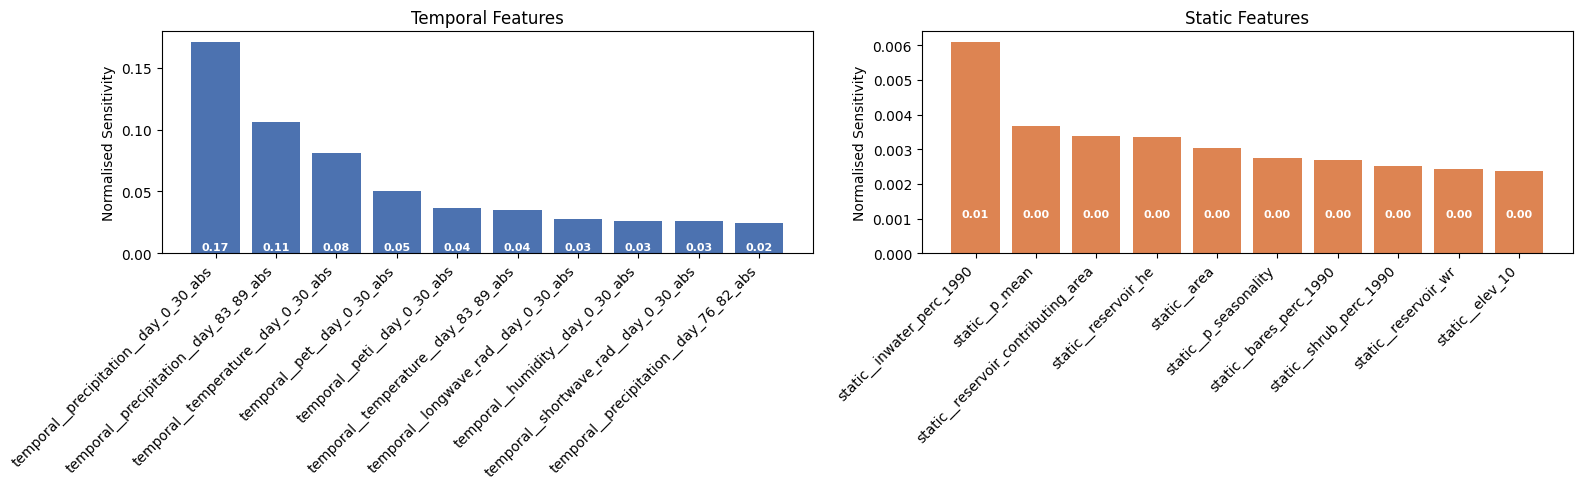

In [13]:
plot_column_means(res_df_agg, n_vars=10, separate_plots=True)

## Splitting temporal and static varaibles

In [14]:
res_df_agg
nonres_df_agg
key_cols = ['model', 'sample_idx']

static_cols = [col for col in nonres_df_agg.columns if col.startswith('static_')]
temporal_cols = [col for col in nonres_df_agg.columns if col.startswith('temporal_')]

static_res_df = res_df_agg[key_cols + static_cols]
temporal_res_df = res_df_agg[key_cols + temporal_cols]

static_nonres_df = nonres_df_agg[key_cols + static_cols]
temporal_nonres_df = nonres_df_agg[key_cols + temporal_cols]

In [15]:
static_nonres_df

,model,sample_idx,static__inter_high_perc,static__inter_mod_perc,static__inter_low_perc,static__frac_high_perc,static__frac_mod_perc,static__frac_low_perc,static__no_gw_perc,static__low_nsig_perc,...,static__low_prec_freq,static__low_prec_dur,static__dwood_perc_1990,static__ewood_perc_1990,static__grass_perc_1990,static__shrub_perc_1990,static__crop_perc_1990,static__urban_perc_1990,static__inwater_perc_1990,static__bares_perc_1990
0,Reservoir_Embedded_LSTM,0,0.001856,0.000372,0.007438,0.002561,0.002179,0.000149,0.002468,0.000625,...,0.004672,0.001622,0.006274,0.006280,0.009927,0.003581,0.002723,0.002753,0.001323,0.002216
1,NonReservoir_Embedded_LSTM,0,0.000978,0.021090,0.001710,0.002415,0.001750,0.005607,0.004270,0.000106,...,0.000612,0.000803,0.003231,0.002695,0.007074,0.001479,0.000560,0.003319,0.000799,0.008655
2,Full_Embedded_LSTM,0,0.000729,0.014720,0.002008,0.007375,0.003038,0.003659,0.001073,0.000914,...,0.003971,0.004046,0.008079,0.002450,0.011495,0.002333,0.000535,0.001000,0.000154,0.005621
3,Hydra_Main,0,0.000674,0.009428,0.004826,0.006306,0.001260,0.001358,0.000590,0.000626,...,0.005914,0.004373,0.001259,0.003175,0.010152,0.014018,0.001133,0.002497,0.000026,0.000003
4,Hydra_ResHead,0,0.000665,0.008714,0.005062,0.006009,0.000751,0.000403,0.000580,0.001028,...,0.006552,0.004805,0.001980,0.004170,0.008706,0.012784,0.000259,0.002497,0.000038,0.000038
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75055,NonReservoir_Embedded_LSTM,12509,0.000006,0.040947,0.002801,0.001802,0.003198,0.003567,0.006720,0.000242,...,0.000531,0.000048,0.006762,0.004637,0.009194,0.007179,0.001069,0.000701,0.000060,0.007795
75056,Full_Embedded_LSTM,12509,0.000032,0.036222,0.001020,0.001420,0.000534,0.004143,0.003193,0.001134,...,0.002076,0.000560,0.003403,0.003284,0.024074,0.009509,0.000952,0.000476,0.000002,0.003732
75057,Hydra_Main,12509,0.000188,0.028407,0.008031,0.000088,0.001167,0.002446,0.002838,0.001677,...,0.006838,0.001367,0.007388,0.016086,0.017212,0.029122,0.001489,0.000722,0.000250,0.000073
75058,Hydra_ResHead,12509,0.000133,0.025946,0.007542,0.001336,0.001600,0.002411,0.002278,0.001697,...,0.006310,0.001274,0.007190,0.018753,0.010083,0.031054,0.001588,0.000580,0.000238,0.002091


# Calculate covariance across samples for each model in df

In [16]:
from numpy.linalg import eig

print(res_df_list[0].columns)

res_cov_list = []
for info in res_df_list:
    info = info.iloc[:, 2:]
    res_cov_list.append(info.cov())
    print(info.cov().shape)

nonres_cov_list = []
for info in nonres_df_list:
    info = info.iloc[:, 2:]
    nonres_cov_list.append(info.cov())
    print(info.cov().shape)

Index(['model', 'sample_idx', 'static__inter_high_perc',
       'static__inter_mod_perc', 'static__inter_low_perc',
       'static__frac_high_perc', 'static__frac_mod_perc',
       'static__frac_low_perc', 'static__no_gw_perc', 'static__low_nsig_perc',
       ...
       'temporal__windspeed_day_80', 'temporal__windspeed_day_81',
       'temporal__windspeed_day_82', 'temporal__windspeed_day_83',
       'temporal__windspeed_day_84', 'temporal__windspeed_day_85',
       'temporal__windspeed_day_86', 'temporal__windspeed_day_87',
       'temporal__windspeed_day_88', 'temporal__windspeed_day_89'],
      dtype='object', length=1553)
(1551, 1551)
(1551, 1551)
(1551, 1551)
(1551, 1551)
(1551, 1551)
(1551, 1551)
(1551, 1551)
(1551, 1551)
(1551, 1551)
(1551, 1551)
(1551, 1551)
(1551, 1551)


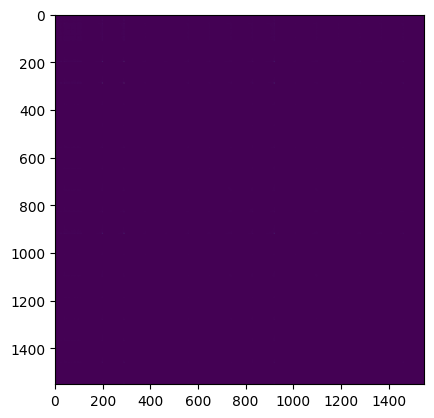

In [17]:
import matplotlib.pyplot as plt


#print(cov_list[3])
plt.imshow(res_cov_list[0])
plt.show()


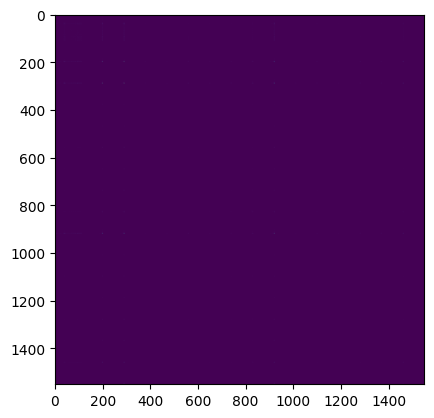

In [18]:
#print(cov_list[3])
plt.imshow(nonres_cov_list[0])
plt.show()


In [19]:
import numpy as np

leading_vecs = []
leading_vals = []

# compute leading eigenvectors and eigenvalues
for cov in cov_list:
    vals, vecs = np.linalg.eigh(cov)

    idx = np.argmax(vals)
    v = vecs[:, idx]
    v = v / np.linalg.norm(v)

    leading_vecs.append(v)
    leading_vals.append(vals[idx])

leading_vecs = np.array(leading_vecs)
leading_vals = np.array(leading_vals)

# cosine similarity matrix
cos_sim = np.abs(leading_vecs @ leading_vecs.T)

# eigenvalue ratio matrix (smaller / larger)
min_vals = np.minimum(leading_vals[:, None], leading_vals[None, :])
max_vals = np.maximum(leading_vals[:, None], leading_vals[None, :])
eig_ratio = min_vals / max_vals

# subplots
fig, axes = plt.subplots(1, 2, figsize=(12,5))

# cosine similarity heatmap
im1 = axes[0].imshow(cos_sim, cmap="viridis")
axes[0].set_xticks(range(len(models)))
axes[0].set_yticks(range(len(models)))
axes[0].set_xticklabels(models)
axes[0].set_yticklabels(models)
axes[0].set_title("Leading Eigenvector Cosine Similarity")
axes[0].set_xlabel("Model")
axes[0].set_ylabel("Model")
fig.colorbar(im1, ax=axes[0], label="Cosine similarity")

# eigenvalue ratio heatmap
im2 = axes[1].imshow(eig_ratio, cmap="Blues")
axes[1].set_xticks(range(len(models)))
axes[1].set_yticks(range(len(models)))
axes[1].set_xticklabels(models)
axes[1].set_yticklabels(models)
axes[1].set_title("Leading Eigenvalue Ratio (min/max)")
axes[1].set_xlabel("Model")
axes[1].set_ylabel("Model")
fig.colorbar(im2, ax=axes[1], label="$λ_{small}$ / $λ_{large}$")

for ax in axes:
    plt.sca(ax)
    plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()
print(cos_sim)

NameError: name 'cov_list' is not defined

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# choose two models
i, j = 0, 1

cov1 = cov_list[i]
cov2 = cov_list[j]

# eigendecomposition
vals1, vecs1 = np.linalg.eigh(cov1)
vals2, vecs2 = np.linalg.eigh(cov2)

# sort eigenvalues (descending) and reorder eigenvectors
idx1 = np.argsort(vals1)[::-1]
idx2 = np.argsort(vals2)[::-1]

vals1 = vals1[idx1]
vecs1 = vecs1[:, idx1]

vals2 = vals2[idx2]
vecs2 = vecs2[:, idx2]

# normalise eigenvectors
vecs1 = vecs1 / np.linalg.norm(vecs1, axis=0)
vecs2 = vecs2 / np.linalg.norm(vecs2, axis=0)

# cosine similarity matrix
sim = np.abs(vecs1.T @ vecs2)

# plot
fig, ax = plt.subplots(figsize=(7,6))
im = ax.imshow(sim[:15, :15], cmap="viridis")

fig.colorbar(im, ax=ax, label="Cosine similarity")
ax.set_xlabel(f"Leading Eigenvectors: {models[j]}")
ax.set_ylabel(f"Leading Eigenvectors: {models[i]}")
ax.set_title("Eigenvector Cosine Similarity (ordered by eigenvalue)")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

threshold = 0.9

fig, ax = plt.subplots(figsize=(8,6))

colors = plt.cm.tab10(np.linspace(0, 1, len(cov_list)))

for cov, model, color in zip(cov_list, models, colors):
    vals, vecs = np.linalg.eigh(cov)

    # sort eigenvalues descending
    idx = np.argsort(vals)[::-1]
    vals = vals[idx]

    n_components = np.arange(1, len(vals)+1)
    cum_var = np.cumsum(vals) / np.sum(vals)

    # plot eigenvalues
    ax.plot(n_components, vals, color=color, label=model)

    # threshold component
    k = np.searchsorted(cum_var, threshold) + 1
    ax.plot(k, vals[k-1], marker="*", markersize=12, color=color)

# Add a legend entry for the threshold star
ax.plot([], [], marker="*", color="black", linestyle="None", markersize=12, label=f"{int(threshold*100)}% explained variance")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Component number (log scale)")
ax.set_ylabel("Eigenvalue")
ax.set_title("Eigenvalues for All Models with Explained Variance Threshold")

ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 2. Wasserstein Distance Between Eigenvalue Distributions

Compares the full eigenvalue spectra using the 1-Wasserstein distance (earth mover's distance). Two models with identical spectral structure will score 0. This is sensitive to magnitude differences that cosine similarity ignores.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import itertools

def wasserstein1_sorted(a, b):
    """1-Wasserstein distance between two 1D distributions (as sorted arrays).
    Equivalent to the L1 distance between sorted values.
    """
    a_s = np.sort(a)[::-1]
    b_s = np.sort(b)[::-1]
    return np.mean(np.abs(a_s - b_s))

# Collect all eigenvalues
all_vals = []
for cov in cov_list:
    vals, _ = np.linalg.eigh(cov)
    all_vals.append(vals)

n = len(all_vals)
W_dist = np.zeros((n, n))
for i, j in itertools.combinations(range(n), 2):
    d = wasserstein1_sorted(all_vals[i], all_vals[j])
    W_dist[i, j] = d
    W_dist[j, i] = d

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(W_dist, cmap="magma")
fig.colorbar(im, ax=ax, label="Wasserstein-1 distance")
ax.set_xticks(range(n))
ax.set_yticks(range(n))
ax.set_xticklabels(models, rotation=45, ha="right")
ax.set_yticklabels(models)
ax.set_title("Wasserstein-1 Distance Between Eigenvalue Spectra")
plt.tight_layout()
plt.show()
print("Wasserstein-1 distance matrix:")
print(np.round(W_dist, 6))


## 3. Projection Frobenius Distance

Computes `||U1 U1^T - U2 U2^T||_F` — the Frobenius norm between the projection matrices onto each model's top-k subspace. This is independent of the internal basis ordering and gives a clean geometric dissimilarity.

In [ ]:


k = 10  # reuse or change
k_plot = k

# Projection matrices P = U U^T
projections = []
for cov in cov_list:
    vals, vecs = np.linalg.eigh(cov)
    idx = np.argsort(vals)[::-1]
    U = vecs[:, idx[:k]]
    P = U @ U.T
    projections.append(P)

n = len(projections)
PF_dist = np.zeros((n, n))
for i, j in itertools.combinations(range(n), 2):
    diff = projections[i] - projections[j]
    d = np.linalg.norm(diff, 'fro')
    PF_dist[i, j] = d
    PF_dist[j, i] = d

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(PF_dist, cmap="magma")
fig.colorbar(im, ax=ax, label="||P1 - P2||_F")
ax.set_xticks(range(n))
ax.set_yticks(range(n))
ax.set_xticklabels(models, rotation=45, ha="right")
ax.set_yticklabels(models)
ax.set_title(f"Projection Frobenius Distance (top-{k} subspace)")
plt.tight_layout()
plt.show()
print("Projection Frobenius distance matrix:")
print(np.round(PF_dist, 4))


## 5. Effective Rank and Intrinsic Dimensionality

Effective rank (Roy & Vetterli, 2007) measures how 'spread out' the eigenvalue mass is — a low effective rank means a few components dominate. Models trained similarly should have similar effective ranks. We also show the number of components needed to explain 50%, 80%, 90%, and 95% of variance.

In [ ]:

def effective_rank(vals):
    """Roy-Vetterli effective rank: exp(entropy of normalised eigenvalue distribution)."""
    vals = vals[vals > 0]
    p = vals / vals.sum()
    entropy = -np.sum(p * np.log(p))
    return np.exp(entropy)

thresholds = [0.50, 0.80, 0.90, 0.95, 0.99]

rows = []
for cov, model in zip(cov_list, models):
    vals, _ = np.linalg.eigh(cov)
    vals_desc = np.sort(vals)[::-1]
    cum_var = np.cumsum(vals_desc) / vals_desc.sum()
    erank = effective_rank(vals)
    k_thresh = [int(np.searchsorted(cum_var, t)) + 1 for t in thresholds]
    rows.append((model, erank, *k_thresh))

# Print table
header = f'{"Model":<30} {"Eff.Rank":>10}'
for t in thresholds:
    header += f'  {int(t*100)}% var'
print(header)
print('-' * len(header))
for r in rows:
    row = f'{r[0]:<30} {r[1]:>10.2f}'
    for k in r[2:]:
        row += f'  {k:>7d}'
    print(row)

# Bar chart of effective rank
model_names = [r[0] for r in rows]
eranks = [r[1] for r in rows]

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(model_names, eranks, color='steelblue')
ax.bar_label(bars, fmt='%.1f', padding=4)
ax.set_xlabel('Effective Rank')
ax.set_title('Effective Rank per Model (higher = more distributed variance)')
plt.tight_layout()
plt.show()


# Compare metrics
Side-by-side comparison of all metrics: Wasserstein distance, and Projection Frobenius distance, leading cosine sim — normalised for visual comparison.

In [ ]:

def normalise(M):
    """Min-max normalise a matrix to [0, 1]."""
    mn, mx = M.min(), M.max()
    if mx == mn:
        return np.zeros_like(M)
    return (M - mn) / (mx - mn)

matrices = [
    (W_dist,  'Wasserstein-1 (spectra)'),
    (PF_dist, f'Projection Frobenius (top-{k_plot})'),
    # Cosine SIMILARITY -> convert to distance for consistent direction
    (1 - cos_sim, 'Cosine distance (leading vec)'),
]

n_mat = len(matrices)
fig, axes = plt.subplots(1, n_mat, figsize=(5 * n_mat, 4))

for ax, (M, title) in zip(axes, matrices):
    Mn = normalise(M)
    im = ax.imshow(Mn, cmap='magma', vmin=0, vmax=1)
    ax.set_xticks(range(len(models)))
    ax.set_yticks(range(len(models)))
    ax.set_xticklabels(models, rotation=45, ha='right', fontsize=7)
    ax.set_yticklabels(models, fontsize=7)
    ax.set_title(title, fontsize=8)
    fig.colorbar(im, ax=ax, label='normalised distance')

plt.suptitle('Normalised Pairwise Dissimilarity — All Metrics', y=1.02, fontsize=11)
plt.tight_layout()
plt.show()


# Ideas

- It might be interesting to compare complexity with similiarity to some "gold standard" (e.g. best performing model), across a range of complexity (whether we define that as FLOPs or train/val gap or something)
- Some mutual information could also be interesting here

# Using Claude Functions

In [39]:
import numpy as np
import matplotlib.pyplot as plt
import itertools


# ── 1. DATA PREPARATION ──────────────────────────────────────────────────────

def prepare_analysis(df):
    """
    Split a dataframe by model and compute per-model covariance matrices.

    Parameters
    ----------
    df : pd.DataFrame
        Must contain a 'model' column; feature columns start at index 2.

    Returns
    -------
    models    : list[str]
    df_list   : list[pd.DataFrame]  – one slice per model
    cov_list  : list[np.ndarray]    – one covariance matrix per model
    """
    models = list(df["model"].unique())
    df_list = [df[df["model"] == m] for m in models]
    cov_list = []
    for info in df_list:
        features = info.iloc[:, 2:]
        cov_list.append(features.cov().values)
    return models, df_list, cov_list


# ── 2. LEADING EIGENVECTOR ANALYSIS ──────────────────────────────────────────

def plot_leading_eigenvector_analysis(cov_list, models):
    """
    Heatmaps of:
      • cosine similarity between each pair of leading eigenvectors
      • eigenvalue ratio (min/max) for each pair

    Returns
    -------
    cos_sim   : np.ndarray  (n_models × n_models)
    leading_vals : np.ndarray (n_models,)
    leading_vecs : np.ndarray (n_models × n_features)
    """
    leading_vecs, leading_vals = [], []
    for cov in cov_list:
        vals, vecs = np.linalg.eigh(cov)
        idx = np.argmax(vals)
        v = vecs[:, idx]
        leading_vecs.append(v / np.linalg.norm(v))
        leading_vals.append(vals[idx])
    leading_vecs = np.array(leading_vecs)
    leading_vals = np.array(leading_vals)

    cos_sim = np.abs(leading_vecs @ leading_vecs.T)
    min_vals = np.minimum(leading_vals[:, None], leading_vals[None, :])
    max_vals = np.maximum(leading_vals[:, None], leading_vals[None, :])
    eig_ratio = min_vals / max_vals

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    n = len(models)

    im1 = axes[0].imshow(cos_sim, cmap="viridis")
    axes[0].set_xticks(range(n)); axes[0].set_yticks(range(n))
    axes[0].set_xticklabels(models, rotation=45, ha="right")
    axes[0].set_yticklabels(models)
    axes[0].set_title("Leading Eigenvector Cosine Similarity")
    axes[0].set_xlabel("Model"); axes[0].set_ylabel("Model")
    fig.colorbar(im1, ax=axes[0], label="Cosine similarity")

    im2 = axes[1].imshow(eig_ratio, cmap="Blues")
    axes[1].set_xticks(range(n)); axes[1].set_yticks(range(n))
    axes[1].set_xticklabels(models, rotation=45, ha="right")
    axes[1].set_yticklabels(models)
    axes[1].set_title("Leading Eigenvalue Ratio (min/max)")
    axes[1].set_xlabel("Model"); axes[1].set_ylabel("Model")
    fig.colorbar(im2, ax=axes[1], label="$λ_{small}$ / $λ_{large}$")

    plt.tight_layout()
    plt.show()
    print("Cosine similarity matrix:\n", cos_sim)
    return cos_sim, leading_vals, leading_vecs


# ── 3. TWO-MODEL EIGENVECTOR COMPARISON ──────────────────────────────────────

def plot_eigenvector_comparison(cov_list, models, i=0, j=1, top_k=15):
    """
    Full eigenvector cosine-similarity heatmap between two chosen models.

    Parameters
    ----------
    i, j   : int  – indices into cov_list / models
    top_k  : int  – how many leading eigenvectors to show
    """
    def _sorted_eig(cov):
        vals, vecs = np.linalg.eigh(cov)
        idx = np.argsort(vals)[::-1]
        vecs = vecs[:, idx]
        vecs = vecs / np.linalg.norm(vecs, axis=0)
        return vecs

    vecs1 = _sorted_eig(cov_list[i])
    vecs2 = _sorted_eig(cov_list[j])
    sim = np.abs(vecs1.T @ vecs2)

    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(sim[:top_k, :top_k], cmap="viridis")
    fig.colorbar(im, ax=ax, label="Cosine similarity")
    ax.set_xlabel(f"Leading Eigenvectors: {models[j]}")
    ax.set_ylabel(f"Leading Eigenvectors: {models[i]}")
    ax.set_title("Eigenvector Cosine Similarity (ordered by eigenvalue)")
    plt.tight_layout()
    plt.show()


# ── 4. EIGENVALUE SPECTRUM ────────────────────────────────────────────────────

def plot_eigenvalue_spectra(cov_list, models, threshold=0.9):
    """
    Log-log eigenvalue plot for all models with a cumulative-variance
    threshold marker (★).
    """
    colors = plt.cm.tab10(np.linspace(0, 1, len(cov_list)))
    fig, ax = plt.subplots(figsize=(8, 6))

    for cov, model, color in zip(cov_list, models, colors):
        vals, _ = np.linalg.eigh(cov)
        vals = np.sort(vals)[::-1]
        cum_var = np.cumsum(vals) / vals.sum()
        n_components = np.arange(1, len(vals) + 1)
        ax.plot(n_components, vals, color=color, label=model)
        k = np.searchsorted(cum_var, threshold) + 1
        ax.plot(k, vals[k - 1], marker="*", markersize=12, color=color)

    ax.plot([], [], marker="*", color="black", linestyle="None",
            markersize=12, label=f"{int(threshold * 100)}% explained variance")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("Component number (log scale)")
    ax.set_ylabel("Eigenvalue")
    ax.set_title("Eigenvalues for All Models with Explained Variance Threshold")
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


# ── 5. WASSERSTEIN DISTANCE ───────────────────────────────────────────────────

def _wasserstein1_sorted(a, b):
    """1-Wasserstein distance between two 1-D distributions."""
    return np.mean(np.abs(np.sort(a)[::-1] - np.sort(b)[::-1]))


def compute_wasserstein_distance(cov_list, models):
    """
    Compute and plot the pairwise Wasserstein-1 distance matrix between
    eigenvalue spectra.

    Returns
    -------
    W_dist : np.ndarray (n_models × n_models)
    """
    all_vals = []
    for cov in cov_list:
        vals, _ = np.linalg.eigh(cov)
        all_vals.append(vals)

    n = len(all_vals)
    W_dist = np.zeros((n, n))
    for i, j in itertools.combinations(range(n), 2):
        d = _wasserstein1_sorted(all_vals[i], all_vals[j])
        W_dist[i, j] = W_dist[j, i] = d

    fig, ax = plt.subplots(figsize=(7, 5))
    im = ax.imshow(W_dist, cmap="magma")
    fig.colorbar(im, ax=ax, label="Wasserstein-1 distance")
    ax.set_xticks(range(n)); ax.set_yticks(range(n))
    ax.set_xticklabels(models, rotation=45, ha="right")
    ax.set_yticklabels(models)
    ax.set_title("Wasserstein-1 Distance Between Eigenvalue Spectra")
    plt.tight_layout()
    plt.show()
    print("Wasserstein-1 distance matrix:\n", np.round(W_dist, 6))
    return W_dist


# ── 6. PROJECTION FROBENIUS DISTANCE ─────────────────────────────────────────

def compute_projection_frobenius(cov_list, models, k=10):
    """
    Compute and plot the pairwise Frobenius distance between top-k
    projection matrices P = U Uᵀ.

    Returns
    -------
    PF_dist : np.ndarray (n_models × n_models)
    """
    projections = []
    for cov in cov_list:
        vals, vecs = np.linalg.eigh(cov)
        idx = np.argsort(vals)[::-1]
        U = vecs[:, idx[:k]]
        projections.append(U @ U.T)

    n = len(projections)
    PF_dist = np.zeros((n, n))
    for i, j in itertools.combinations(range(n), 2):
        d = np.linalg.norm(projections[i] - projections[j], "fro")
        PF_dist[i, j] = PF_dist[j, i] = d

    fig, ax = plt.subplots(figsize=(7, 5))
    im = ax.imshow(PF_dist, cmap="magma")
    fig.colorbar(im, ax=ax, label="||P1 - P2||_F")
    ax.set_xticks(range(n)); ax.set_yticks(range(n))
    ax.set_xticklabels(models, rotation=45, ha="right")
    ax.set_yticklabels(models)
    ax.set_title(f"Projection Frobenius Distance (top-{k} subspace)")
    plt.tight_layout()
    plt.show()
    print("Projection Frobenius distance matrix:\n", np.round(PF_dist, 4))
    return PF_dist


# ── 7. EFFECTIVE RANK ─────────────────────────────────────────────────────────

def _effective_rank(vals):
    """Roy-Vetterli effective rank: exp(entropy of normalised eigenvalues)."""
    vals = vals[vals > 0]
    p = vals / vals.sum()
    return np.exp(-np.sum(p * np.log(p)))


def plot_effective_rank(cov_list, models, thresholds=None):
    """
    Print a variance-threshold table and plot a horizontal bar chart
    of effective rank per model.
    """
    if thresholds is None:
        thresholds = [0.50, 0.80, 0.90, 0.95, 0.99]

    rows = []
    for cov, model in zip(cov_list, models):
        vals, _ = np.linalg.eigh(cov)
        vals_desc = np.sort(vals)[::-1]
        cum_var = np.cumsum(vals_desc) / vals_desc.sum()
        erank = _effective_rank(vals)
        k_thresh = [int(np.searchsorted(cum_var, t)) + 1 for t in thresholds]
        rows.append((model, erank, *k_thresh))

    header = f'{"Model":<30} {"Eff.Rank":>10}'
    for t in thresholds:
        header += f'  {int(t * 100)}% var'
    print(header)
    print("-" * len(header))
    for r in rows:
        row = f"{r[0]:<30} {r[1]:>10.2f}"
        for kk in r[2:]:
            row += f"  {kk:>7d}"
        print(row)

    model_names = [r[0] for r in rows]
    eranks = [r[1] for r in rows]
    fig, ax = plt.subplots(figsize=(8, 4))
    bars = ax.barh(model_names, eranks, color="steelblue")
    ax.bar_label(bars, fmt="%.1f", padding=4)
    ax.set_xlabel("Effective Rank")
    ax.set_title("Effective Rank per Model (higher = more distributed variance)")
    plt.tight_layout()
    plt.show()


# ── 8. NORMALISED DISSIMILARITY SUMMARY ──────────────────────────────────────

def plot_normalised_dissimilarity(W_dist, PF_dist, cos_sim, models, k):
    """
    Side-by-side normalised heatmaps for all three distance metrics.
    """
    def _normalise(M):
        mn, mx = M.min(), M.max()
        return np.zeros_like(M) if mx == mn else (M - mn) / (mx - mn)

    matrices = [
        (W_dist,        "Wasserstein-1 (spectra)"),
        (PF_dist,       f"Projection Frobenius (top-{k})"),
        (1 - cos_sim,   "Cosine distance (leading vec)"),
    ]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, (M, title) in zip(axes, matrices):
        im = ax.imshow(_normalise(M), cmap="magma", vmin=0, vmax=1)
        ax.set_xticks(range(len(models))); ax.set_yticks(range(len(models)))
        ax.set_xticklabels(models, rotation=45, ha="right", fontsize=7)
        ax.set_yticklabels(models, fontsize=7)
        ax.set_title(title, fontsize=8)
        fig.colorbar(im, ax=ax, label="normalised distance")
    plt.suptitle("Normalised Pairwise Dissimilarity — All Metrics", y=1.02, fontsize=11)
    plt.tight_layout()
    plt.show()


# ── 9. TOP-LEVEL RUNNER ───────────────────────────────────────────────────────

def run_full_analysis(df, k=10, threshold=0.9, compare_pair=(0, 1)):
    """
    Run the complete analysis pipeline for a single dataframe.

    Parameters
    ----------
    df           : pd.DataFrame  – must have a 'model' column
    k            : int           – top-k subspace for Frobenius distance
    threshold    : float         – cumulative variance threshold for spectrum plot
    compare_pair : (int, int)    – model indices for pairwise eigenvector plot
    """
    print("=" * 60)
    print("PREPARING DATA")
    print("=" * 60)
    models, df_list, cov_list = prepare_analysis(df)
    print(f"Models found: {models}")

    print("\n── Leading eigenvector analysis ──")
    cos_sim, leading_vals, leading_vecs = plot_leading_eigenvector_analysis(cov_list, models)

    print("\n── Pairwise eigenvector comparison ──")
    i, j = compare_pair
    plot_eigenvector_comparison(cov_list, models, i=i, j=j)

    print("\n── Eigenvalue spectra ──")
    plot_eigenvalue_spectra(cov_list, models, threshold=threshold)

    print("\n── Wasserstein-1 distance ──")
    W_dist = compute_wasserstein_distance(cov_list, models)

    print("\n── Projection Frobenius distance ──")
    PF_dist = compute_projection_frobenius(cov_list, models, k=k)

    print("\n── Effective rank ──")
    plot_effective_rank(cov_list, models)

    print("\n── Normalised dissimilarity summary ──")
    plot_normalised_dissimilarity(W_dist, PF_dist, cos_sim, models, k)

    return {
        "models": models,
        "df_list": df_list,
        "cov_list": cov_list,
        "cos_sim": cos_sim,
        "W_dist": W_dist,
        "PF_dist": PF_dist,
    }

## Reservoir

PREPARING DATA
Models found: ['Reservoir_Embedded_LSTM', 'NonReservoir_Embedded_LSTM', 'Full_Embedded_LSTM', 'Hydra_Main', 'Hydra_ResHead', 'Hydra_NonResHead']

── Leading eigenvector analysis ──


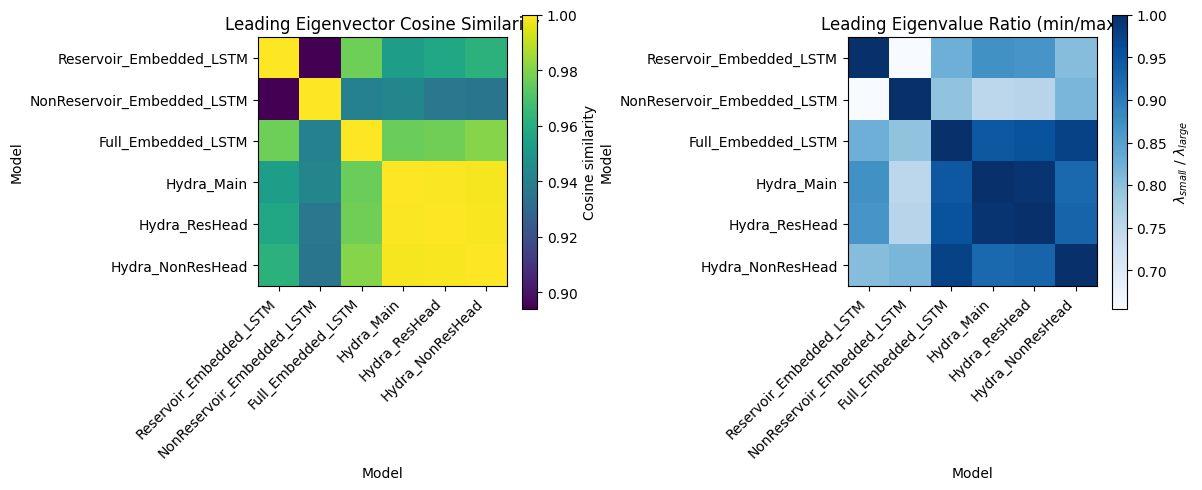

Cosine similarity matrix:
 [[1.         0.89407593 0.97673495 0.95358668 0.9573597  0.96194806]
 [0.89407593 1.         0.94064148 0.94284839 0.93664323 0.93513757]
 [0.97673495 0.94064148 1.         0.97633106 0.97712629 0.98065109]
 [0.95358668 0.94284839 0.97633106 1.         0.99932297 0.99838447]
 [0.9573597  0.93664323 0.97712629 0.99932297 1.         0.99907255]
 [0.96194806 0.93513757 0.98065109 0.99838447 0.99907255 1.        ]]

── Pairwise eigenvector comparison ──


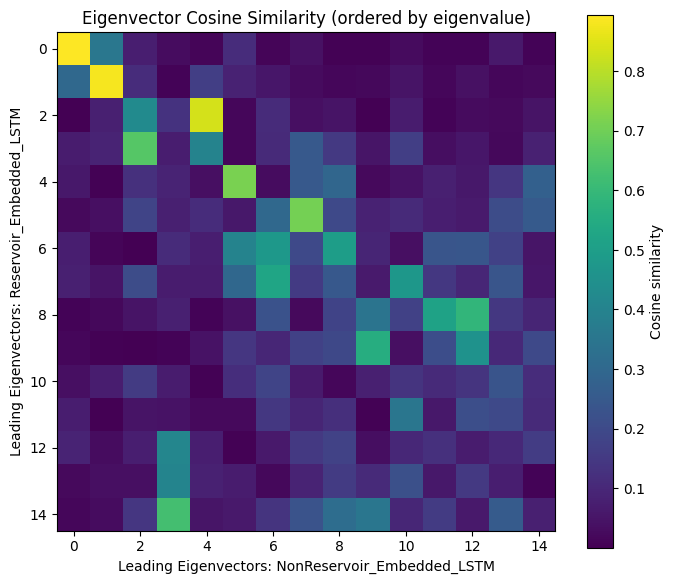


── Eigenvalue spectra ──


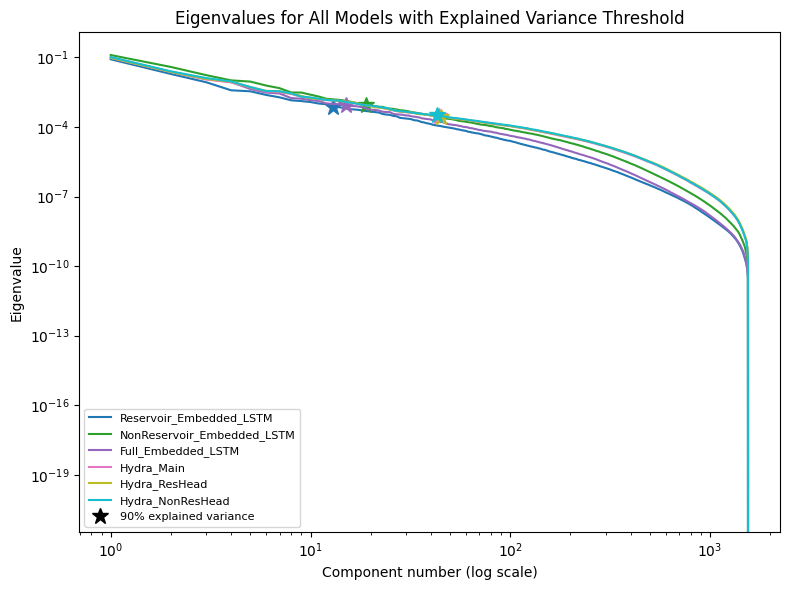


── Wasserstein-1 distance ──


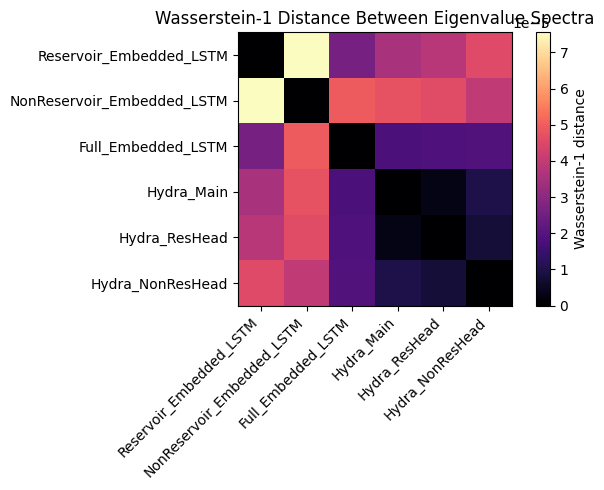

Wasserstein-1 distance matrix:
 [[0.0e+00 7.6e-05 2.6e-05 3.6e-05 3.8e-05 4.5e-05]
 [7.6e-05 0.0e+00 4.9e-05 4.8e-05 4.6e-05 4.0e-05]
 [2.6e-05 4.9e-05 0.0e+00 1.8e-05 1.9e-05 1.9e-05]
 [3.6e-05 4.8e-05 1.8e-05 0.0e+00 3.0e-06 1.0e-05]
 [3.8e-05 4.6e-05 1.9e-05 3.0e-06 0.0e+00 8.0e-06]
 [4.5e-05 4.0e-05 1.9e-05 1.0e-05 8.0e-06 0.0e+00]]

── Projection Frobenius distance ──


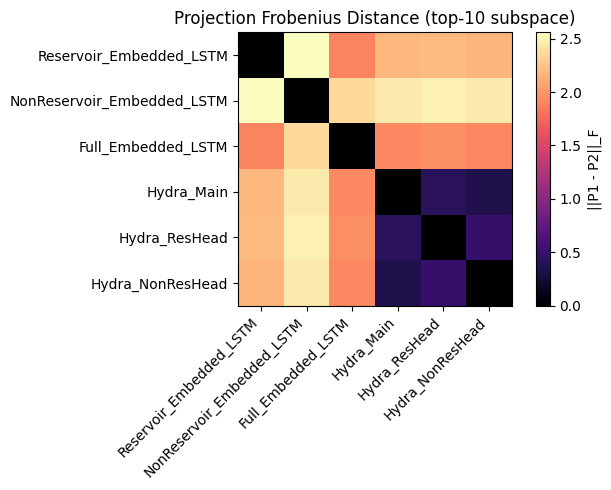

Projection Frobenius distance matrix:
 [[0.     2.5591 1.9036 2.1751 2.199  2.1626]
 [2.5591 0.     2.3643 2.4497 2.4939 2.4517]
 [1.9036 2.3643 0.     1.9229 1.9575 1.9204]
 [2.1751 2.4497 1.9229 0.     0.4107 0.3571]
 [2.199  2.4939 1.9575 0.4107 0.     0.489 ]
 [2.1626 2.4517 1.9204 0.3571 0.489  0.    ]]

── Effective rank ──
Model                            Eff.Rank  50% var  80% var  90% var  95% var  99% var
--------------------------------------------------------------------------------------
Reservoir_Embedded_LSTM              7.12        1        4       13       29      109
NonReservoir_Embedded_LSTM          10.45        2        6       19       48      175
Full_Embedded_LSTM                   8.22        1        5       15       36      134
Hydra_Main                          14.65        2       12       44      103      291
Hydra_ResHead                       15.01        2       12       45      106      298
Hydra_NonResHead                    14.27        2       11

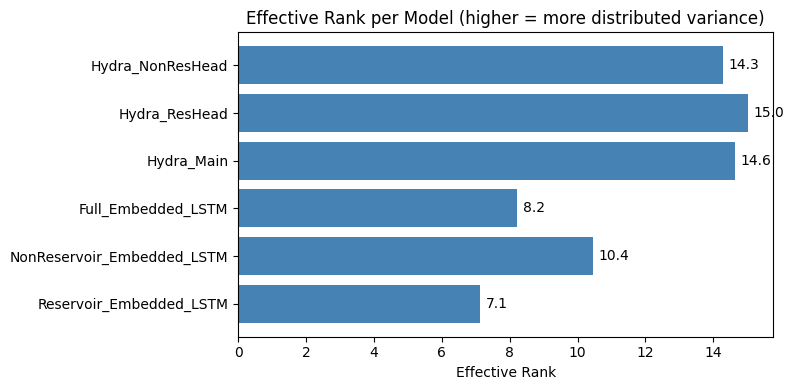


── Normalised dissimilarity summary ──


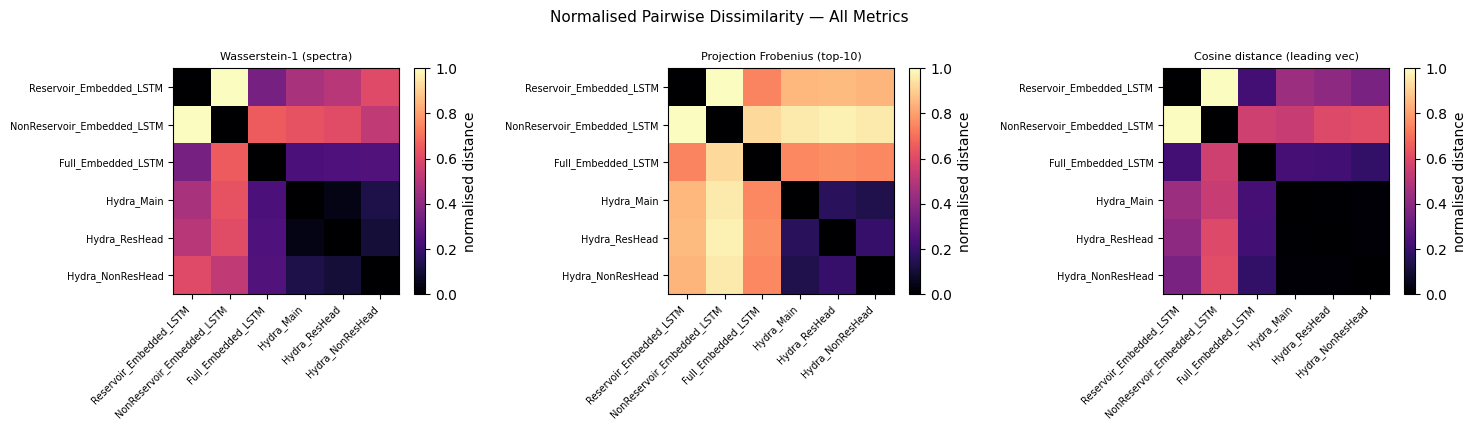

In [40]:
results_res = run_full_analysis(res_df,    k=10, threshold=0.9, compare_pair=(0, 1))


## Non Reservoir

PREPARING DATA
Models found: ['Reservoir_Embedded_LSTM', 'NonReservoir_Embedded_LSTM', 'Full_Embedded_LSTM', 'Hydra_Main', 'Hydra_ResHead', 'Hydra_NonResHead']

── Leading eigenvector analysis ──


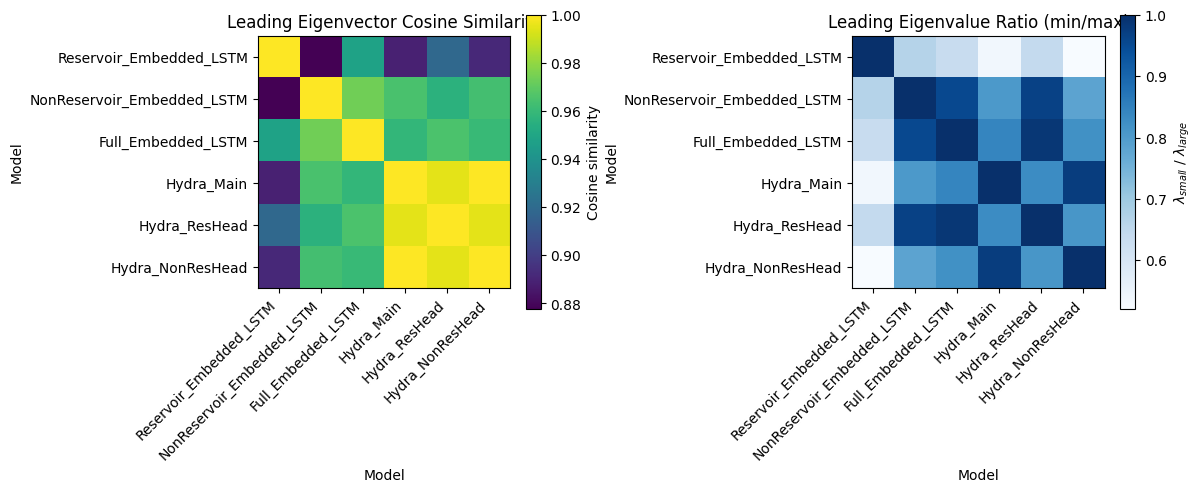

Cosine similarity matrix:
 [[1.         0.87771233 0.94819102 0.88904949 0.91911341 0.89167936]
 [0.87771233 1.         0.97331174 0.96491154 0.95608679 0.96355604]
 [0.94819102 0.97331174 1.         0.95880238 0.96542186 0.95995416]
 [0.88904949 0.96491154 0.95880238 1.         0.99477303 0.99968627]
 [0.91911341 0.95608679 0.96542186 0.99477303 1.         0.9951477 ]
 [0.89167936 0.96355604 0.95995416 0.99968627 0.9951477  1.        ]]

── Pairwise eigenvector comparison ──


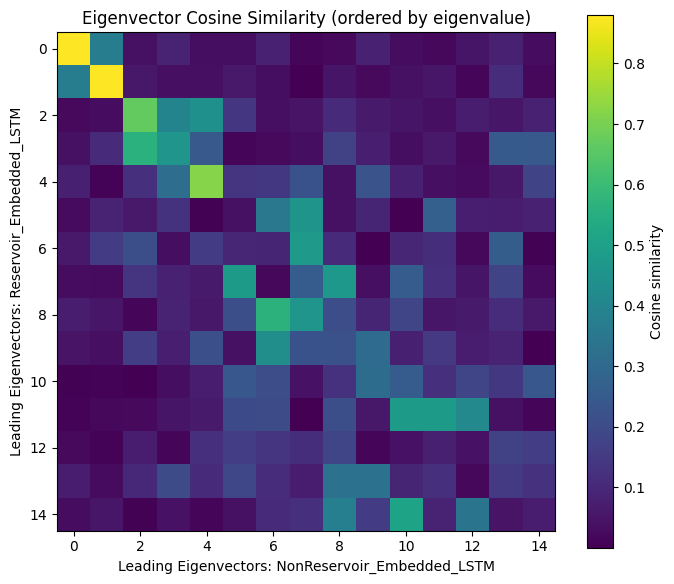


── Eigenvalue spectra ──


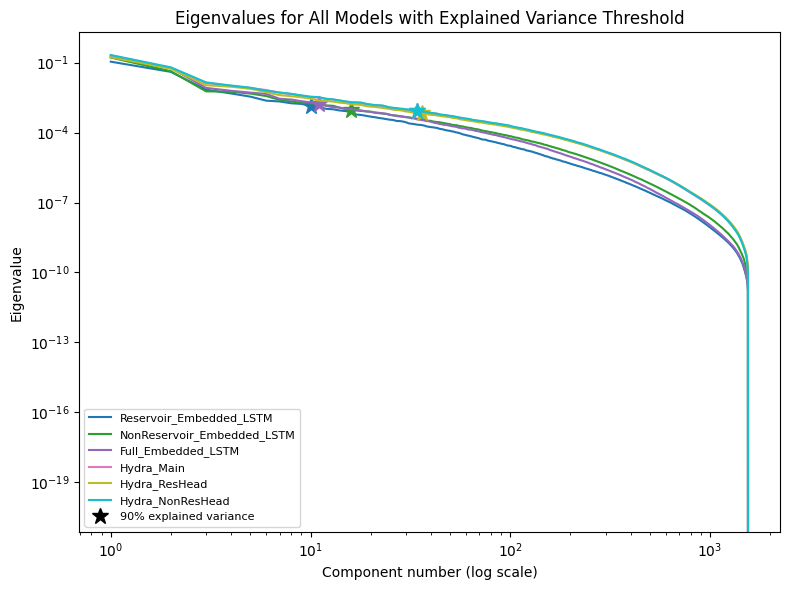


── Wasserstein-1 distance ──


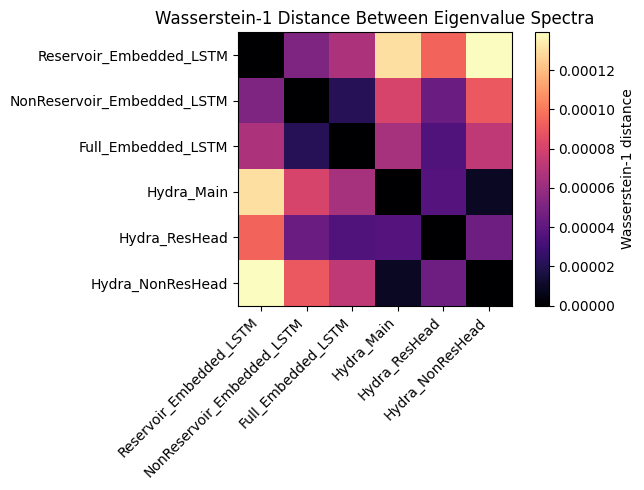

Wasserstein-1 distance matrix:
 [[0.00e+00 5.10e-05 6.70e-05 1.31e-04 9.40e-05 1.39e-04]
 [5.10e-05 0.00e+00 2.20e-05 8.10e-05 4.40e-05 9.00e-05]
 [6.70e-05 2.20e-05 0.00e+00 6.40e-05 3.50e-05 7.30e-05]
 [1.31e-04 8.10e-05 6.40e-05 0.00e+00 3.70e-05 9.00e-06]
 [9.40e-05 4.40e-05 3.50e-05 3.70e-05 0.00e+00 4.60e-05]
 [1.39e-04 9.00e-05 7.30e-05 9.00e-06 4.60e-05 0.00e+00]]

── Projection Frobenius distance ──


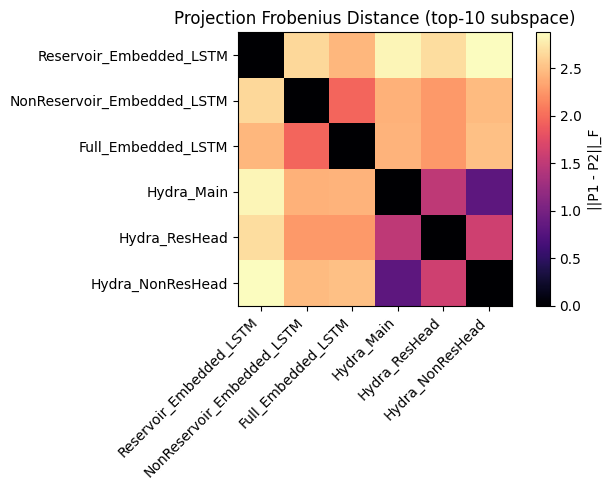

Projection Frobenius distance matrix:
 [[0.     2.6494 2.4387 2.8304 2.679  2.8756]
 [2.6494 0.     1.9537 2.4048 2.2578 2.4705]
 [2.4387 1.9537 0.     2.4165 2.2633 2.5005]
 [2.8304 2.4048 2.4165 0.     1.4983 0.8191]
 [2.679  2.2578 2.2633 1.4983 0.     1.6121]
 [2.8756 2.4705 2.5005 0.8191 1.6121 0.    ]]

── Effective rank ──
Model                            Eff.Rank  50% var  80% var  90% var  95% var  99% var
--------------------------------------------------------------------------------------
Reservoir_Embedded_LSTM              6.15        1        3       10       25       89
NonReservoir_Embedded_LSTM           6.59        1        4       16       40      138
Full_Embedded_LSTM                   6.13        1        3       11       29      105
Hydra_Main                          11.35        1       10       34       74      206
Hydra_ResHead                       11.83        1       10       36       80      221
Hydra_NonResHead                    11.35        1       10

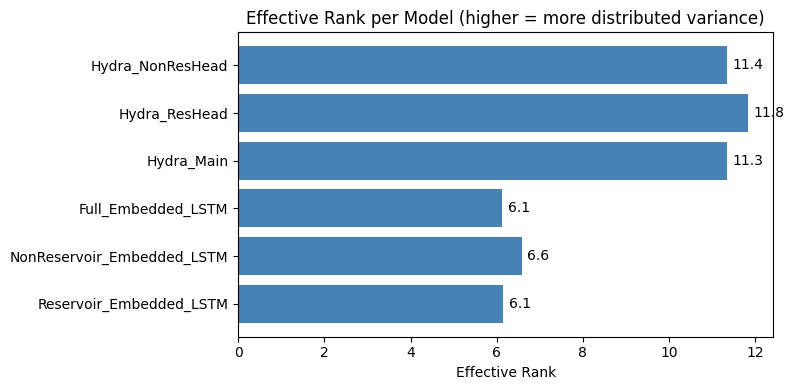


── Normalised dissimilarity summary ──


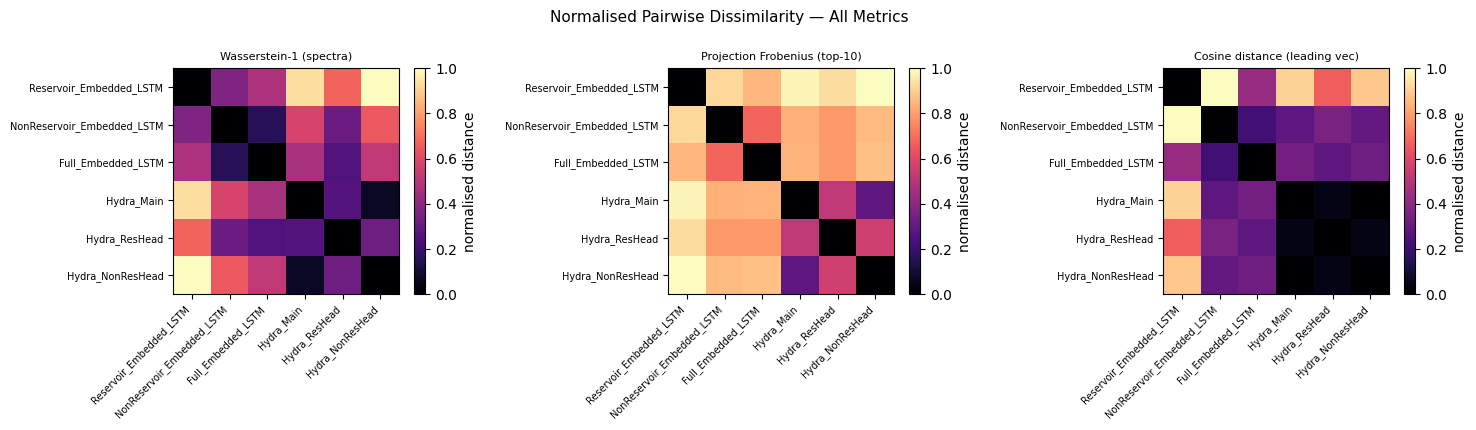

In [41]:
results_nonres = run_full_analysis(nonres_df, k=10, threshold=0.9, compare_pair=(0, 1))

## Aggregated Reservoir

PREPARING DATA
Models found: ['Reservoir_Embedded_LSTM', 'NonReservoir_Embedded_LSTM', 'Full_Embedded_LSTM', 'Hydra_Main', 'Hydra_ResHead', 'Hydra_NonResHead']

── Leading eigenvector analysis ──


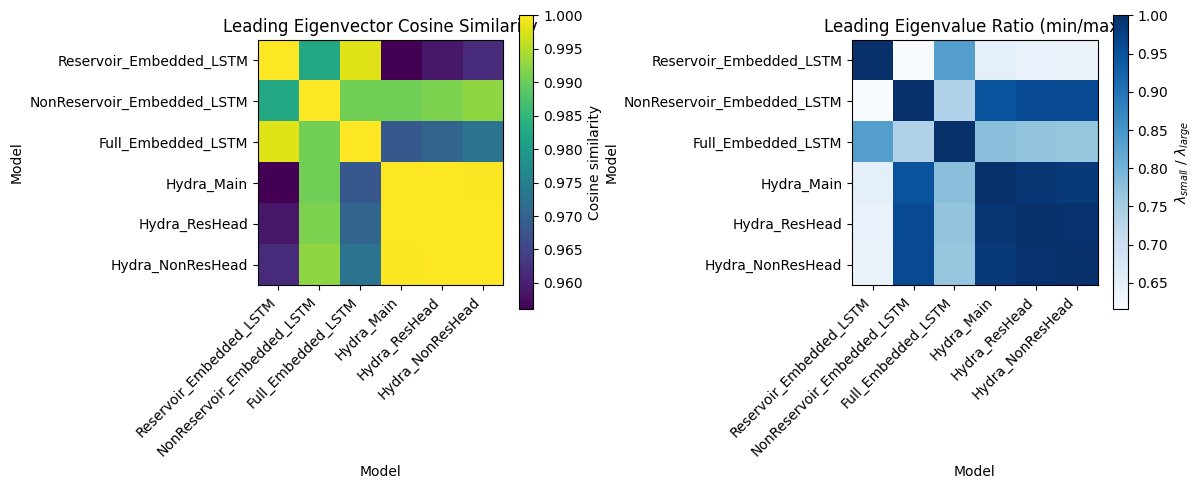

Cosine similarity matrix:
 [[1.         0.98248023 0.99784476 0.95601541 0.95885285 0.96149375]
 [0.98248023 1.         0.99067942 0.99054109 0.99132293 0.9926735 ]
 [0.99784476 0.99067942 1.         0.96813565 0.97039662 0.97277016]
 [0.95601541 0.99054109 0.96813565 1.         0.9999115  0.99977917]
 [0.95885285 0.99132293 0.97039662 0.9999115  1.         0.999924  ]
 [0.96149375 0.9926735  0.97277016 0.99977917 0.999924   1.        ]]

── Pairwise eigenvector comparison ──


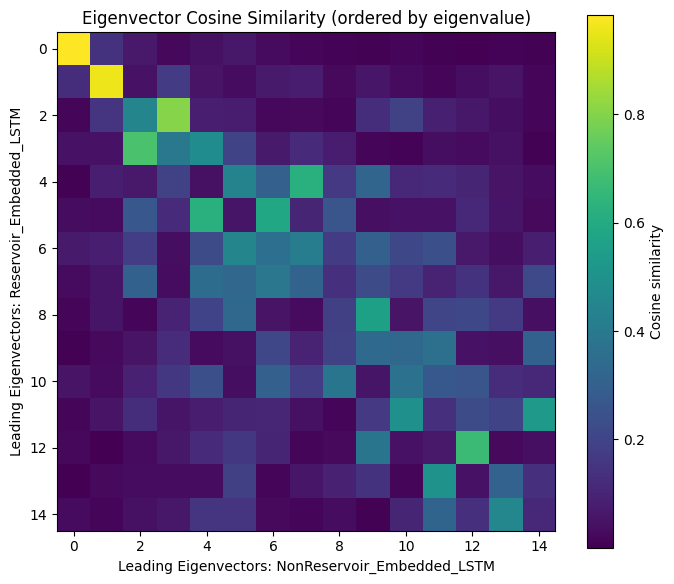


── Eigenvalue spectra ──


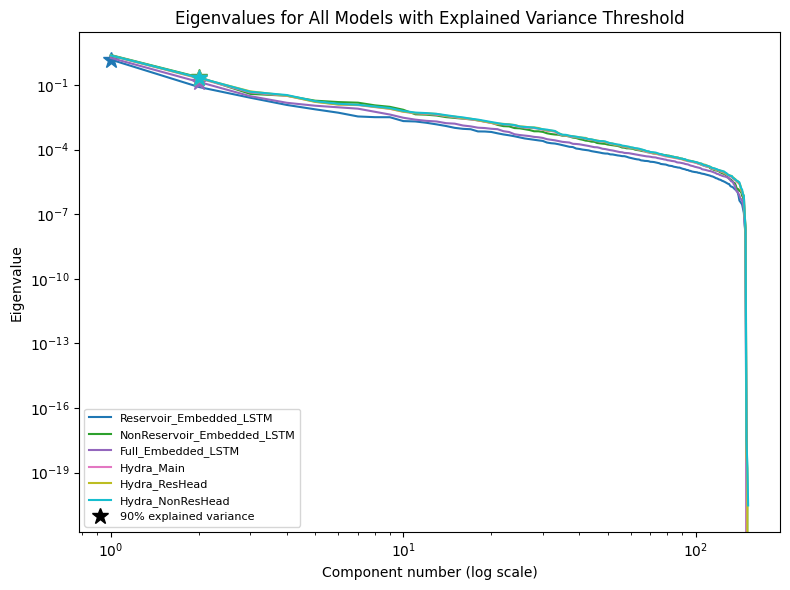


── Wasserstein-1 distance ──


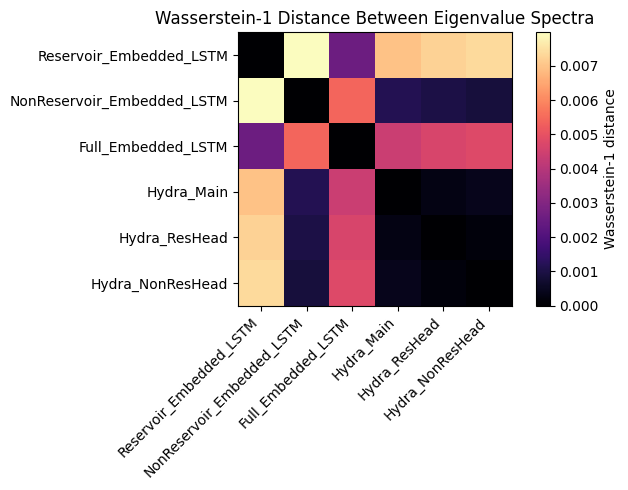

Wasserstein-1 distance matrix:
 [[0.       0.00798  0.002579 0.006966 0.007247 0.007379]
 [0.00798  0.       0.005401 0.001174 0.001001 0.000886]
 [0.002579 0.005401 0.       0.004387 0.004668 0.0048  ]
 [0.006966 0.001174 0.004387 0.       0.000288 0.000413]
 [0.007247 0.001001 0.004668 0.000288 0.       0.000166]
 [0.007379 0.000886 0.0048   0.000413 0.000166 0.      ]]

── Projection Frobenius distance ──


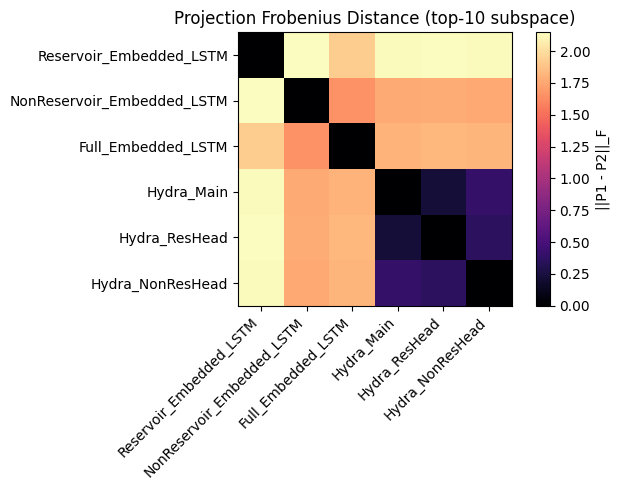

Projection Frobenius distance matrix:
 [[0.     2.147  1.9253 2.1367 2.1452 2.1304]
 [2.147  0.     1.6575 1.7641 1.7741 1.7605]
 [1.9253 1.6575 0.     1.8099 1.8224 1.813 ]
 [2.1367 1.7641 1.8099 0.     0.2245 0.3946]
 [2.1452 1.7741 1.8224 0.2245 0.     0.357 ]
 [2.1304 1.7605 1.813  0.3946 0.357  0.    ]]

── Effective rank ──
Model                            Eff.Rank  50% var  80% var  90% var  95% var  99% var
--------------------------------------------------------------------------------------
Reservoir_Embedded_LSTM              1.67        1        1        1        2       12
NonReservoir_Embedded_LSTM           2.06        1        1        2        4       16
Full_Embedded_LSTM                   1.84        1        1        2        3       13
Hydra_Main                           2.07        1        1        2        4       18
Hydra_ResHead                        2.10        1        1        2        4       19
Hydra_NonResHead                     2.13        1        1

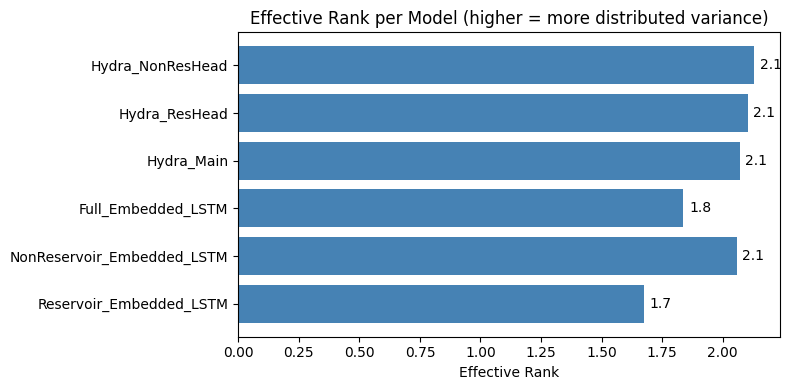


── Normalised dissimilarity summary ──


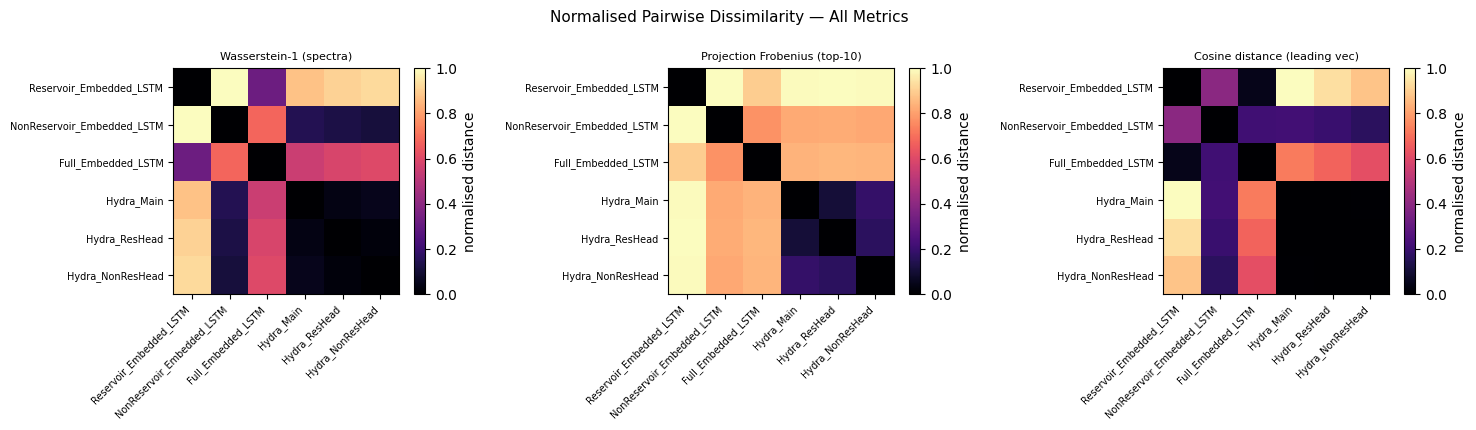

In [42]:
results_res = run_full_analysis(res_df_agg,    k=10, threshold=0.9, compare_pair=(0, 1))


## Aggregated Non Reservoir

## Temporal Reservoir

PREPARING DATA
Models found: ['Reservoir_Embedded_LSTM', 'NonReservoir_Embedded_LSTM', 'Full_Embedded_LSTM', 'Hydra_Main', 'Hydra_ResHead', 'Hydra_NonResHead']

── Leading eigenvector analysis ──


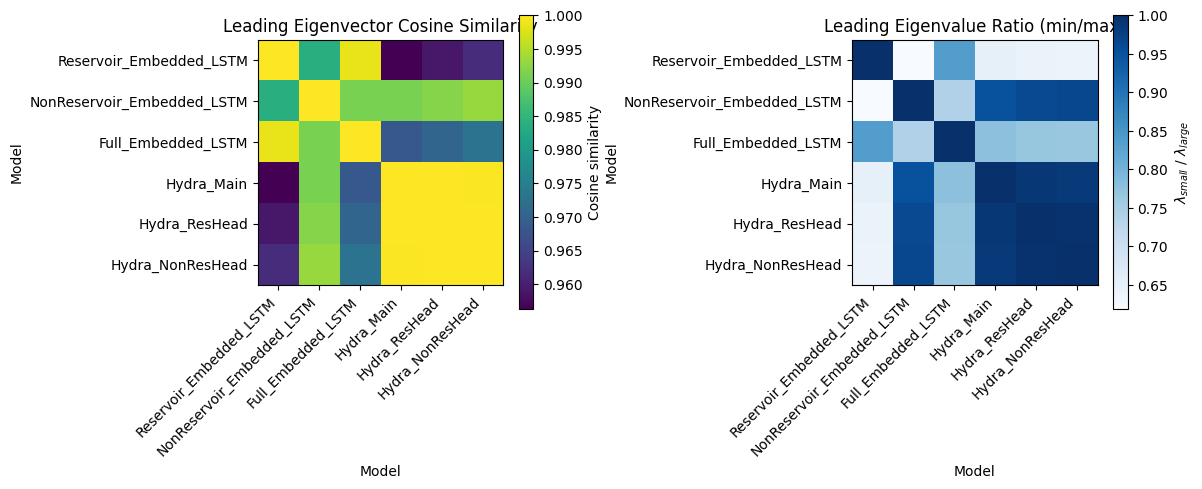

Cosine similarity matrix:
 [[1.         0.98364555 0.99857823 0.95624857 0.95909277 0.96174996]
 [0.98364555 1.         0.9912108  0.99121392 0.99203756 0.99331226]
 [0.99857823 0.9912108  1.         0.96825538 0.97055837 0.97288706]
 [0.95624857 0.99121392 0.96825538 1.         0.9999135  0.99978634]
 [0.95909277 0.99203756 0.97055837 0.9999135  1.         0.99993749]
 [0.96174996 0.99331226 0.97288706 0.99978634 0.99993749 1.        ]]

── Pairwise eigenvector comparison ──


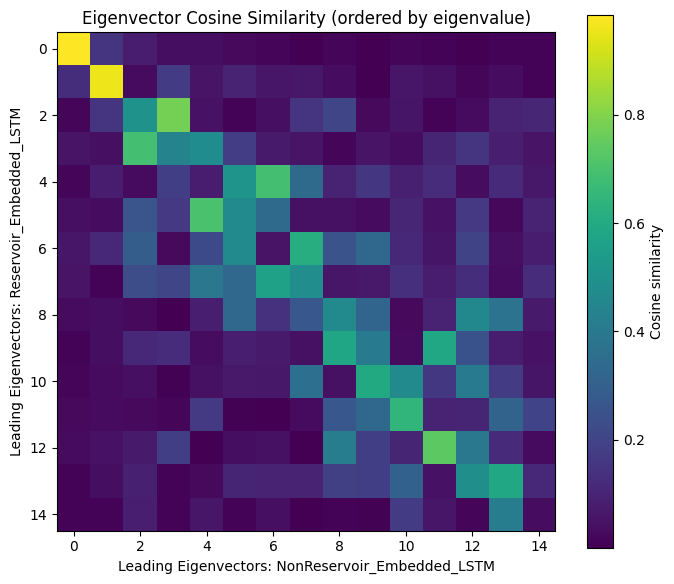


── Eigenvalue spectra ──


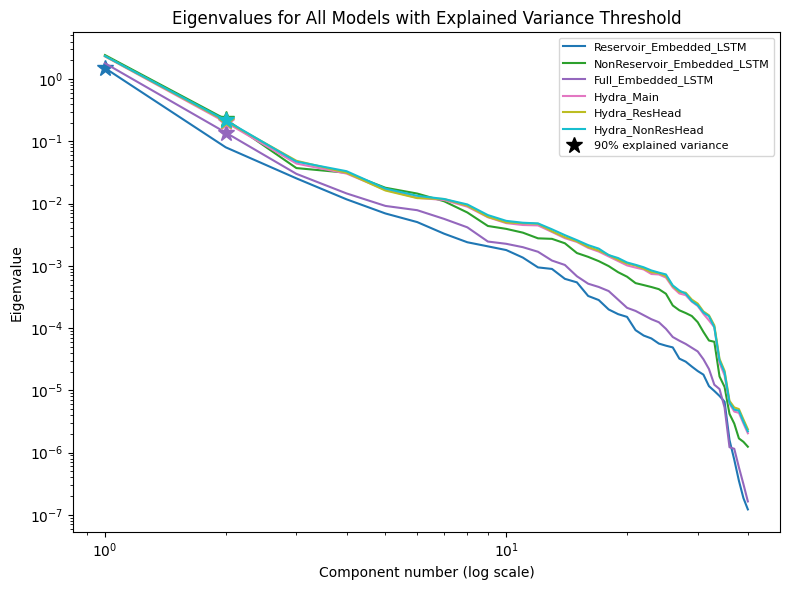


── Wasserstein-1 distance ──


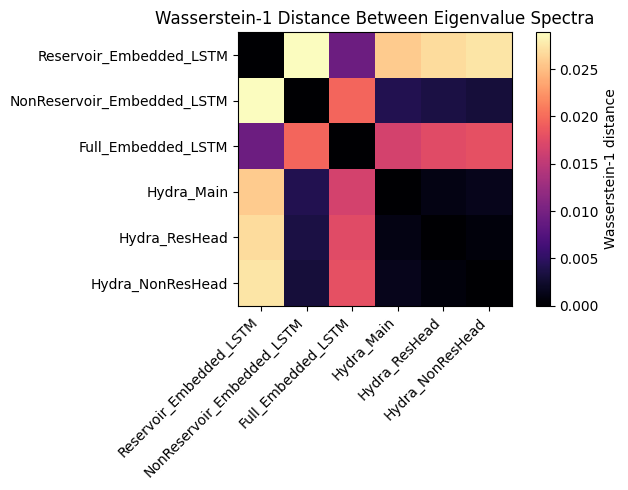

Wasserstein-1 distance matrix:
 [[0.       0.028876 0.009311 0.025785 0.026805 0.027306]
 [0.028876 0.       0.019566 0.004159 0.003506 0.003144]
 [0.009311 0.019566 0.       0.016474 0.017495 0.017996]
 [0.025785 0.004159 0.016474 0.       0.001048 0.001522]
 [0.026805 0.003506 0.017495 0.001048 0.       0.000579]
 [0.027306 0.003144 0.017996 0.001522 0.000579 0.      ]]

── Projection Frobenius distance ──


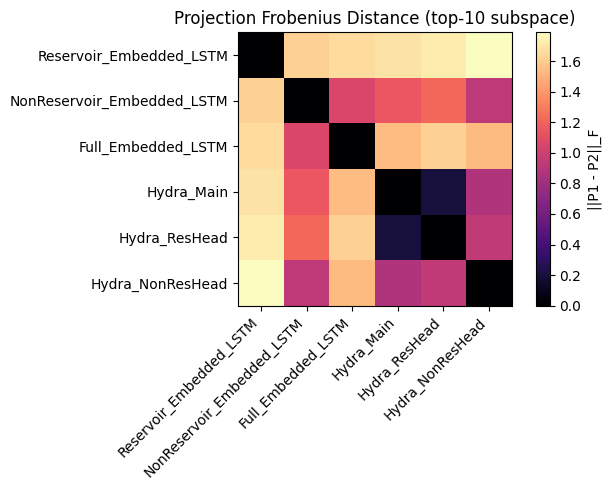

Projection Frobenius distance matrix:
 [[0.     1.6191 1.6602 1.6898 1.7182 1.788 ]
 [1.6191 0.     1.0482 1.1487 1.2164 0.9221]
 [1.6602 1.0482 0.     1.5418 1.6159 1.5354]
 [1.6898 1.1487 1.5418 0.     0.196  0.8672]
 [1.7182 1.2164 1.6159 0.196  0.     0.94  ]
 [1.788  0.9221 1.5354 0.8672 0.94   0.    ]]

── Effective rank ──
Model                            Eff.Rank  50% var  80% var  90% var  95% var  99% var
--------------------------------------------------------------------------------------
Reservoir_Embedded_LSTM              1.55        1        1        1        2        6
NonReservoir_Embedded_LSTM           1.84        1        1        2        3        9
Full_Embedded_LSTM                   1.67        1        1        2        2        7
Hydra_Main                           1.91        1        1        2        3       11
Hydra_ResHead                        1.94        1        1        2        3       12
Hydra_NonResHead                     1.96        1        1

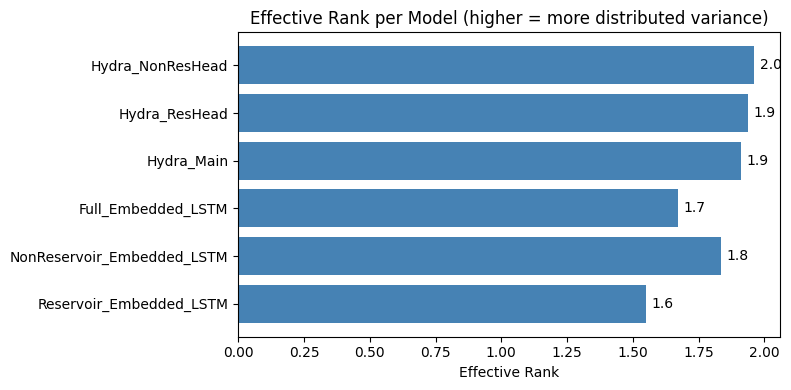


── Normalised dissimilarity summary ──


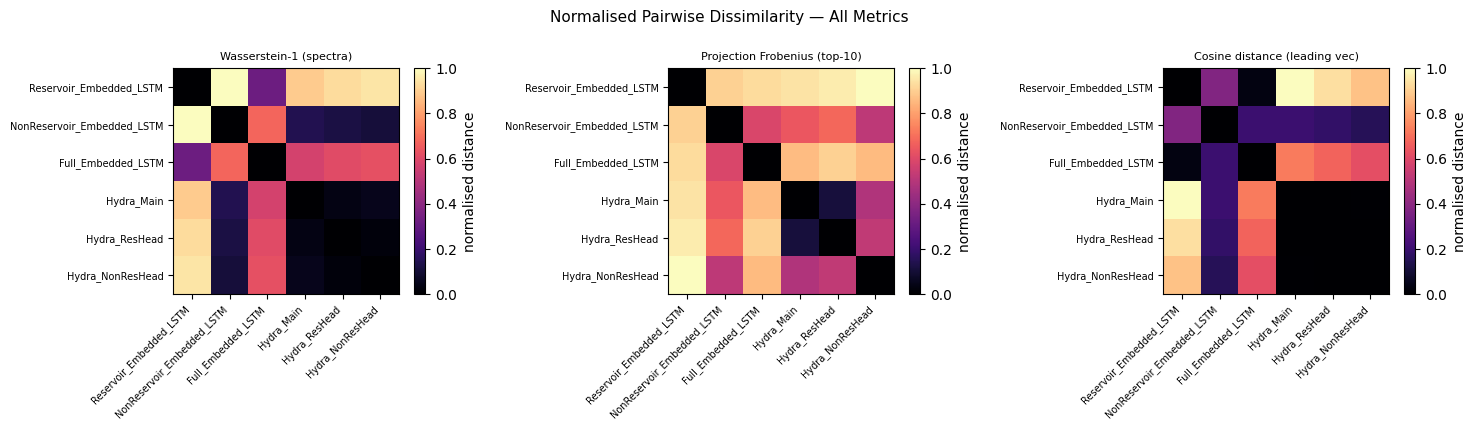

In [43]:
temporal_res_results = run_full_analysis(temporal_res_df, k=10, threshold=0.9, compare_pair=(0, 1))

## Static Reservoir

PREPARING DATA
Models found: ['Reservoir_Embedded_LSTM', 'NonReservoir_Embedded_LSTM', 'Full_Embedded_LSTM', 'Hydra_Main', 'Hydra_ResHead', 'Hydra_NonResHead']

── Leading eigenvector analysis ──


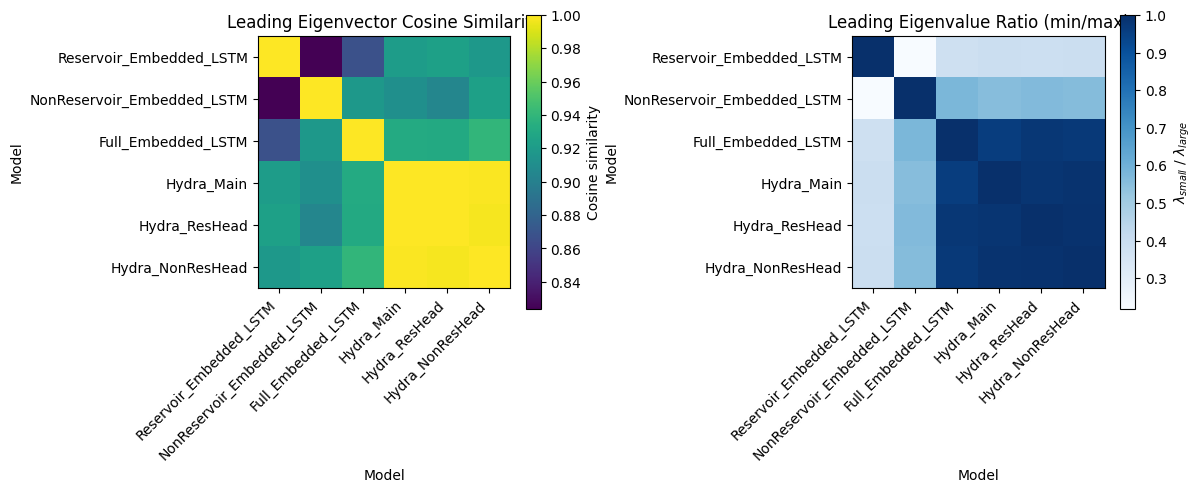

Cosine similarity matrix:
 [[1.         0.82371351 0.86773332 0.92129398 0.92403228 0.91742617]
 [0.82371351 1.         0.91783722 0.91149033 0.90467402 0.92381848]
 [0.86773332 0.91783722 1.         0.93174805 0.93077412 0.93956552]
 [0.92129398 0.91149033 0.93174805 1.         0.99933583 0.99876152]
 [0.92403228 0.90467402 0.93077412 0.99933583 1.         0.99730541]
 [0.91742617 0.92381848 0.93956552 0.99876152 0.99730541 1.        ]]

── Pairwise eigenvector comparison ──


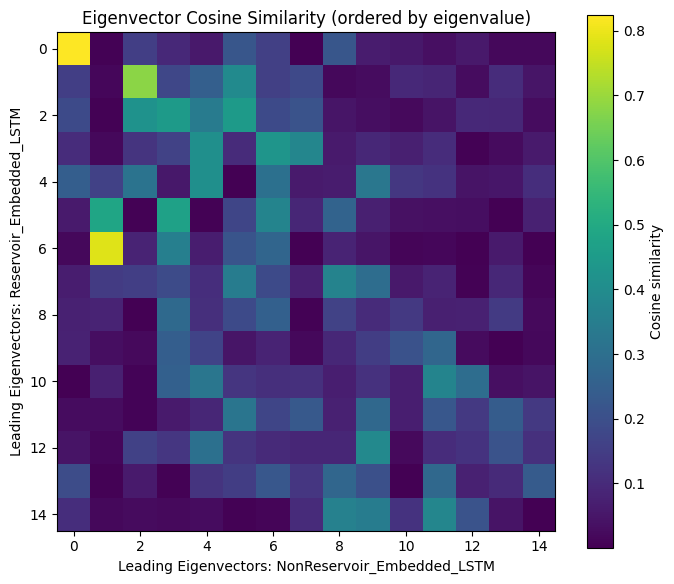


── Eigenvalue spectra ──


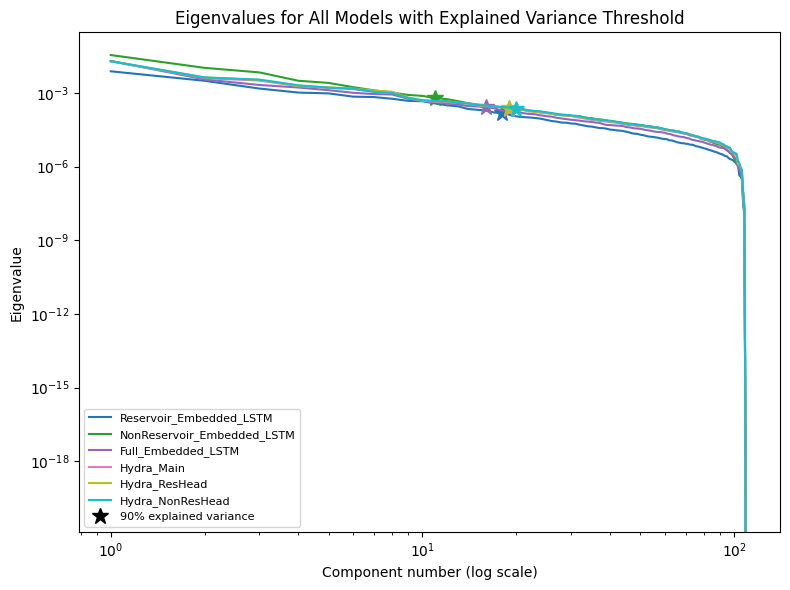


── Wasserstein-1 distance ──


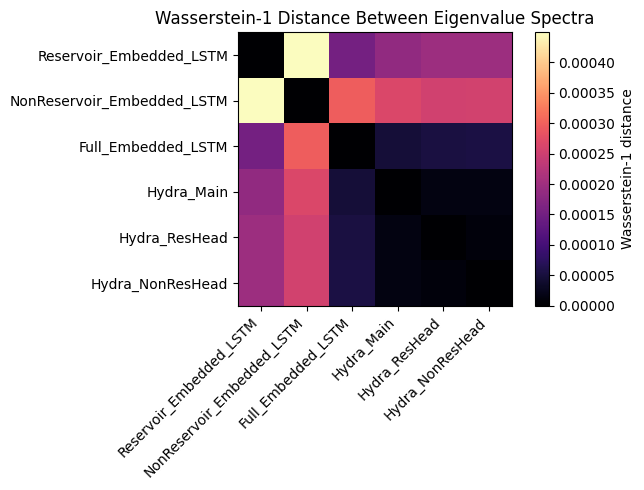

Wasserstein-1 distance matrix:
 [[0.00e+00 4.50e-04 1.53e-04 1.84e-04 1.98e-04 1.98e-04]
 [4.50e-04 0.00e+00 2.96e-04 2.66e-04 2.54e-04 2.55e-04]
 [1.53e-04 2.96e-04 0.00e+00 4.60e-05 5.40e-05 5.60e-05]
 [1.84e-04 2.66e-04 4.60e-05 0.00e+00 1.40e-05 1.40e-05]
 [1.98e-04 2.54e-04 5.40e-05 1.40e-05 0.00e+00 9.00e-06]
 [1.98e-04 2.55e-04 5.60e-05 1.40e-05 9.00e-06 0.00e+00]]

── Projection Frobenius distance ──


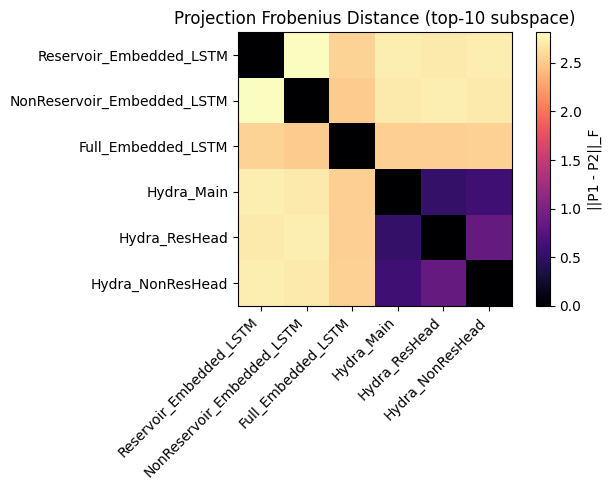

Projection Frobenius distance matrix:
 [[0.     2.815  2.5527 2.7186 2.7036 2.72  ]
 [2.815  0.     2.5141 2.7036 2.7216 2.7006]
 [2.5527 2.5141 0.     2.5384 2.5366 2.5447]
 [2.7186 2.7036 2.5384 0.     0.5254 0.6029]
 [2.7036 2.7216 2.5366 0.5254 0.     0.8526]
 [2.72   2.7006 2.5447 0.6029 0.8526 0.    ]]

── Effective rank ──
Model                            Eff.Rank  50% var  80% var  90% var  95% var  99% var
--------------------------------------------------------------------------------------
Reservoir_Embedded_LSTM             13.95        2       10       18       31       63
NonReservoir_Embedded_LSTM           8.10        2        5       11       23       57
Full_Embedded_LSTM                   9.04        1        7       16       28       62
Hydra_Main                          11.15        2        8       19       33       67
Hydra_ResHead                       11.42        2        8       19       33       67
Hydra_NonResHead                    11.58        2        8

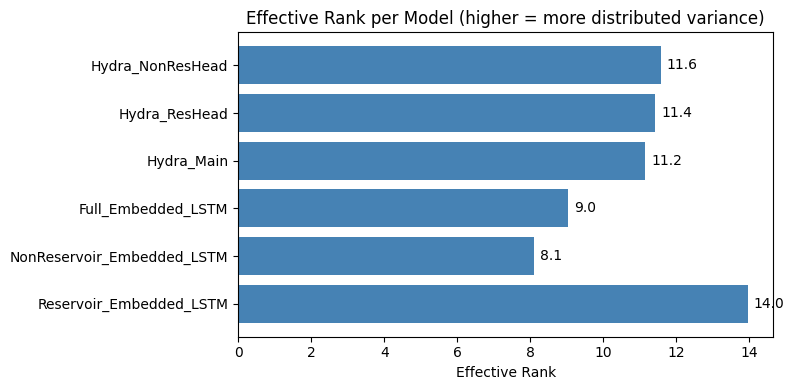


── Normalised dissimilarity summary ──


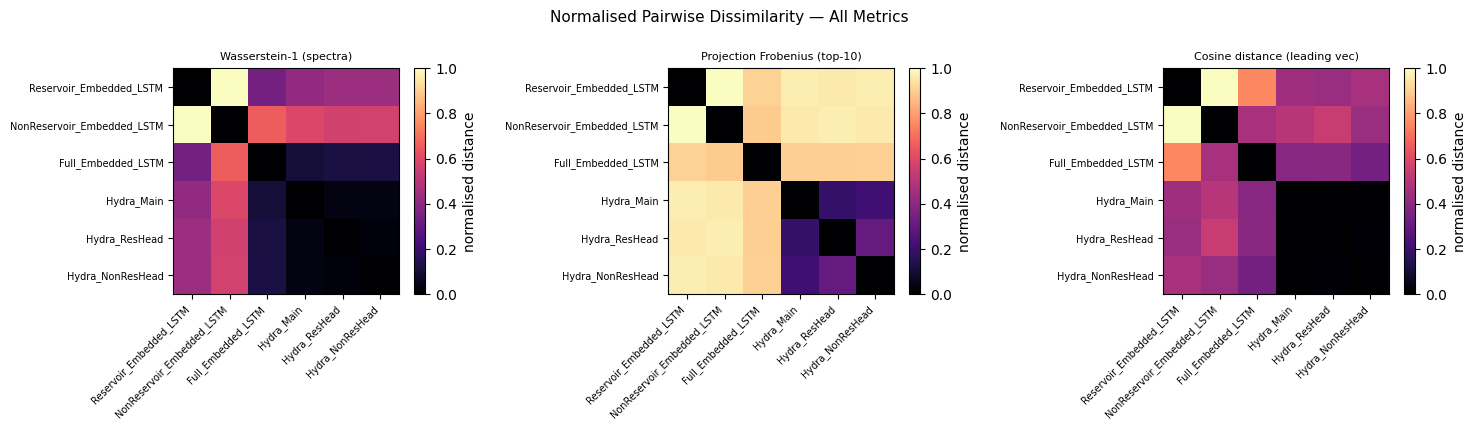

In [44]:
static_res_results = run_full_analysis(static_res_df, k=10, threshold=0.9, compare_pair=(0, 1))

## Temporal Non Reservoir

PREPARING DATA
Models found: ['Reservoir_Embedded_LSTM', 'NonReservoir_Embedded_LSTM', 'Full_Embedded_LSTM', 'Hydra_Main', 'Hydra_ResHead', 'Hydra_NonResHead']

── Leading eigenvector analysis ──


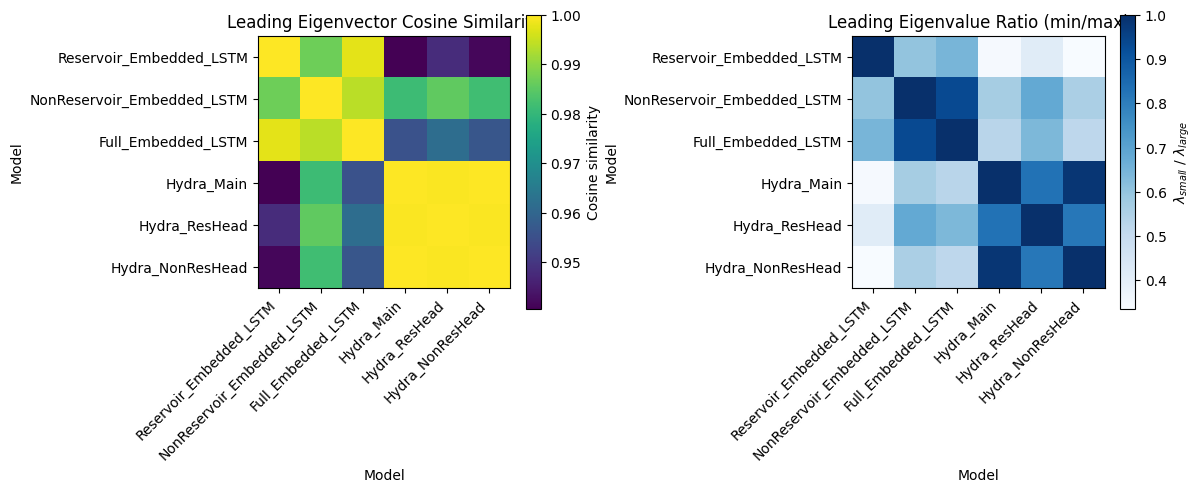

Cosine similarity matrix:
 [[1.         0.98694411 0.99755887 0.9405138  0.94814398 0.94146311]
 [0.98694411 1.         0.99386855 0.98125415 0.98538313 0.9816814 ]
 [0.99755887 0.99386855 1.         0.95558082 0.96188005 0.95636959]
 [0.9405138  0.98125415 0.95558082 1.         0.9996655  0.99998559]
 [0.94814398 0.98538313 0.96188005 0.9996655  1.         0.99969747]
 [0.94146311 0.9816814  0.95636959 0.99998559 0.99969747 1.        ]]

── Pairwise eigenvector comparison ──


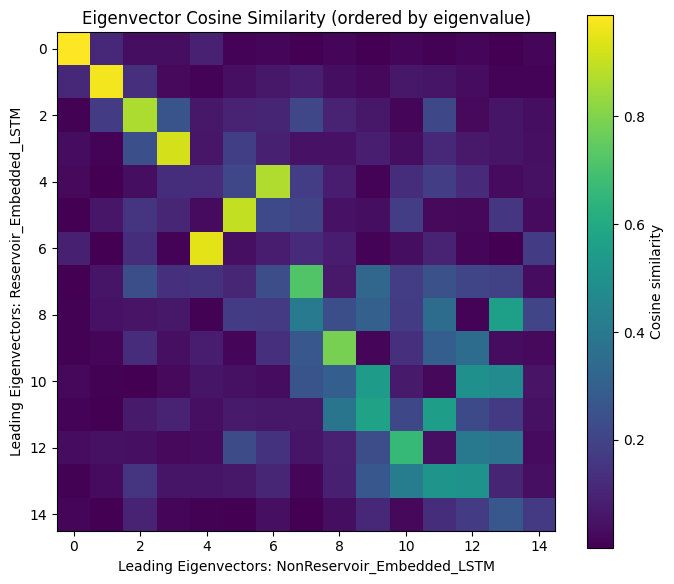


── Eigenvalue spectra ──


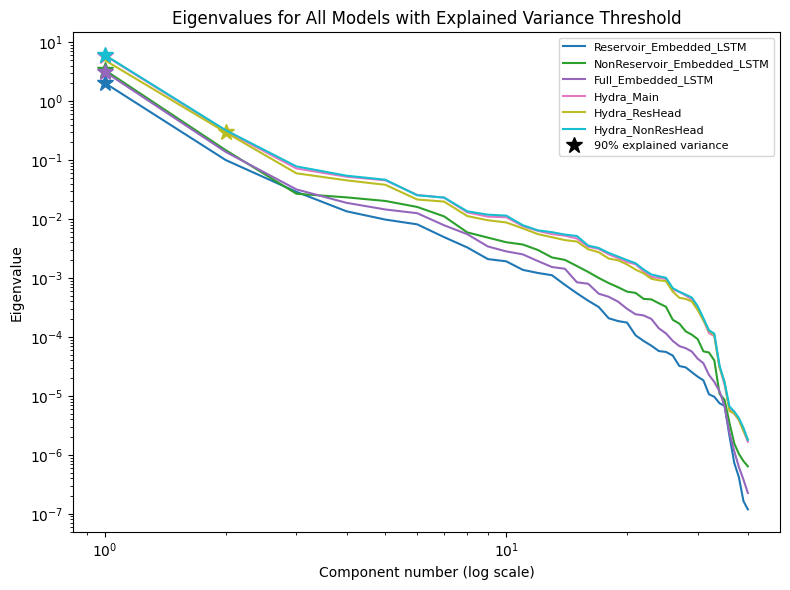


── Wasserstein-1 distance ──


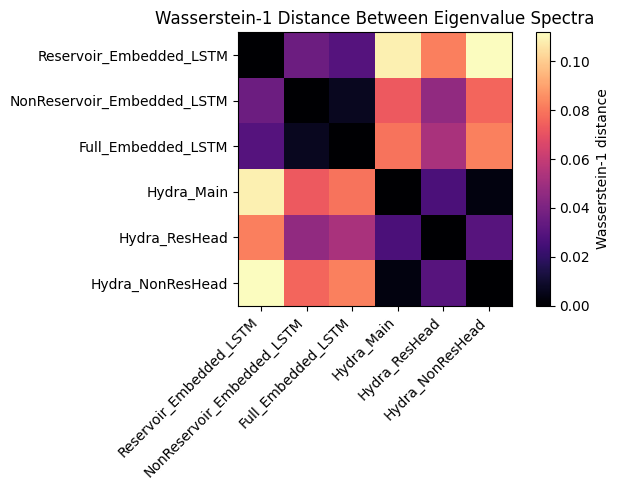

Wasserstein-1 distance matrix:
 [[0.       0.036009 0.029494 0.108674 0.081958 0.111872]
 [0.036009 0.       0.006658 0.07277  0.046054 0.075968]
 [0.029494 0.006658 0.       0.07918  0.052464 0.082378]
 [0.108674 0.07277  0.07918  0.       0.026717 0.003216]
 [0.081958 0.046054 0.052464 0.026717 0.       0.029915]
 [0.111872 0.075968 0.082378 0.003216 0.029915 0.      ]]

── Projection Frobenius distance ──


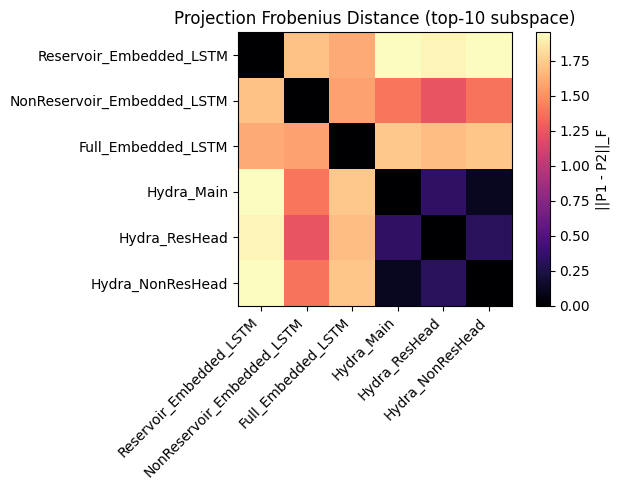

Projection Frobenius distance matrix:
 [[0.     1.7068 1.6048 1.9525 1.9207 1.9527]
 [1.7068 0.     1.5703 1.3999 1.2416 1.3859]
 [1.6048 1.5703 0.     1.7314 1.6888 1.7214]
 [1.9525 1.3999 1.7314 0.     0.3381 0.119 ]
 [1.9207 1.2416 1.6888 0.3381 0.     0.3159]
 [1.9527 1.3859 1.7214 0.119  0.3159 0.    ]]

── Effective rank ──
Model                            Eff.Rank  50% var  80% var  90% var  95% var  99% var
--------------------------------------------------------------------------------------
Reservoir_Embedded_LSTM              1.51        1        1        1        2        6
NonReservoir_Embedded_LSTM           1.51        1        1        1        2        7
Full_Embedded_LSTM                   1.47        1        1        1        2        6
Hydra_Main                           1.63        1        1        1        2        9
Hydra_ResHead                        1.67        1        1        2        2        9
Hydra_NonResHead                     1.65        1        1

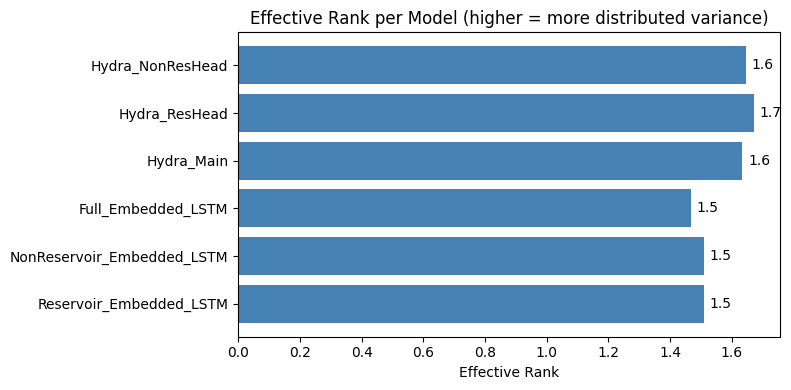


── Normalised dissimilarity summary ──


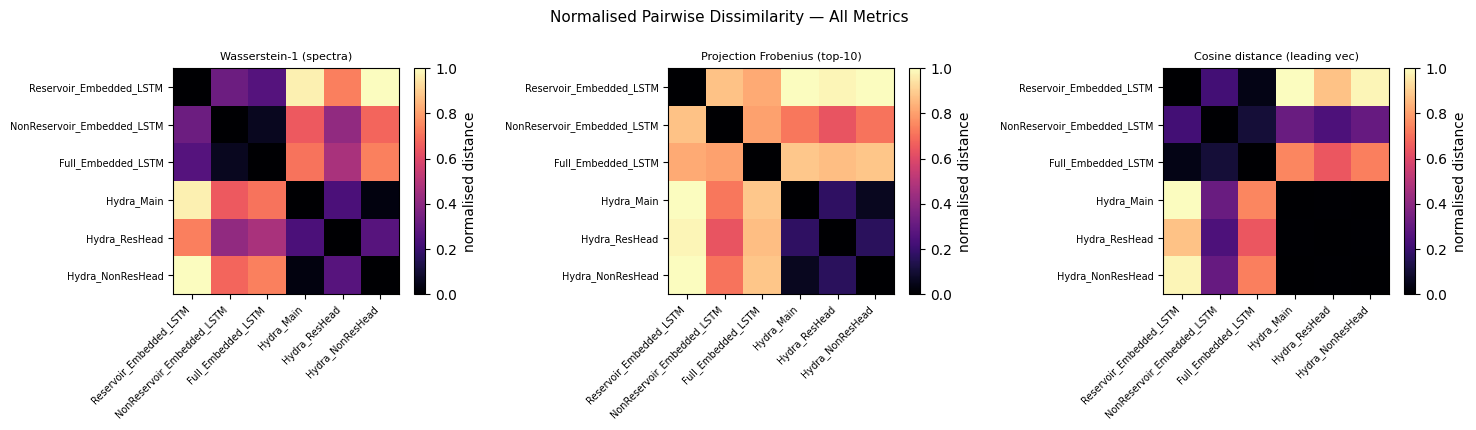

In [45]:
temporal_nonres_results = run_full_analysis(temporal_nonres_df, k=10, threshold=0.9, compare_pair=(0, 1))

## Static Non Reservoir

PREPARING DATA
Models found: ['Reservoir_Embedded_LSTM', 'NonReservoir_Embedded_LSTM', 'Full_Embedded_LSTM', 'Hydra_Main', 'Hydra_ResHead', 'Hydra_NonResHead']

── Leading eigenvector analysis ──


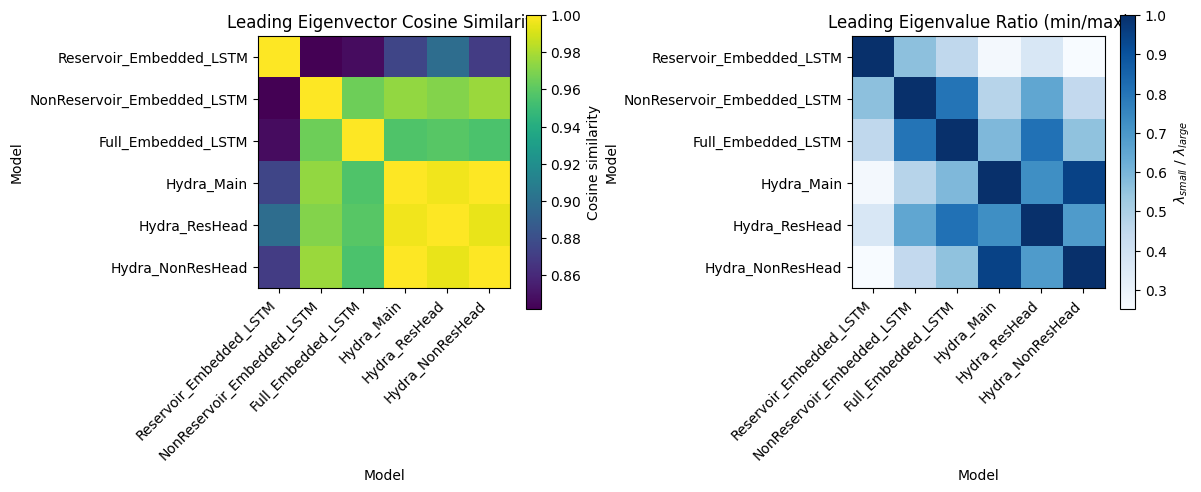

Cosine similarity matrix:
 [[1.         0.84193564 0.84740104 0.87481422 0.89869759 0.86974487]
 [0.84193564 1.         0.96531801 0.97412442 0.97072068 0.97638803]
 [0.84740104 0.96531801 1.         0.95649526 0.95880038 0.9550641 ]
 [0.87481422 0.97412442 0.95649526 1.         0.9964369  0.9994427 ]
 [0.89869759 0.97072068 0.95880038 0.9964369  1.         0.99491205]
 [0.86974487 0.97638803 0.9550641  0.9994427  0.99491205 1.        ]]

── Pairwise eigenvector comparison ──


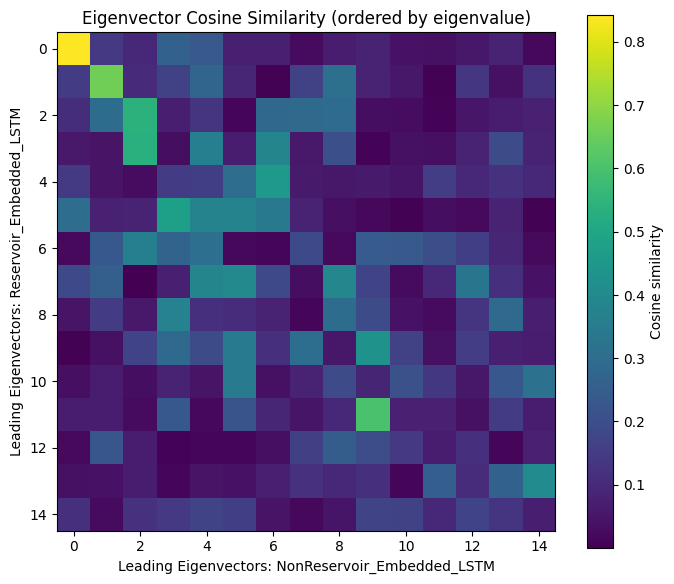


── Eigenvalue spectra ──


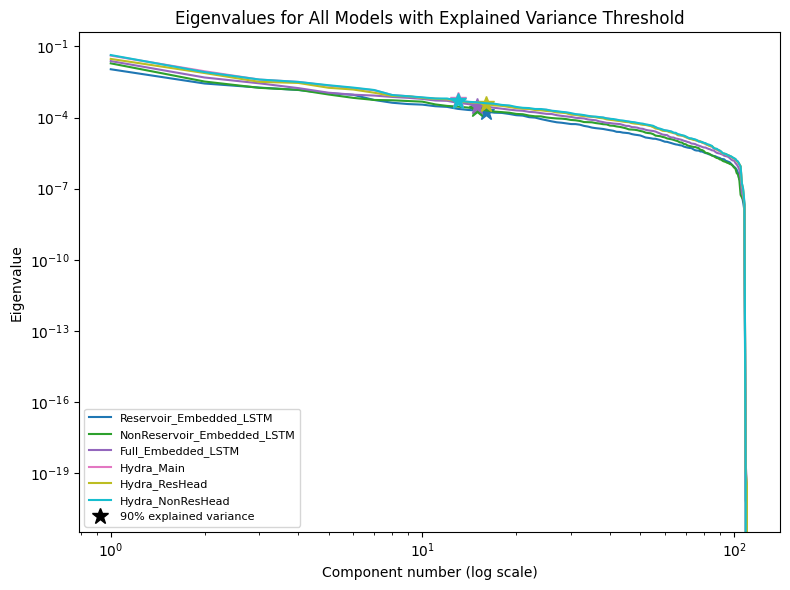


── Wasserstein-1 distance ──


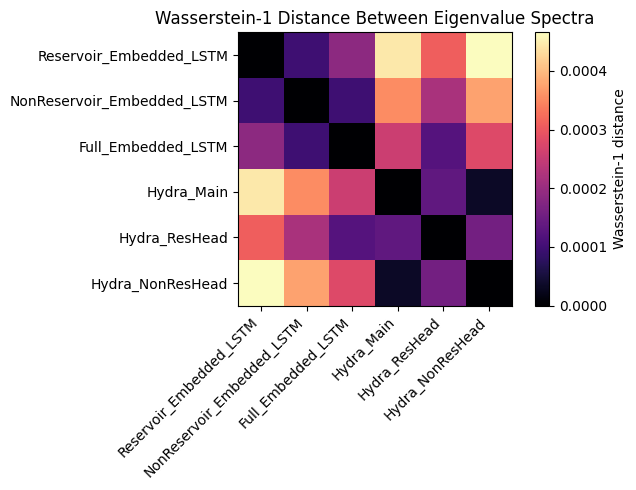

Wasserstein-1 distance matrix:
 [[0.00e+00 9.80e-05 1.87e-04 4.45e-04 3.09e-04 4.66e-04]
 [9.80e-05 0.00e+00 9.70e-05 3.54e-04 2.19e-04 3.75e-04]
 [1.87e-04 9.70e-05 0.00e+00 2.58e-04 1.22e-04 2.79e-04]
 [4.45e-04 3.54e-04 2.58e-04 0.00e+00 1.36e-04 3.40e-05]
 [3.09e-04 2.19e-04 1.22e-04 1.36e-04 0.00e+00 1.56e-04]
 [4.66e-04 3.75e-04 2.79e-04 3.40e-05 1.56e-04 0.00e+00]]

── Projection Frobenius distance ──


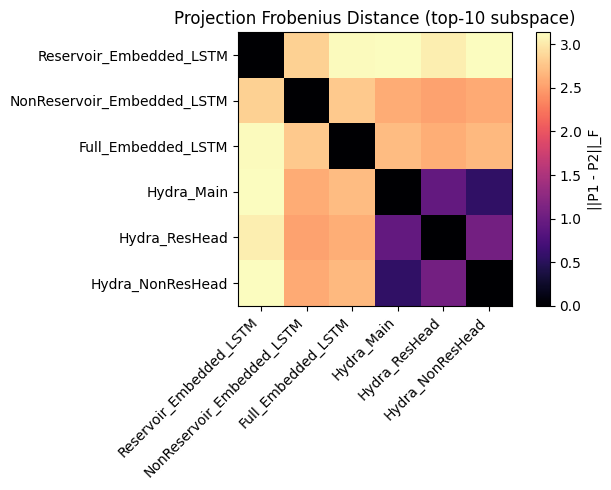

Projection Frobenius distance matrix:
 [[0.     2.8353 3.1216 3.1379 3.0308 3.1279]
 [2.8353 0.     2.7843 2.5905 2.5284 2.5773]
 [3.1216 2.7843 0.     2.7035 2.6038 2.6811]
 [3.1379 2.5905 2.7035 0.     0.9386 0.5546]
 [3.0308 2.5284 2.6038 0.9386 0.     1.0552]
 [3.1279 2.5773 2.6811 0.5546 1.0552 0.    ]]

── Effective rank ──
Model                            Eff.Rank  50% var  80% var  90% var  95% var  99% var
--------------------------------------------------------------------------------------
Reservoir_Embedded_LSTM             10.48        2        7       16       25       53
NonReservoir_Embedded_LSTM           7.74        1        6       15       26       52
Full_Embedded_LSTM                   8.37        1        7       15       26       53
Hydra_Main                           7.35        1        5       13       24       52
Hydra_ResHead                        8.86        1        7       16       27       55
Hydra_NonResHead                     7.20        1        5

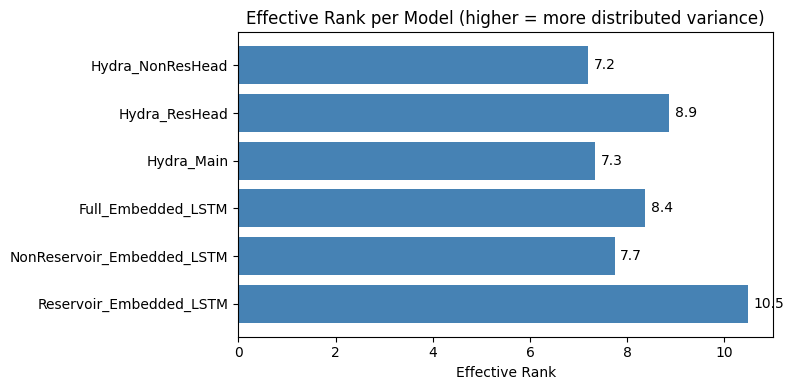


── Normalised dissimilarity summary ──


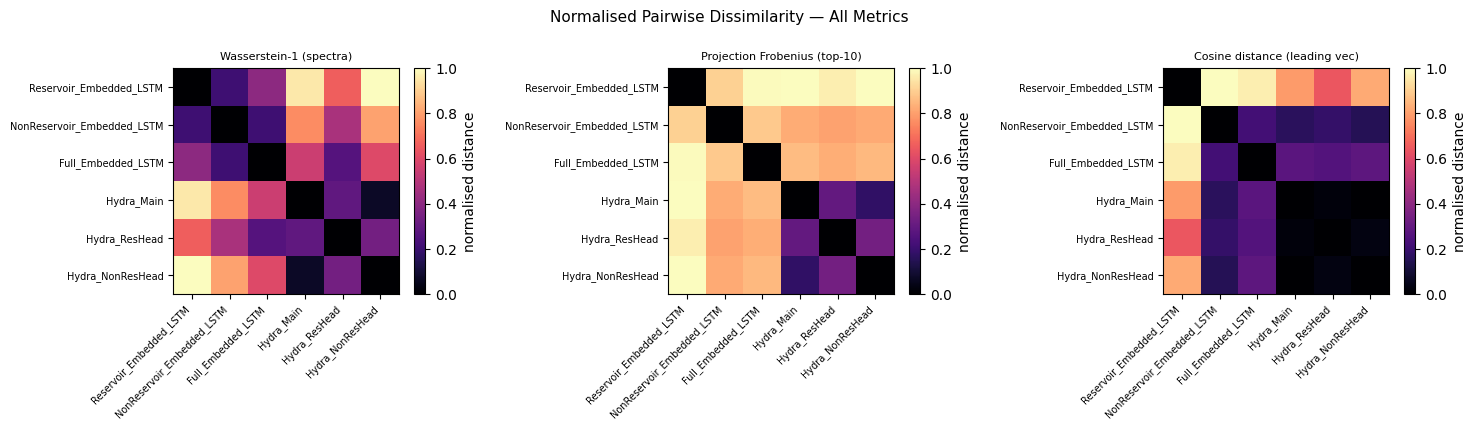

In [46]:
static_nonres_results = run_full_analysis(static_nonres_df, k=10, threshold=0.9, compare_pair=(0, 1))

# What are the eigenvectors?

In [47]:
def show_leading_eigenvectors(cov_list, models, feature_names, top_n=10, plot=True):
    """
    For each model, extract the leading eigenvector and display the features
    with the largest absolute loadings.

    Parameters
    ----------
    cov_list      : list[np.ndarray]   – from prepare_analysis()
    models        : list[str]
    feature_names : list[str]          – column names from df.iloc[:, 2:].columns
    top_n         : int                – how many top loadings to show
    plot          : bool               – also draw a bar chart per model
    """
    feature_names = list(feature_names)

    all_rows = []  # for the printed summary

    for model, cov in zip(models, cov_list):
        vals, vecs = np.linalg.eigh(cov)
        idx = np.argmax(vals)
        v = vecs[:, idx]
        v = v / np.linalg.norm(v)          # unit vector
        abs_loadings = np.abs(v)

        top_idx = np.argsort(abs_loadings)[::-1][:top_n]
        top_features = [feature_names[i] for i in top_idx]
        top_loadings = v[top_idx]           # signed, so you can see direction
        top_abs     = abs_loadings[top_idx]

        # ── printed table ──────────────────────────────────────────────────
        print(f"\n{'='*55}")
        print(f"  {model}  |  leading eigenvalue: {vals[idx]:.4g}")
        print(f"{'='*55}")
        print(f"  {'Feature':<30}  {'Loading':>9}  {'|Loading|':>9}")
        print(f"  {'-'*30}  {'-'*9}  {'-'*9}")
        for feat, load, aload in zip(top_features, top_loadings, top_abs):
            print(f"  {feat:<30}  {load:>+9.4f}  {aload:>9.4f}")

        all_rows.append((model, top_features, top_loadings, top_abs, vals[idx]))

        # ── bar chart ──────────────────────────────────────────────────────
        if plot:
            colors = ["steelblue" if l >= 0 else "tomato" for l in top_loadings]
            fig, ax = plt.subplots(figsize=(7, max(3, top_n * 0.35)))
            ax.barh(top_features[::-1], top_loadings[::-1], color=colors[::-1])
            ax.axvline(0, color="black", linewidth=0.8)
            ax.set_xlabel("Loading (signed)")
            ax.set_title(f"Leading eigenvector — {model}\n"
                         f"(λ = {vals[idx]:.4g})")
            plt.tight_layout()
            plt.show()

    return all_rows


  Reservoir_Embedded_LSTM  |  leading eigenvalue: 0.08344
  Feature                           Loading  |Loading|
  ------------------------------  ---------  ---------
  temporal__precipitation_haduk_day_88    +0.6347     0.6347
  temporal__precipitation_cehgear_day_88    +0.5117     0.5117
  temporal__precipitation_day_88    +0.3583     0.3583
  temporal__precipitation_haduk_day_89    +0.1728     0.1728
  temporal__precipitation_day_89    +0.1724     0.1724
  temporal__precipitation_cehgear_day_89    +0.1178     0.1178
  temporal__precipitation_haduk_day_87    +0.1088     0.1088
  temporal__longwave_rad_day_89     +0.1075     0.1075
  temporal__windspeed_day_89        +0.0975     0.0975
  temporal__precipitation_day_87    +0.0933     0.0933


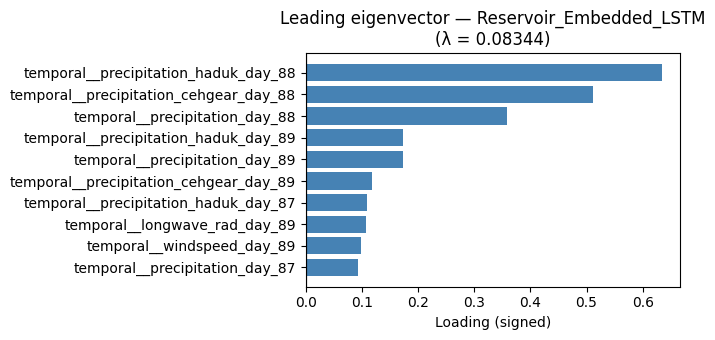


  NonReservoir_Embedded_LSTM  |  leading eigenvalue: 0.1274
  Feature                           Loading  |Loading|
  ------------------------------  ---------  ---------
  temporal__precipitation_haduk_day_88    +0.4411     0.4411
  temporal__precipitation_day_88    +0.3717     0.3717
  temporal__precipitation_cehgear_day_88    +0.3412     0.3412
  temporal__precipitation_day_89    +0.3001     0.3001
  temporal__precipitation_cehgear_day_89    +0.2888     0.2888
  static__inwater_perc_1990         +0.2841     0.2841
  temporal__precipitation_haduk_day_89    +0.2145     0.2145
  temporal__longwave_rad_day_89     +0.1475     0.1475
  temporal__windspeed_day_89        +0.1469     0.1469
  static__p_mean                    +0.1297     0.1297


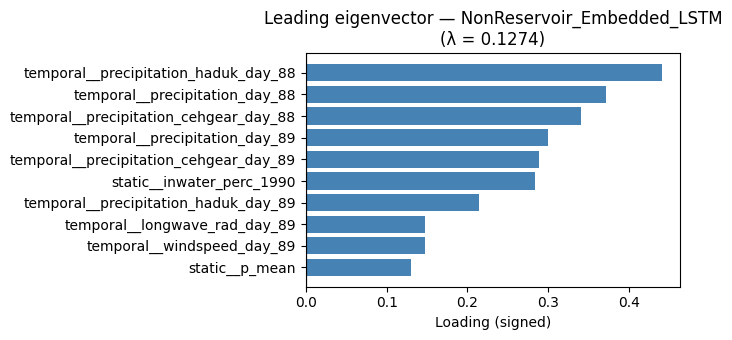


  Full_Embedded_LSTM  |  leading eigenvalue: 0.1012
  Feature                           Loading  |Loading|
  ------------------------------  ---------  ---------
  temporal__precipitation_haduk_day_88    +0.6164     0.6164
  temporal__precipitation_cehgear_day_88    +0.4285     0.4285
  temporal__precipitation_day_88    +0.3796     0.3796
  static__inwater_perc_1990         +0.2246     0.2246
  temporal__precipitation_day_89    +0.1748     0.1748
  temporal__precipitation_cehgear_day_89    +0.1607     0.1607
  temporal__precipitation_haduk_day_89    +0.1520     0.1520
  temporal__precipitation_cehgear_day_87    +0.1199     0.1199
  temporal__longwave_rad_day_89     +0.1148     0.1148
  temporal__windspeed_day_89        +0.1102     0.1102


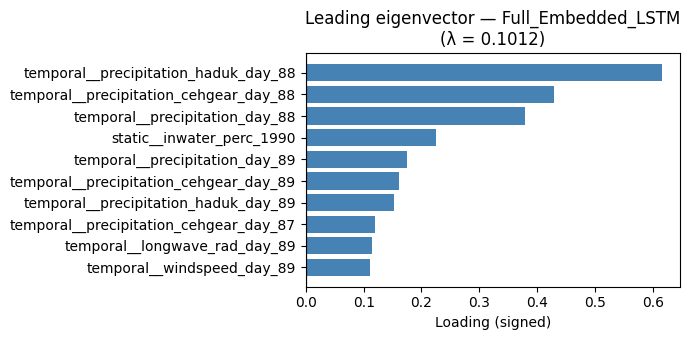


  Hydra_Main  |  leading eigenvalue: 0.0958
  Feature                           Loading  |Loading|
  ------------------------------  ---------  ---------
  temporal__precipitation_haduk_day_88    +0.5911     0.5911
  temporal__precipitation_day_88    +0.3953     0.3953
  temporal__precipitation_cehgear_day_88    +0.3760     0.3760
  static__inwater_perc_1990         +0.1883     0.1883
  temporal__precipitation_day_89    +0.1812     0.1812
  temporal__precipitation_cehgear_day_89    +0.1529     0.1529
  temporal__precipitation_haduk_day_89    +0.1347     0.1347
  temporal__precipitation_haduk_day_87    +0.1174     0.1174
  temporal__precipitation_day_87    +0.1110     0.1110
  temporal__windspeed_day_89        +0.1001     0.1001


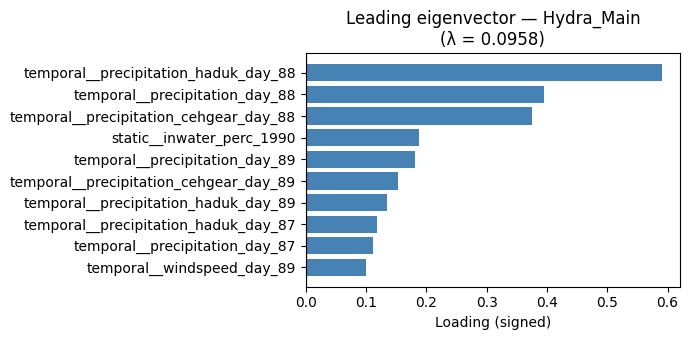


  Hydra_ResHead  |  leading eigenvalue: 0.09649
  Feature                           Loading  |Loading|
  ------------------------------  ---------  ---------
  temporal__precipitation_haduk_day_88    -0.5924     0.5924
  temporal__precipitation_day_88    -0.4077     0.4077
  temporal__precipitation_cehgear_day_88    -0.3865     0.3865
  static__inwater_perc_1990         -0.1811     0.1811
  temporal__precipitation_day_89    -0.1693     0.1693
  temporal__precipitation_cehgear_day_89    -0.1441     0.1441
  temporal__precipitation_haduk_day_87    -0.1303     0.1303
  temporal__precipitation_haduk_day_89    -0.1274     0.1274
  temporal__precipitation_day_87    -0.1138     0.1138
  temporal__windspeed_day_89        -0.0961     0.0961


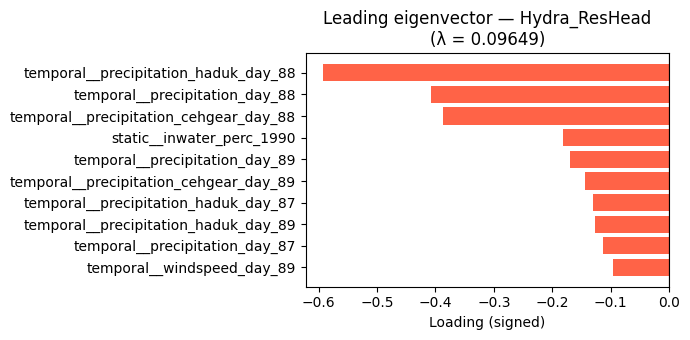


  Hydra_NonResHead  |  leading eigenvalue: 0.1037
  Feature                           Loading  |Loading|
  ------------------------------  ---------  ---------
  temporal__precipitation_haduk_day_88    +0.6074     0.6074
  temporal__precipitation_day_88    +0.4113     0.4113
  temporal__precipitation_cehgear_day_88    +0.3923     0.3923
  static__inwater_perc_1990         +0.1812     0.1812
  temporal__precipitation_day_89    +0.1676     0.1676
  temporal__precipitation_cehgear_day_89    +0.1414     0.1414
  temporal__precipitation_haduk_day_89    +0.1256     0.1256
  temporal__precipitation_haduk_day_87    +0.1214     0.1214
  temporal__precipitation_day_87    +0.1090     0.1090
  temporal__windspeed_day_89        +0.0953     0.0953


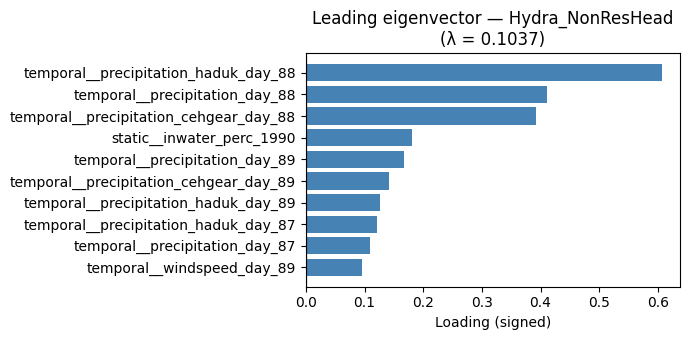

[('Reservoir_Embedded_LSTM',
  ['temporal__precipitation_haduk_day_88',
   'temporal__precipitation_cehgear_day_88',
   'temporal__precipitation_day_88',
   'temporal__precipitation_haduk_day_89',
   'temporal__precipitation_day_89',
   'temporal__precipitation_cehgear_day_89',
   'temporal__precipitation_haduk_day_87',
   'temporal__longwave_rad_day_89',
   'temporal__windspeed_day_89',
   'temporal__precipitation_day_87'],
  array([0.63473207, 0.51174096, 0.35828101, 0.17277834, 0.1723759 ,
         0.11782119, 0.10880603, 0.10752931, 0.09750802, 0.09333499]),
  array([0.63473207, 0.51174096, 0.35828101, 0.17277834, 0.1723759 ,
         0.11782119, 0.10880603, 0.10752931, 0.09750802, 0.09333499]),
  np.float64(0.08344170040639388)),
 ('NonReservoir_Embedded_LSTM',
  ['temporal__precipitation_haduk_day_88',
   'temporal__precipitation_day_88',
   'temporal__precipitation_cehgear_day_88',
   'temporal__precipitation_day_89',
   'temporal__precipitation_cehgear_day_89',
   'static__inwa

In [48]:
models, df_list, cov_list = prepare_analysis(res_df)

feature_names = res_df.iloc[:, 2:].columns   # not model name

show_leading_eigenvectors(cov_list, models, feature_names, top_n=10)


  Reservoir_Embedded_LSTM  |  leading eigenvalue: 0.1106
  Feature                           Loading  |Loading|
  ------------------------------  ---------  ---------
  temporal__precipitation_haduk_day_86    +0.5053     0.5053
  temporal__precipitation_cehgear_day_86    +0.4286     0.4286
  temporal__precipitation_day_87    +0.3729     0.3729
  temporal__precipitation_haduk_day_87    +0.3452     0.3452
  temporal__precipitation_cehgear_day_87    +0.2649     0.2649
  temporal__precipitation_day_86    +0.2351     0.2351
  temporal__longwave_rad_day_87     +0.1427     0.1427
  temporal__windspeed_day_87        +0.1266     0.1266
  static__bankfull_flow             +0.1095     0.1095
  temporal__precipitation_day_85    +0.0967     0.0967


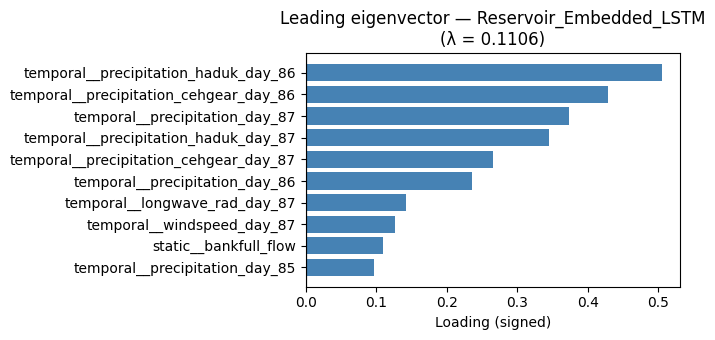


  NonReservoir_Embedded_LSTM  |  leading eigenvalue: 0.1663
  Feature                           Loading  |Loading|
  ------------------------------  ---------  ---------
  temporal__precipitation_day_87    -0.4931     0.4931
  temporal__precipitation_cehgear_day_87    -0.4841     0.4841
  temporal__precipitation_haduk_day_87    -0.3566     0.3566
  temporal__precipitation_haduk_day_86    -0.2567     0.2567
  static__bankfull_flow             -0.2136     0.2136
  temporal__precipitation_day_86    -0.2036     0.2036
  temporal__windspeed_day_87        -0.1899     0.1899
  temporal__precipitation_cehgear_day_86    -0.1765     0.1765
  temporal__longwave_rad_day_87     -0.1436     0.1436
  temporal__humidity_day_87         -0.1061     0.1061


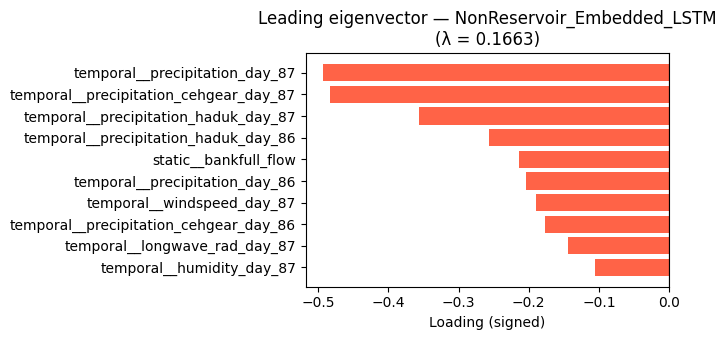


  Full_Embedded_LSTM  |  leading eigenvalue: 0.1744
  Feature                           Loading  |Loading|
  ------------------------------  ---------  ---------
  temporal__precipitation_day_87    +0.4421     0.4421
  temporal__precipitation_cehgear_day_87    +0.4138     0.4138
  temporal__precipitation_haduk_day_86    +0.3854     0.3854
  temporal__precipitation_haduk_day_87    +0.3398     0.3398
  temporal__precipitation_cehgear_day_86    +0.2807     0.2807
  static__bankfull_flow             +0.2334     0.2334
  temporal__precipitation_day_86    +0.2237     0.2237
  temporal__windspeed_day_87        +0.1847     0.1847
  temporal__longwave_rad_day_87     +0.1395     0.1395
  temporal__humidity_day_87         +0.1002     0.1002


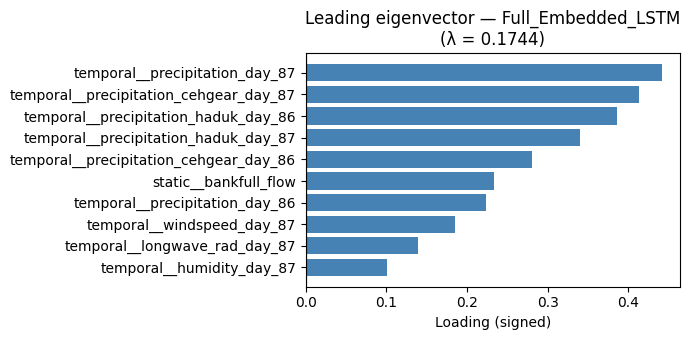


  Hydra_Main  |  leading eigenvalue: 0.2069
  Feature                           Loading  |Loading|
  ------------------------------  ---------  ---------
  temporal__precipitation_day_87    +0.4235     0.4235
  temporal__precipitation_cehgear_day_87    +0.3520     0.3520
  temporal__precipitation_haduk_day_87    +0.3264     0.3264
  temporal__precipitation_haduk_day_86    +0.3108     0.3108
  static__bankfull_flow             +0.2512     0.2512
  temporal__precipitation_day_86    +0.2253     0.2253
  temporal__precipitation_cehgear_day_86    +0.2031     0.2031
  temporal__windspeed_day_87        +0.1928     0.1928
  static__gauge_elev                +0.1293     0.1293
  temporal__longwave_rad_day_87     +0.1248     0.1248


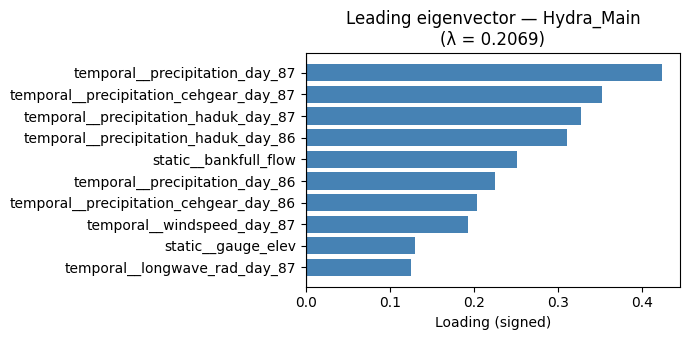


  Hydra_ResHead  |  leading eigenvalue: 0.172
  Feature                           Loading  |Loading|
  ------------------------------  ---------  ---------
  temporal__precipitation_day_87    +0.4004     0.4004
  temporal__precipitation_haduk_day_86    +0.3653     0.3653
  temporal__precipitation_cehgear_day_87    +0.3395     0.3395
  temporal__precipitation_haduk_day_87    +0.3098     0.3098
  temporal__precipitation_day_86    +0.2660     0.2660
  temporal__precipitation_cehgear_day_86    +0.2440     0.2440
  static__bankfull_flow             +0.2217     0.2217
  temporal__windspeed_day_87        +0.1798     0.1798
  temporal__longwave_rad_day_87     +0.1196     0.1196
  temporal__humidity_day_87         +0.1067     0.1067


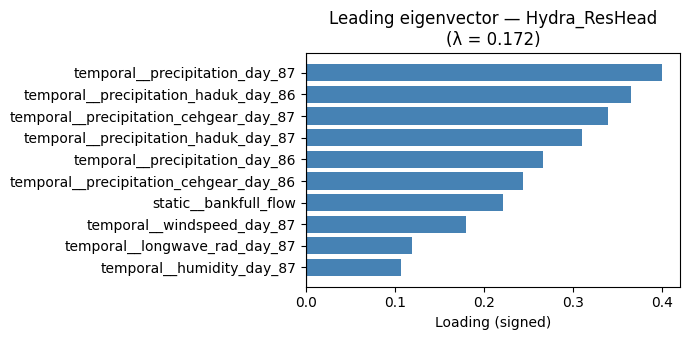


  Hydra_NonResHead  |  leading eigenvalue: 0.2125
  Feature                           Loading  |Loading|
  ------------------------------  ---------  ---------
  temporal__precipitation_day_87    +0.4172     0.4172
  temporal__precipitation_cehgear_day_87    +0.3495     0.3495
  temporal__precipitation_haduk_day_87    +0.3293     0.3293
  temporal__precipitation_haduk_day_86    +0.3210     0.3210
  static__bankfull_flow             +0.2615     0.2615
  temporal__precipitation_day_86    +0.2288     0.2288
  temporal__precipitation_cehgear_day_86    +0.2061     0.2061
  temporal__windspeed_day_87        +0.1882     0.1882
  static__gauge_elev                +0.1307     0.1307
  temporal__longwave_rad_day_87     +0.1201     0.1201


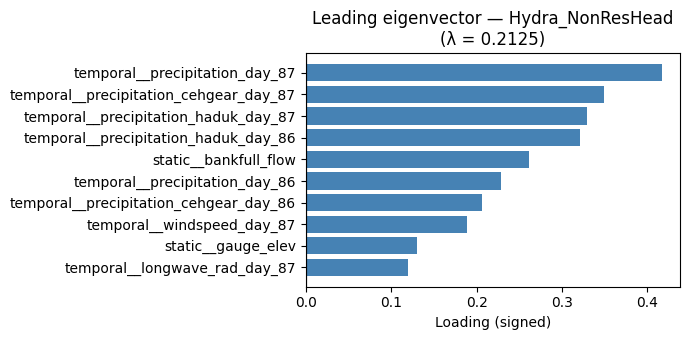

[('Reservoir_Embedded_LSTM',
  ['temporal__precipitation_haduk_day_86',
   'temporal__precipitation_cehgear_day_86',
   'temporal__precipitation_day_87',
   'temporal__precipitation_haduk_day_87',
   'temporal__precipitation_cehgear_day_87',
   'temporal__precipitation_day_86',
   'temporal__longwave_rad_day_87',
   'temporal__windspeed_day_87',
   'static__bankfull_flow',
   'temporal__precipitation_day_85'],
  array([0.50529807, 0.4285745 , 0.37291915, 0.34522586, 0.26493104,
         0.23512236, 0.14266742, 0.12655017, 0.10948351, 0.0966639 ]),
  array([0.50529807, 0.4285745 , 0.37291915, 0.34522586, 0.26493104,
         0.23512236, 0.14266742, 0.12655017, 0.10948351, 0.0966639 ]),
  np.float64(0.11061561867142426)),
 ('NonReservoir_Embedded_LSTM',
  ['temporal__precipitation_day_87',
   'temporal__precipitation_cehgear_day_87',
   'temporal__precipitation_haduk_day_87',
   'temporal__precipitation_haduk_day_86',
   'static__bankfull_flow',
   'temporal__precipitation_day_86',
   't

In [49]:
models_nr, df_list_nr, cov_list_nr = prepare_analysis(nonres_df)
feature_names_nr = nonres_df.iloc[:, :].columns

show_leading_eigenvectors(cov_list_nr, models_nr, feature_names_nr, top_n=10, plot=True)

In [50]:
def plot_leading_eigenvectors(cov_list, models, feature_names,
                              n_vecs=5, top_n=10, anchor_name = "temporal__precipitation_haduk__day_83_89_abs"):
    
    feature_names = list(feature_names)
    n_models = len(models)
    anchor_idx = feature_names.index(f"{anchor_name}")

    """
    Grid of bar charts: rows = top eigenvectors (by eigenvalue),
    columns = models.

    Parameters
    ----------
    cov_list      : list[np.ndarray]
    models        : list[str]
    feature_names : list[str]
    n_vecs        : int  – how many leading eigenvectors to show (rows)
    top_n         : int  – how many top loadings to show per vector (bars)
    """
    feature_names = list(feature_names)
    n_models = len(models)

    fig, axes = plt.subplots(
        n_vecs, n_models,
        figsize=(3.5 * n_models, 2.5 * n_vecs),
        sharey=False
    )
    # ensure axes is always 2-D
    if n_vecs == 1:
        axes = axes[np.newaxis, :]
    if n_models == 1:
        axes = axes[:, np.newaxis]

    for col, (model, cov) in enumerate(zip(models, cov_list)):
        vals, vecs = np.linalg.eigh(cov)
        # sort descending
        order = np.argsort(vals)[::-1]
        vals = vals[order]
        vecs = vecs[:, order]

        for row in range(n_vecs):
            ax = axes[row, col]
            v = vecs[:, row]
            v = v / np.linalg.norm(v)
            
            if v[anchor_idx] < 0:    # ← add this
                v = -v               # ← add this
            
            top_idx = np.argsort(np.abs(v))[::-1][:top_n]
            top_feats   = [feature_names[i] for i in top_idx]
            top_loadings = v[top_idx]

            alpha_order = np.argsort(top_feats)[::-1]  # reversed so A is at top of barh
            top_feats    = [top_feats[i] for i in alpha_order]
            top_loadings = top_loadings[alpha_order]

            colors = ["steelblue" if l >= 0 else "tomato" for l in top_loadings]
            ax.barh(top_feats[::-1], top_loadings[::-1], color=colors[::-1])
            ax.axvline(0, color="black", linewidth=0.7)
            ax.tick_params(axis="y", labelsize=7)
            ax.tick_params(axis="x", labelsize=7)

            if row == 0:
                ax.set_title(model, fontsize=9, fontweight="bold")
            ax.set_ylabel(f"Eigenvec {row + 1}\n(λ={vals[row]:.3g})",
                          fontsize=7, labelpad=4)

    plt.suptitle(
        f"Top {n_vecs} leading eigenvectors — top {top_n} loadings per vector",
        fontsize=11, y=1.01
    )
    plt.tight_layout()
    plt.show()

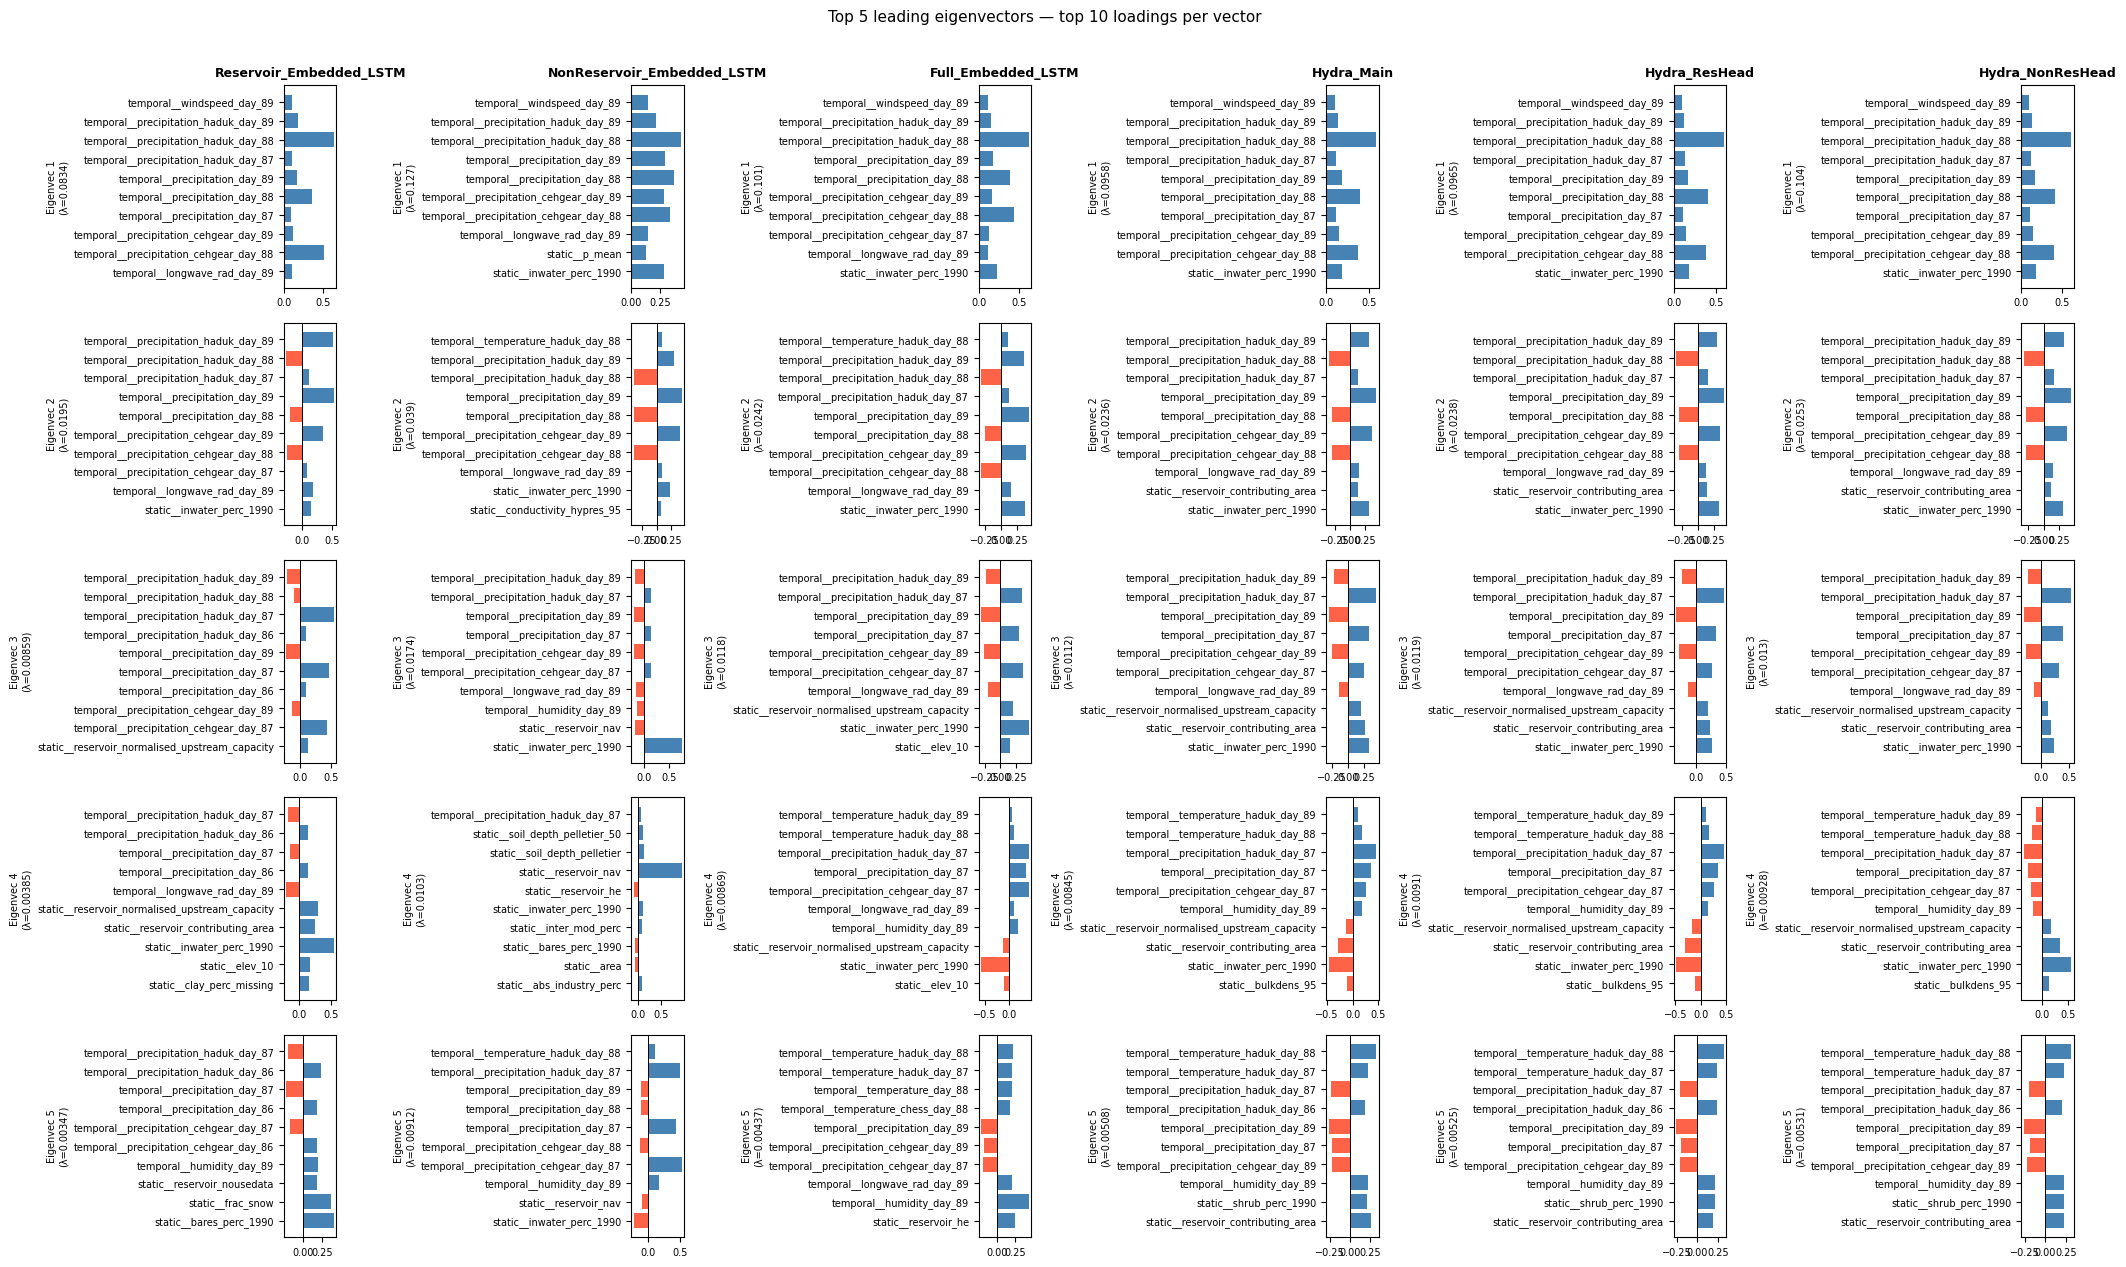

In [51]:
plot_leading_eigenvectors(cov_list, models, feature_names, n_vecs=5, top_n=10, anchor_name = "temporal__precipitation_haduk_day_86")



In [52]:
models, df_list, cov_list_agg = prepare_analysis(res_df_agg)
feature_names = res_df_agg.iloc[:, 2:].columns   # not model name and sample

models_nr, df_list_nr, cov_list_nr_agg = prepare_analysis(nonres_df_agg)
feature_names_nr = nonres_df.iloc[:, 2:].columns


models, df_list, cov_list_agg = prepare_analysis(res_df_agg)
feature_names = res_df_agg.iloc[:, 2:].columns   # not model name and sample

models_nr, df_list_nr, cov_list_nr_agg = prepare_analysis(nonres_df_agg)
feature_names_nr = nonres_df.iloc[:, 2:].columns


# Static Reservoir
models_static_res, df_list_static_res, cov_list_static_res = prepare_analysis(static_res_df)
feature_names_static_res = static_res_df.iloc[:, 2:].columns


# Temporal Reservoir
models_temporal_res, df_list_temporal_res, cov_list_temporal_res = prepare_analysis(temporal_res_df)
feature_names_temporal_res = temporal_res_df.iloc[:, 2:].columns


# Static Non-Reservoir
models_static_nonres, df_list_static_nonres, cov_list_static_nonres = prepare_analysis(static_nonres_df)
feature_names_static_nonres = static_nonres_df.iloc[:, 2:].columns

# Temporal Non-Reservoir
models_temporal_nonres, df_list_temporal_nonres, cov_list_temporal_nonres = prepare_analysis(temporal_nonres_df)
feature_names_temporal_nonres = temporal_nonres_df.iloc[:, 2:].columns


## Unsplit

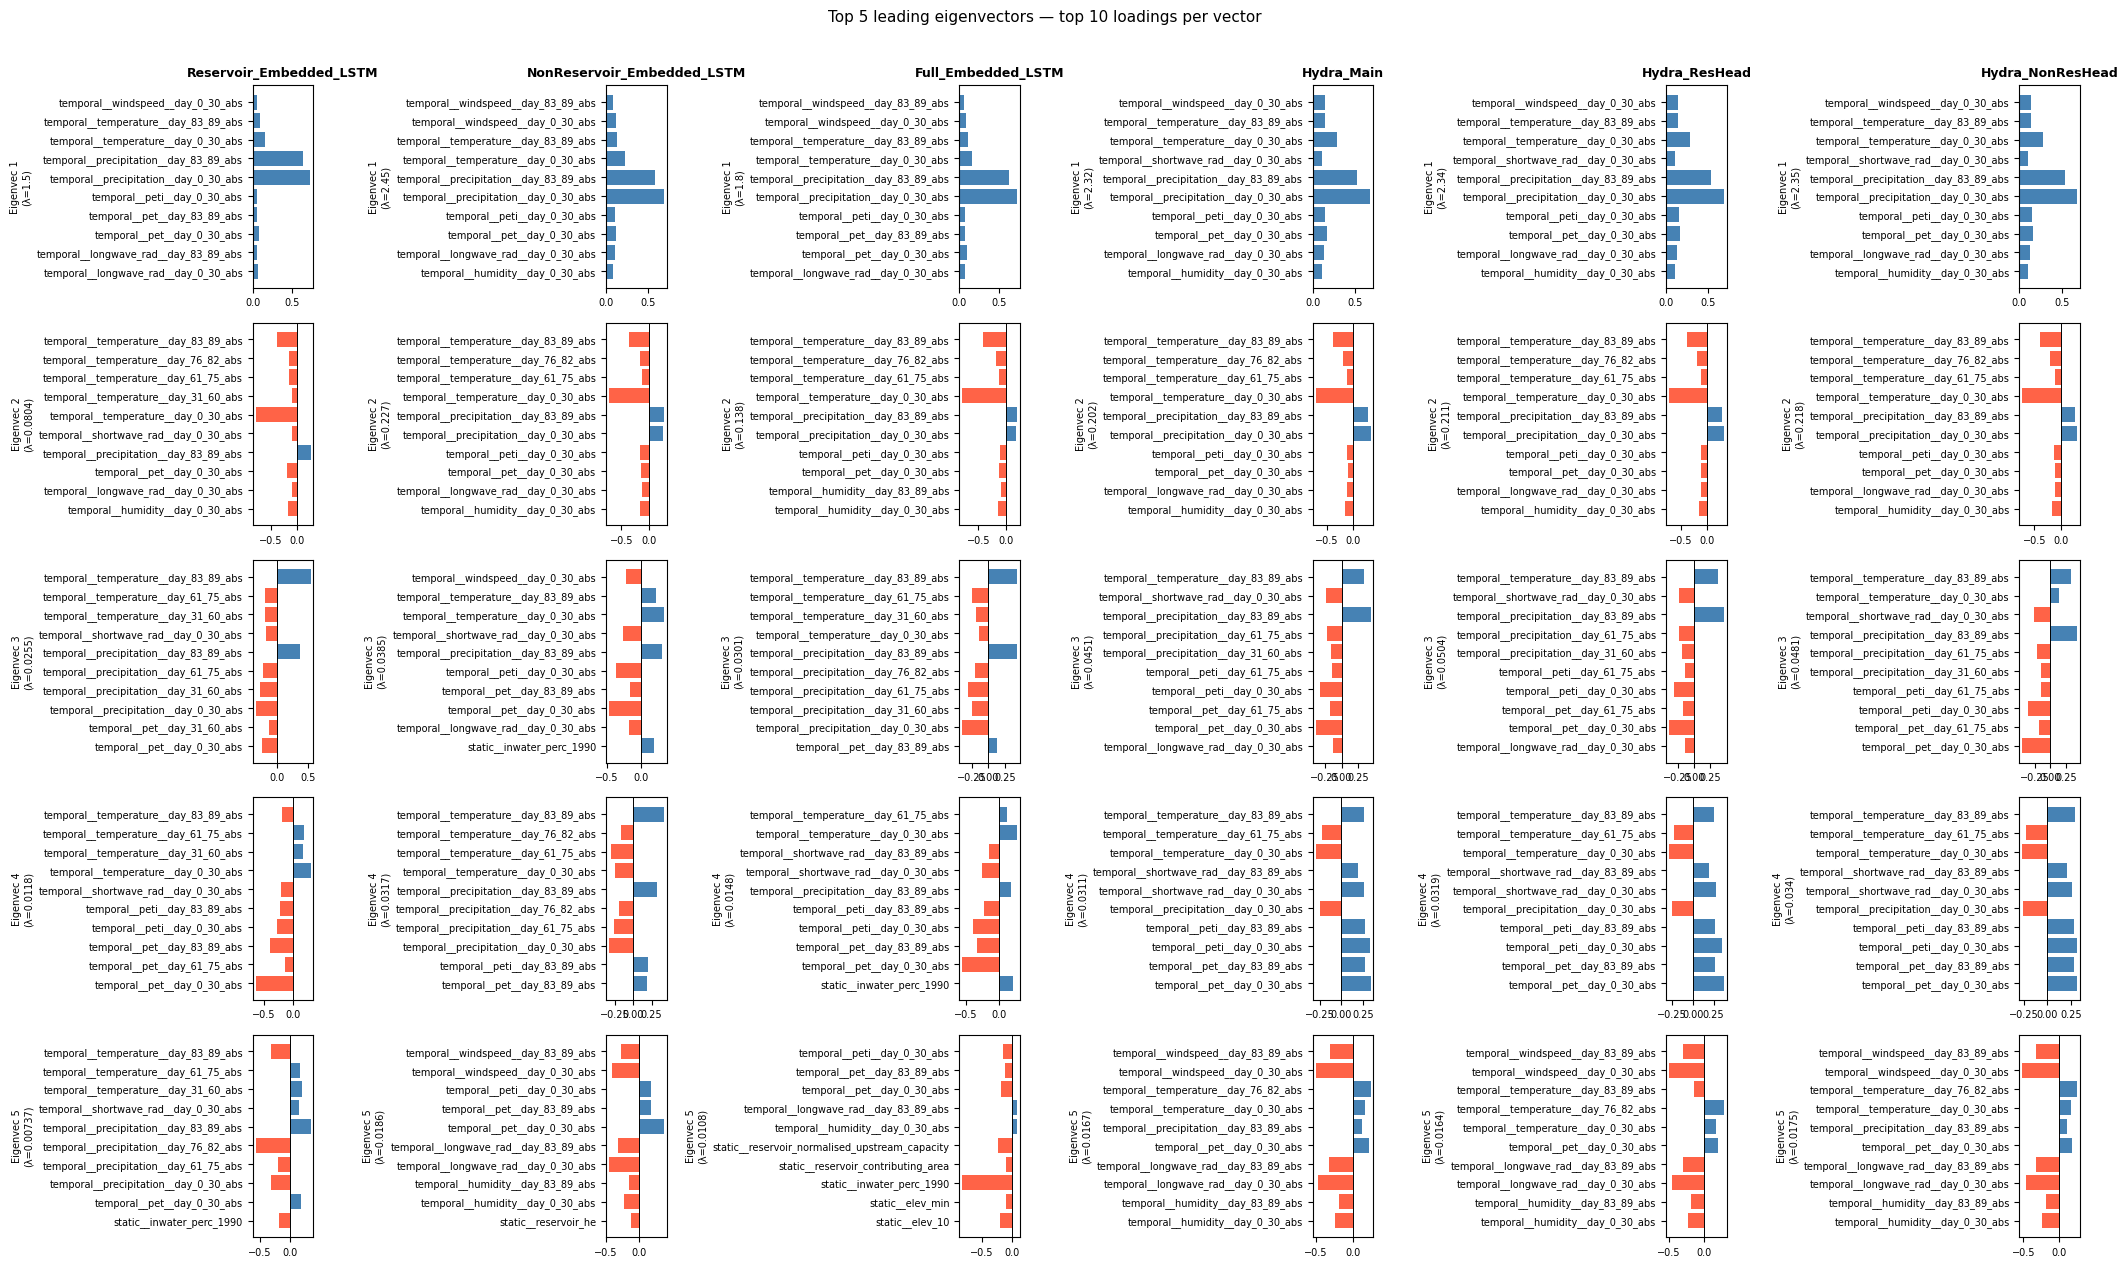

In [53]:
plot_leading_eigenvectors(cov_list_agg, models, feature_names, n_vecs=5, top_n=10, anchor_name = "temporal__precipitation__day_83_89_abs")

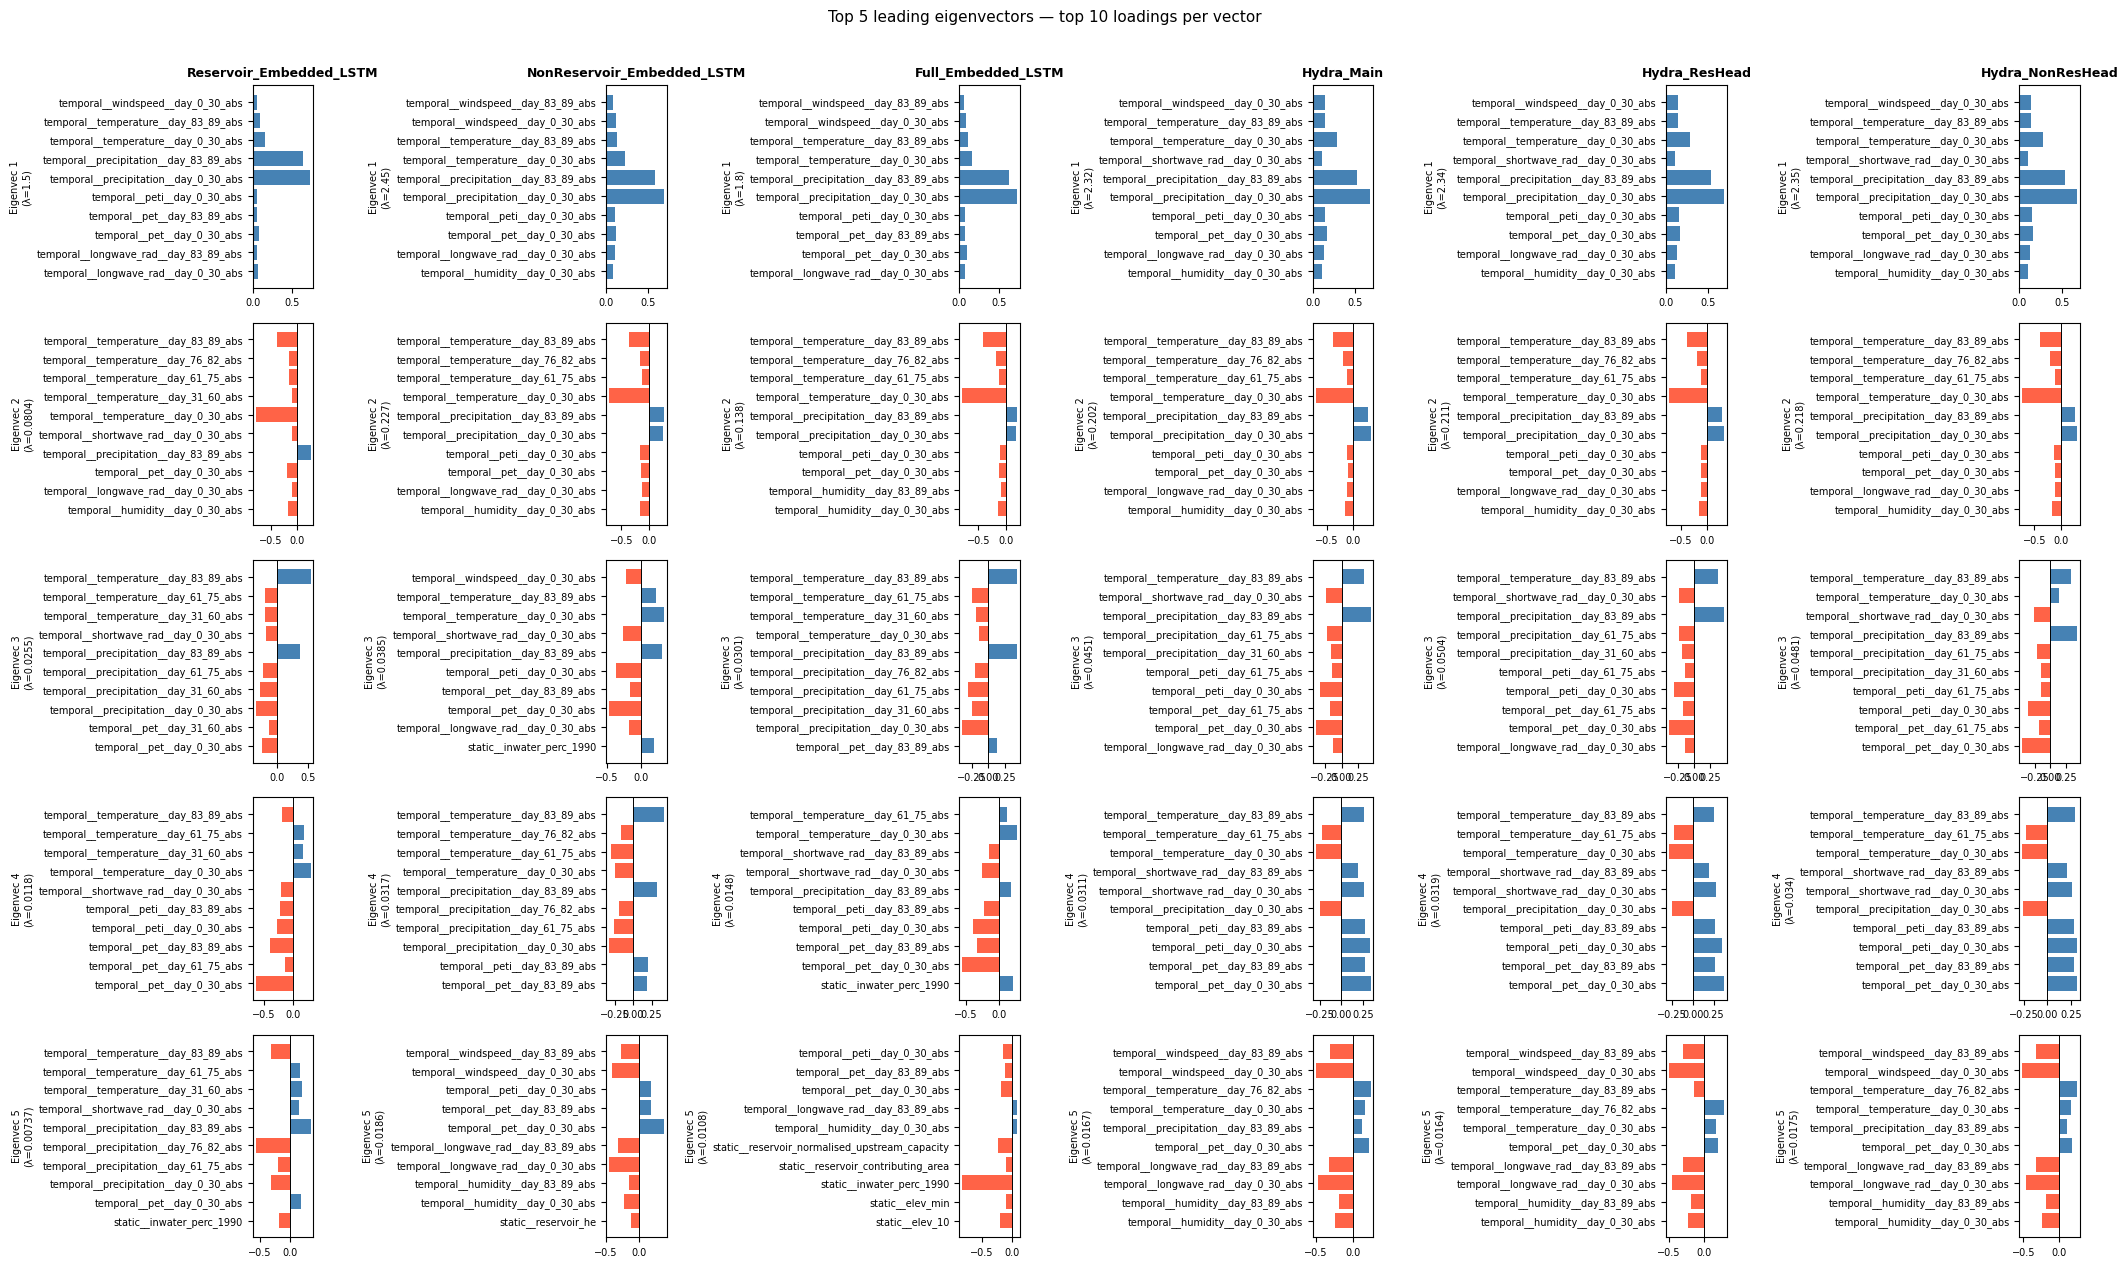

In [54]:
plot_leading_eigenvectors(cov_list_agg, models, feature_names, n_vecs=5, top_n=10, anchor_name = "temporal__precipitation__day_83_89_abs")

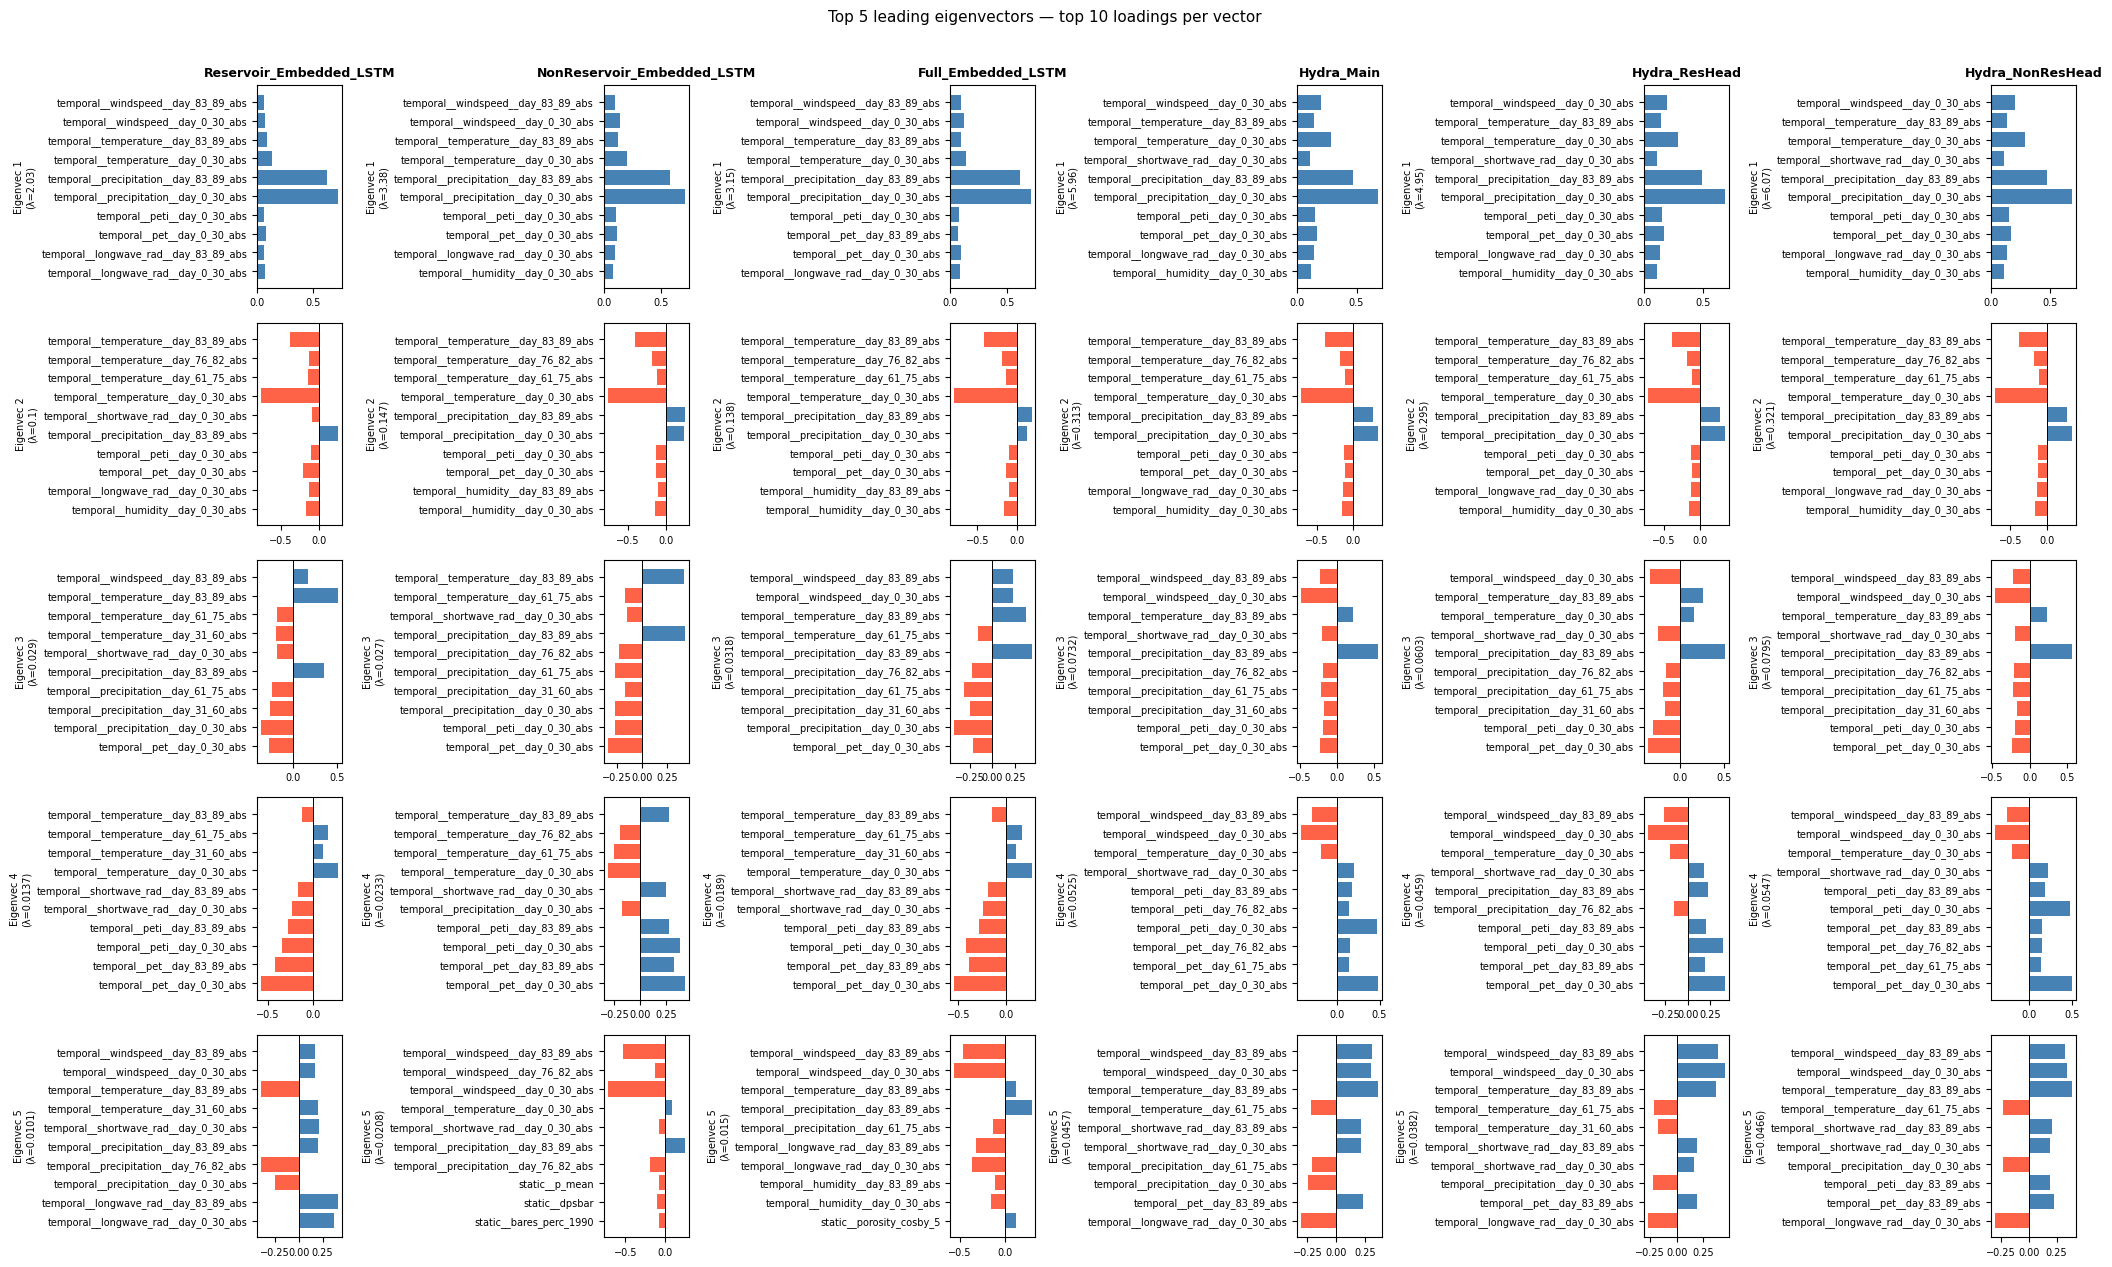

In [55]:
plot_leading_eigenvectors(cov_list_nr_agg, models, feature_names, n_vecs=5, top_n=10, anchor_name = "temporal__precipitation__day_83_89_abs")

## Splitting by static/temporal

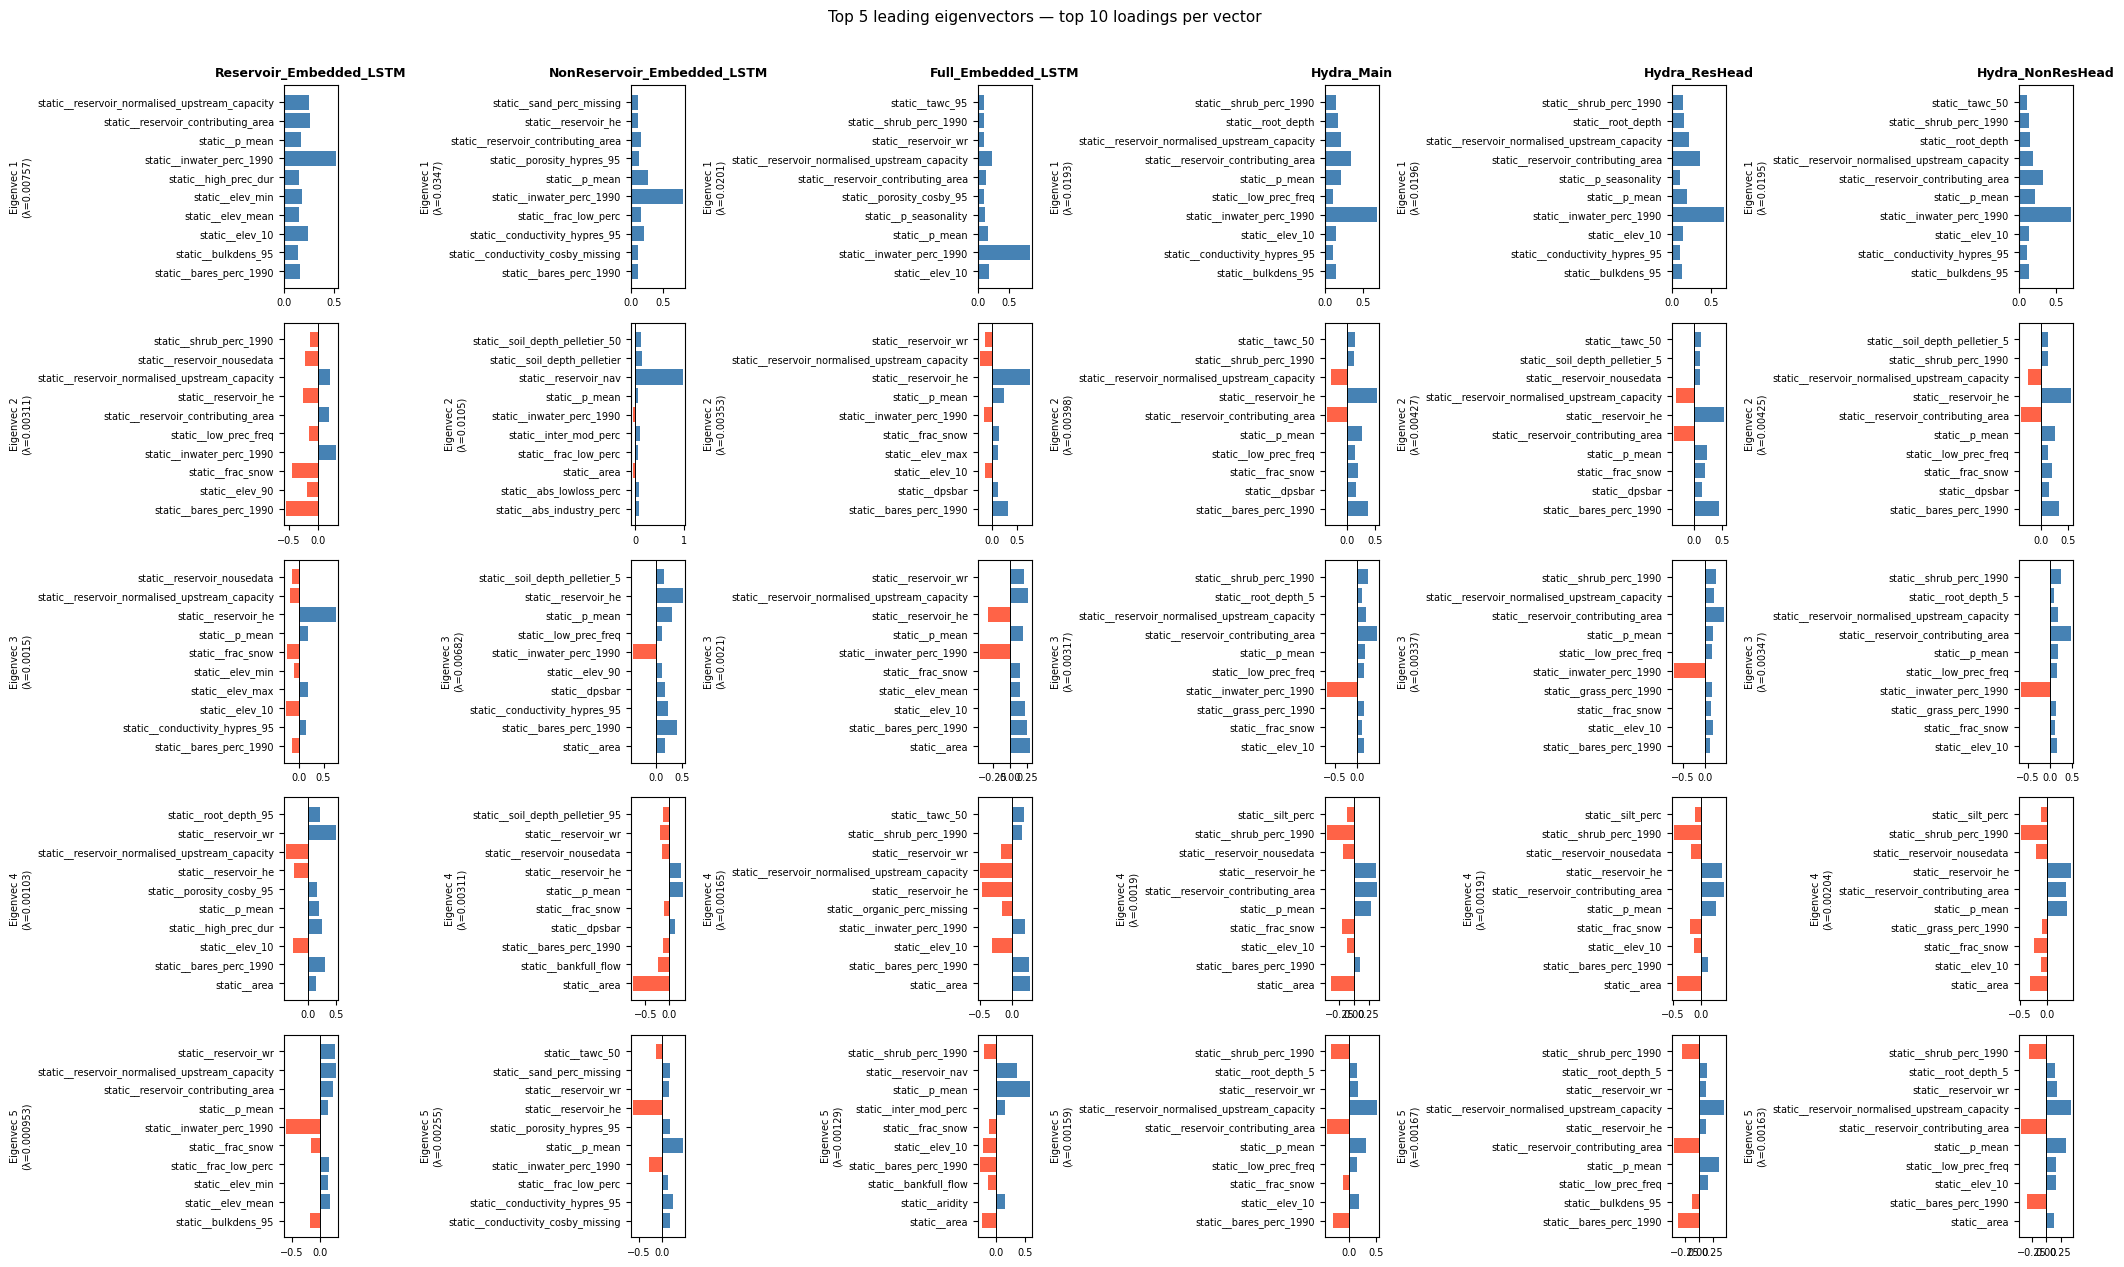

In [56]:
plot_leading_eigenvectors(cov_list_static_res, models_static_res, feature_names_static_res, n_vecs=5, top_n=10, anchor_name="static__p_mean")

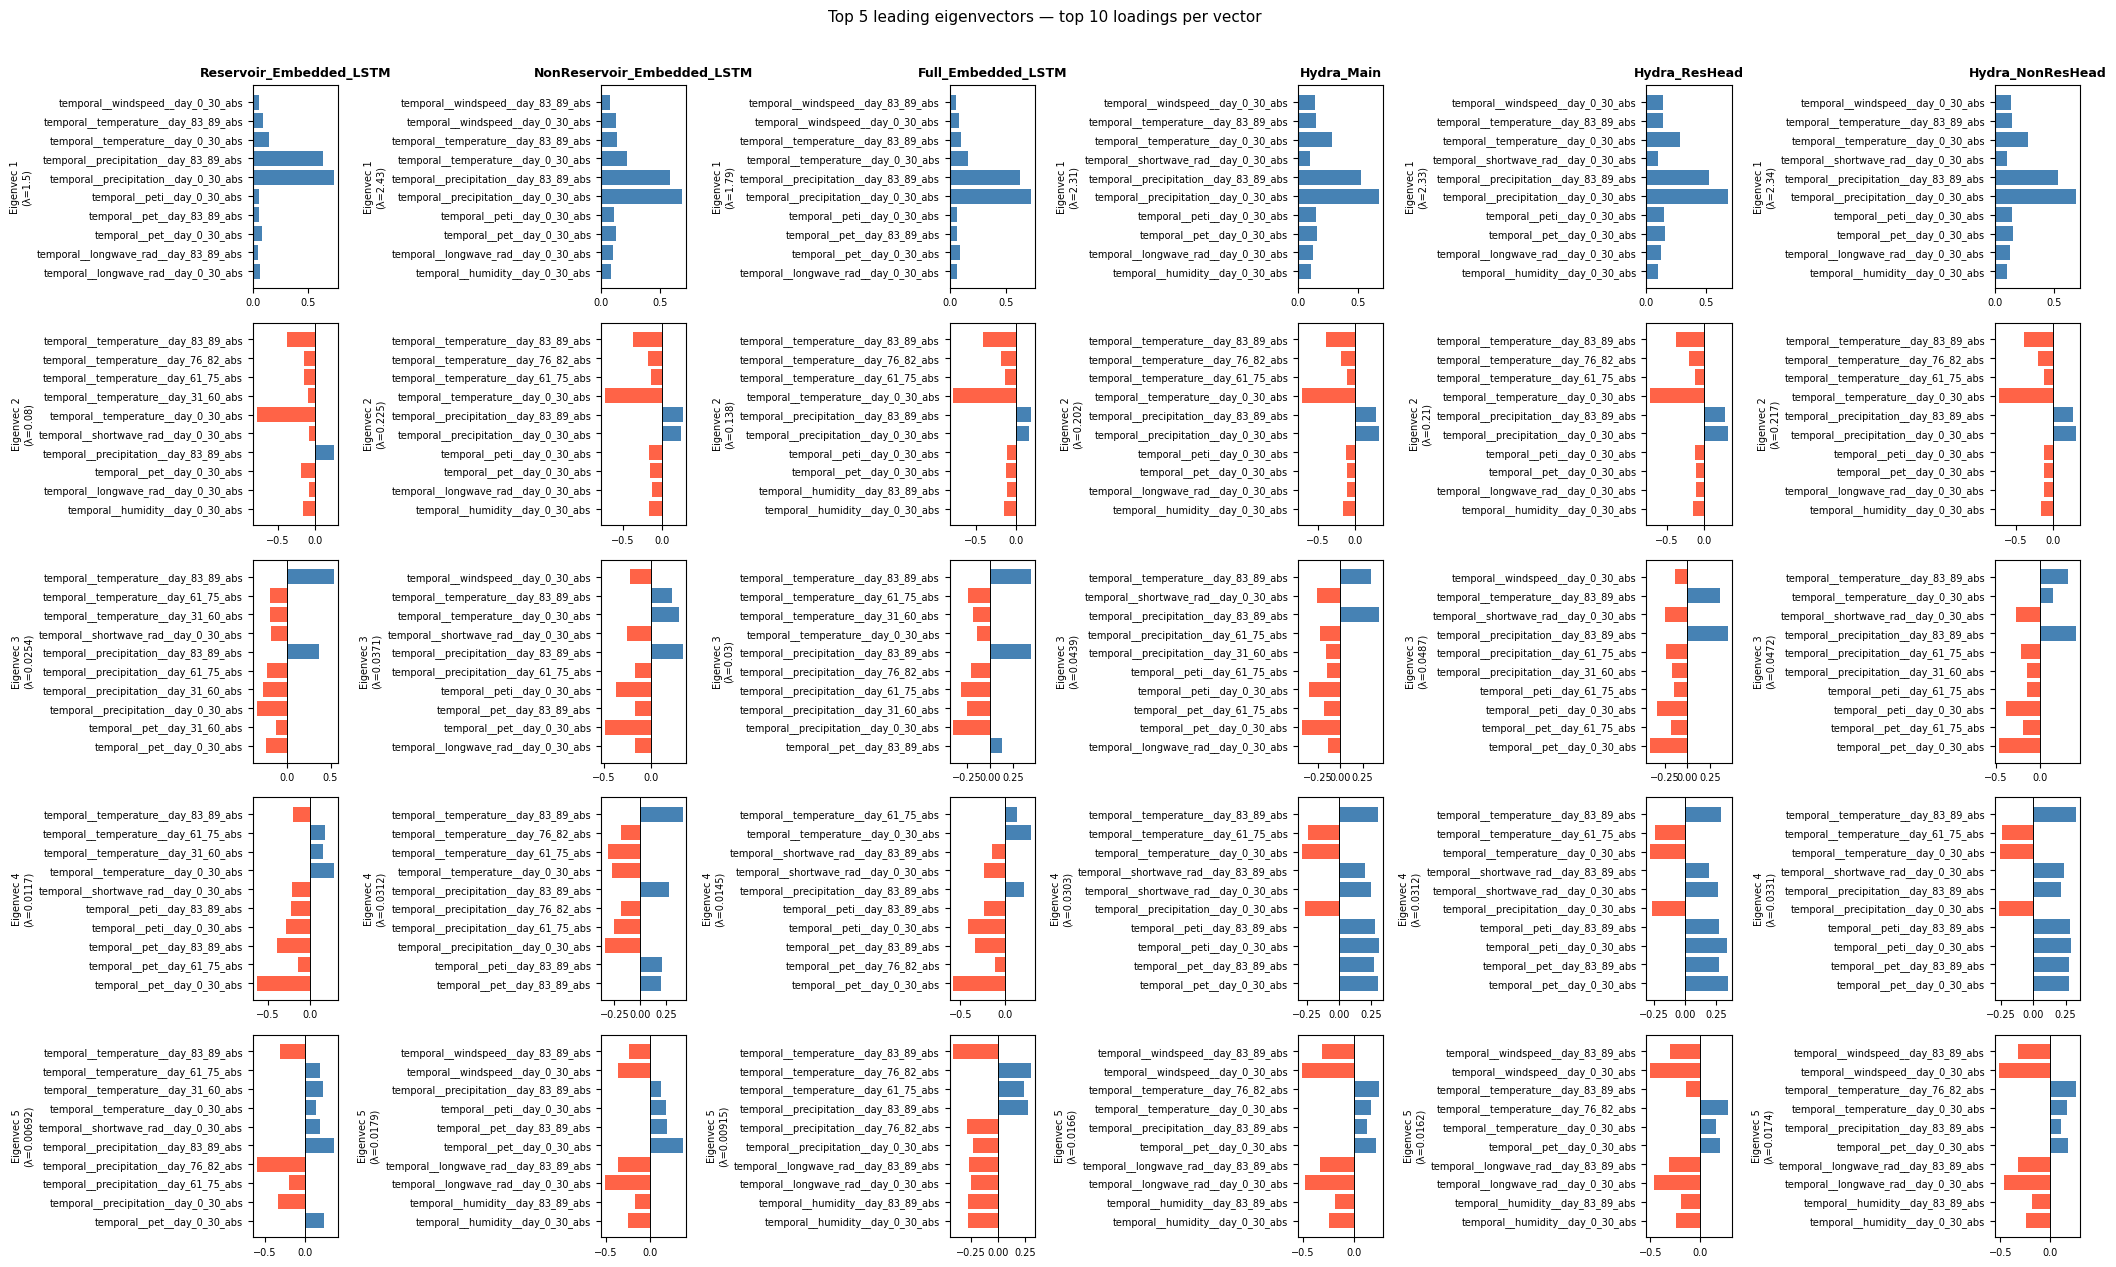

In [57]:
plot_leading_eigenvectors(cov_list_temporal_res, models_temporal_res, feature_names_temporal_res, n_vecs=5, top_n=10, anchor_name="temporal__precipitation__day_83_89_abs")

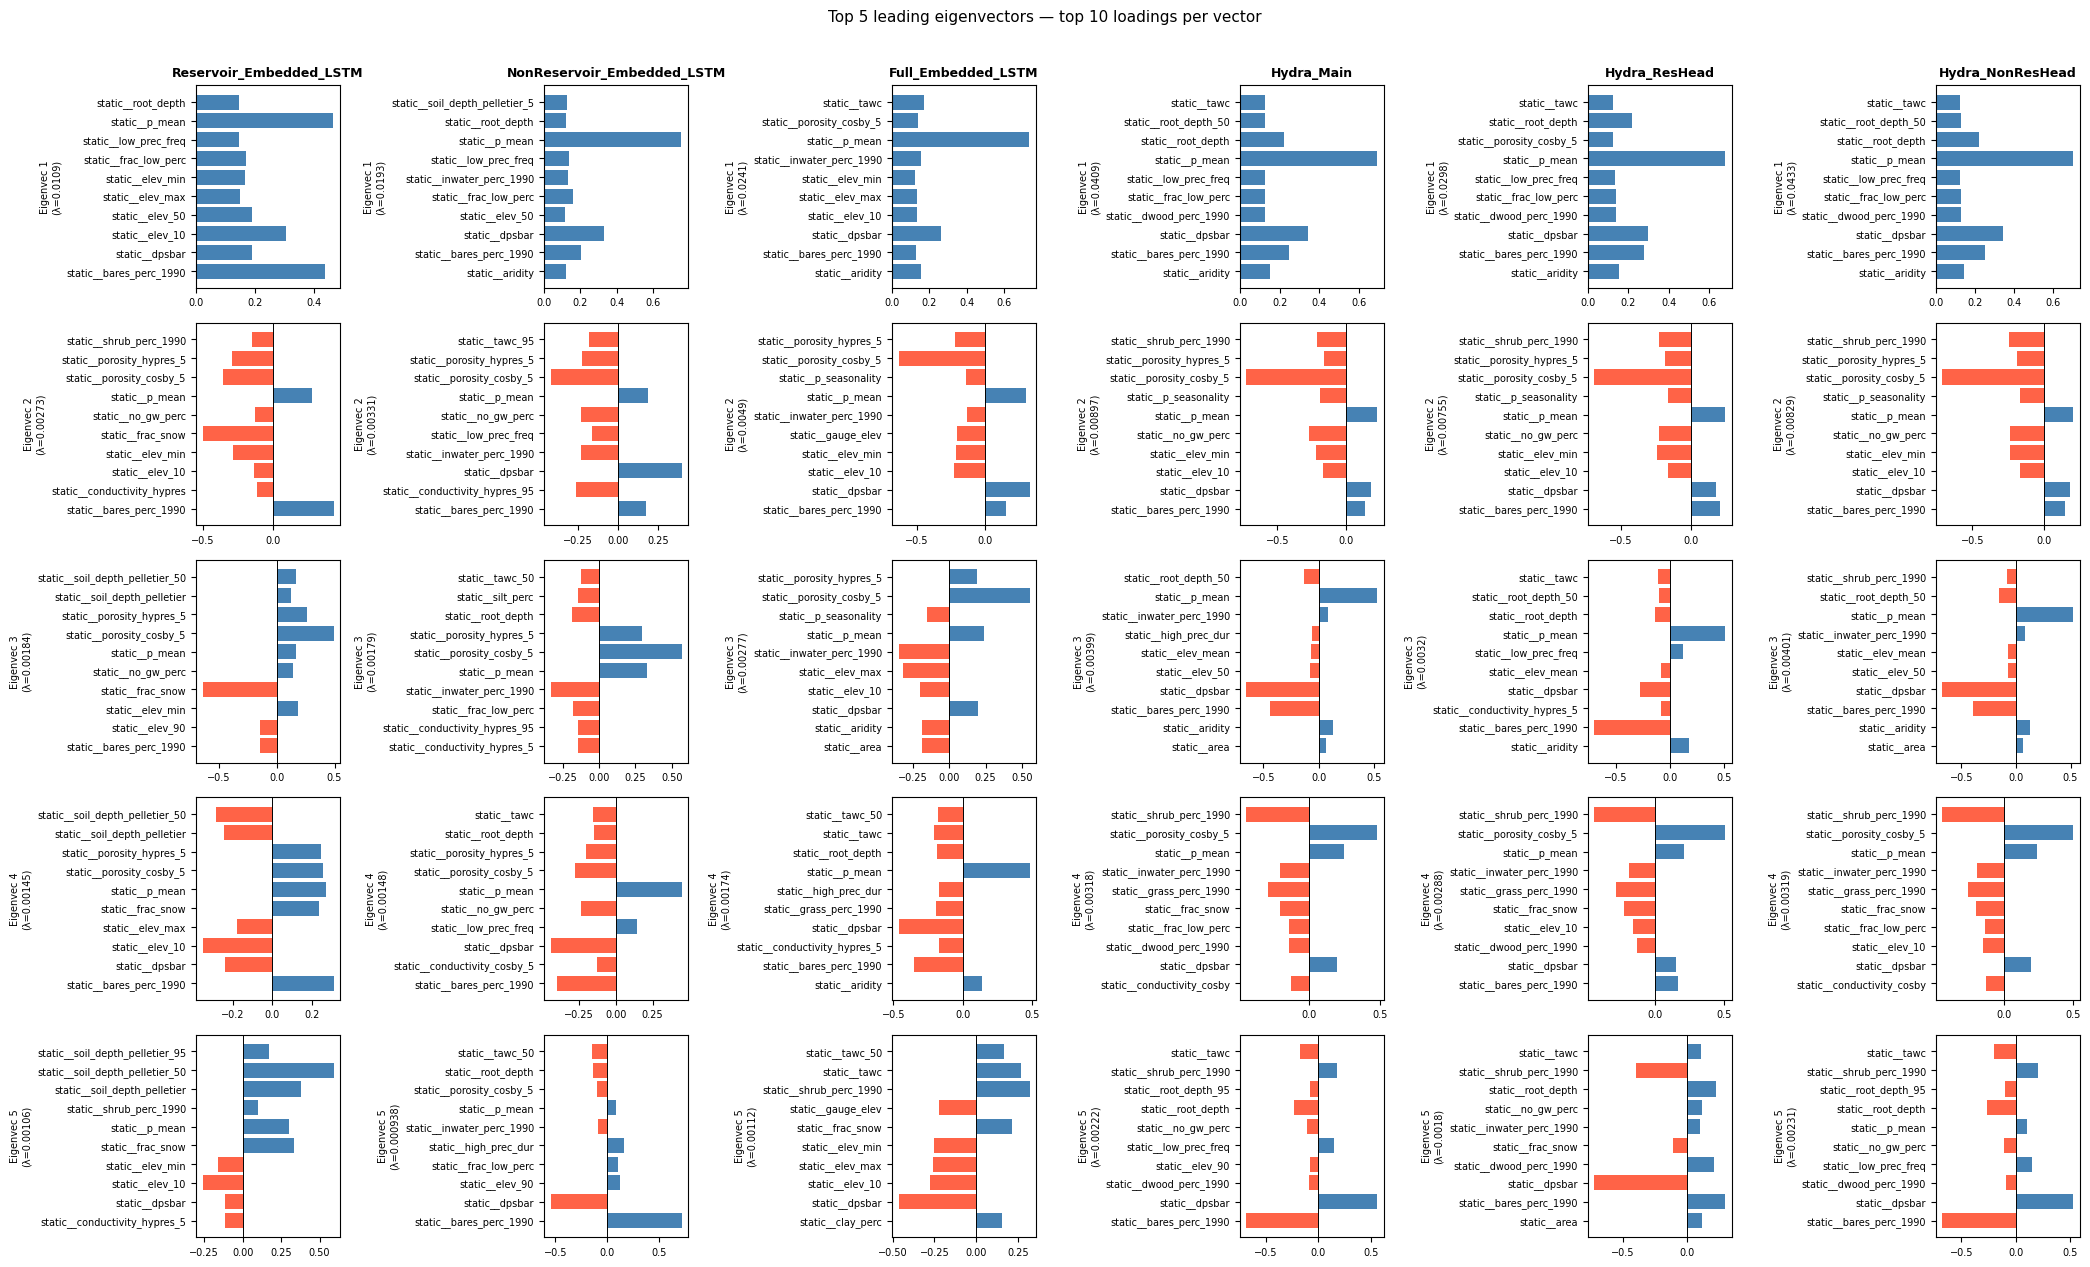

In [58]:
plot_leading_eigenvectors(cov_list_static_nonres, models_static_nonres, feature_names_static_nonres, n_vecs=5, top_n=10, anchor_name="static__p_mean")

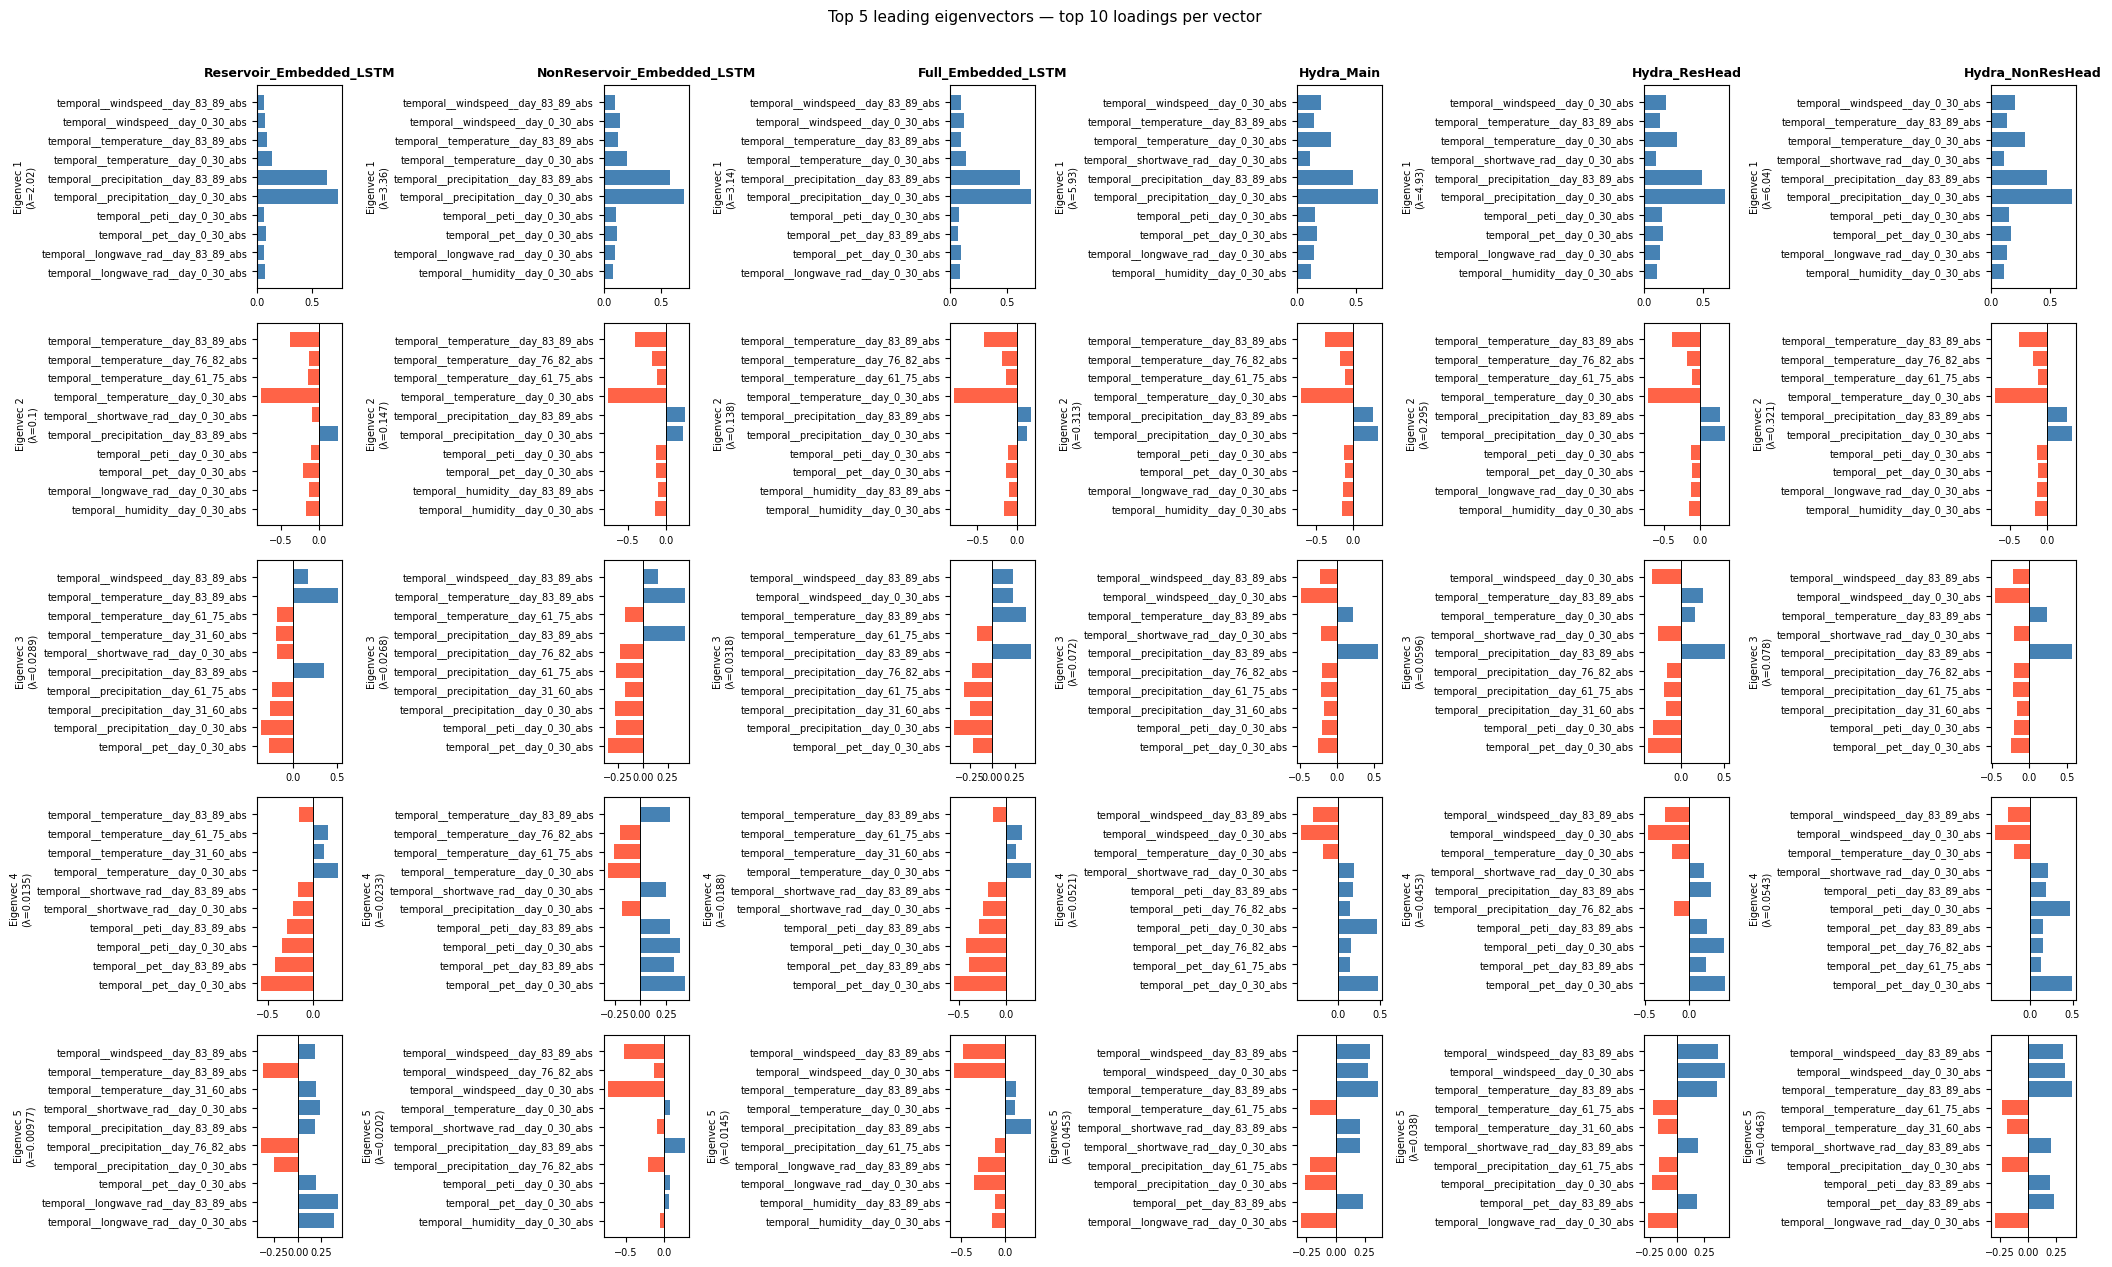

In [59]:
plot_leading_eigenvectors(cov_list_temporal_nonres, models_temporal_nonres, feature_names_temporal_nonres, n_vecs=5, top_n=10, anchor_name="temporal__precipitation__day_83_89_abs")

# Adding random noise

In [60]:
import sys
import pickle
# import warnings
from pathlib import Path

from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd
import joblib
from tqdm import tqdm

import torch
from torch.utils.data import DataLoader
import warnings

warnings.filterwarnings("ignore", category=DeprecationWarning)

import gc

# --- Local Module Configuration ---
FUNCTIONS_PATH = Path("/home/mokr/Reservoir_Modelling/ML_Functions/")
if str(FUNCTIONS_PATH) not in sys.path:
    sys.path.append(str(FUNCTIONS_PATH))

# Importing from your custom files
import ML_functions
# from ML_Metrics import compute_integrated_gradients

from ML_functions import TensorCatchmentDataset, NSELoss
from ML_Models import LSTM_With_Embedding, LSTMModel, HydraModel
from ML_Training import (
    run_model_pipeline,
    process_validation_batches,
)


In [61]:
## Load models
## Not using river flow
No_Flow_Reservoir_Embedded_LSTM = torch.load("/home/mokr/Reservoir_Modelling/CamelsGB_Models/Reservoir/2003_No_Lat_Reservoir_LSTM_Numlayers1_LSTMhs256_Embhs64_Embos16_Epochs0_Gamma0.8_0.001_0.4.pt",
    weights_only=False,
    map_location=torch.device("cpu"),
)

No_Flow_NonReservoir_Embedded_LSTM = torch.load(    "/home/mokr/Reservoir_Modelling/CamelsGB_Models/Natural/2003_No_Lat_Natural_LSTM_FlowFalse_Numlayers2_LSTMhs256_Embhs64_Embos16_Epochs2_Gamma0.95_0.001_0.4.pt",
    weights_only=False,
    map_location=torch.device("cpu"),
)

No_Flow_Full_Embedded_LSTM = torch.load(    "/home/mokr/Reservoir_Modelling/CamelsGB_Models/Full/2003_No_Lat__Full_LSTM_Numlayers2_LSTMhs128_Embhs128_Embos32_Epochs0_Gamma0.95.pt_0.001_0.1",
    weights_only=False,
    map_location=torch.device("cpu"),
)

No_Flow_Full_Embedded_LSTM = torch.load("/home/mokr/Reservoir_Modelling/CamelsGB_Models/Full/89Warmup_No_Lat__Full_LSTM_Numlayers1_LSTMhs128_Embhs128_Embos16_Epochs2_Gamma0.95.pt_0.001_0",
    weights_only=False,
    map_location=torch.device("cpu"),
)



full_base_path = "/home/mokr/Reservoir_Modelling/CamelsGB_Models/Hydra/2003_No_Lat_Full_Hydra_LSTM_Numlayers1_LSTMhs256_Embhs128_Embos16_BodyOut128_MainEp3_ResEp3_ResLR0.001_Gamma0.95_0.001_0.001"


No_Flow_Full_Hydra_Body = torch.load(
    f"{full_base_path}_Body.pt", weights_only=False, map_location=torch.device("cpu")
)
No_Flow_Full_Hydra_Head = torch.load(
    f"{full_base_path}_Main_Head.pt", weights_only=False, map_location=torch.device("cpu")
)
No_Flow_Full_Hydra_ResHead = torch.load(
    f"{full_base_path}_Res_Embedding_Head.pt",
    weights_only=False,
    map_location=torch.device("cpu"),
)

No_Flow_Full_Hydra_Main = HydraModel(No_Flow_Full_Hydra_Body, No_Flow_Full_Hydra_Head)

full_base_path = "/home/mokr/Reservoir_Modelling/CamelsGB_Models/Hydra/2003_No_Lat_Full_Hydra_LSTM_Numlayers1_LSTMhs256_Embhs128_Embos16_BodyOut128_MainEp3_ResEp1_ResLR0.001_Gamma0.95_0.001_0.001"
No_Flow_Full_Hydra_NonResHead = torch.load(
    f"{full_base_path}_NonRes_Embedding_Head.pt",
    weights_only=False,
    map_location=torch.device("cpu"),
)


## Set up Model Lists
MODEL_NAME_MAP = {
    "Reservoir Embedded LSTM": "Reservoir",
    "NonReservoir Embedded LSTM": "Non-Reservoir",
    "Full Embedded LSTM": "Full LSTM",
    "Hydra-LSTM: Main": "Hydra: Main",
    "Hydra-LSTM: Reservoir Head": "Hydra: Res Head",
    "Hydra-LSTM: Non-Reservoir Head": "Hydra: Non-Res Head",

    
}

model_names = [
    "Reservoir_Embedded_LSTM",
    "NonReservoir_Embedded_LSTM",
    "Full_Embedded_LSTM",
    "Hydra_Main",
    "Hydra_ResHead",
    "Hydra_NonResHead",
    
]

no_flow_models = [
    No_Flow_Reservoir_Embedded_LSTM,
    No_Flow_NonReservoir_Embedded_LSTM,
    No_Flow_Full_Embedded_LSTM,
    No_Flow_Full_Hydra_Main,
    [No_Flow_Full_Hydra_Body, No_Flow_Full_Hydra_ResHead],
    [No_Flow_Full_Hydra_Body, No_Flow_Full_Hydra_NonResHead],
]


In [62]:
temporal_scalers = joblib.load("/home/mokr/Reservoir_Modelling/scaler_hydromet.pkl")
scaler_river = StandardScaler()
scaler_river.mean_ = temporal_scalers.mean_[[-2]]
scaler_river.var_ = temporal_scalers.var_[[-2]]
scaler_river.scale_ = temporal_scalers.scale_[[-2]]

In [63]:
warmup = 89
MAX_BATCHES = int(5e4) #2e4 usually

TIME_INTERVAL = 60*5
### Loading Data

BATCH_SIZE = 1
NUM_WORKERS = 1
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")



In [64]:
test_res_tensor_data = torch.load("/perm/mokr/CamelsGB_V2/no_lat_test_res_tensor_data.pt")
test_res_dataset = TensorCatchmentDataset(test_res_tensor_data)


test_reservoir_dataloader = DataLoader(
    test_res_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS
)  # , pin_memory=True, persistent_workers=True




In [68]:
def _unscale(tensor, scaler, device):
    mean  = torch.tensor(scaler.mean_,  dtype=tensor.dtype, device=device)
    scale = torch.tensor(scaler.scale_, dtype=tensor.dtype, device=device)
    return tensor * scale + mean
    
def compute_noise_sensitivity(
    model_names,
    models,
    dataloader,
    warmup,
    noise_variances,           # e.g. [0.0, 0.01, 0.05, 0.1, 0.5, 1.0]
    device="cpu",
    time_interval=180,
    max_batches=None,
    use_flow=False,
    output_path="/perm/mokr/noise_sensitivity.csv",
):
    """
    Args:
        model_names:      List of string identifiers for each model.
        models:           List of models (or lists of sub-models) to evaluate.
        dataloader:       PyTorch DataLoader yielding dicts with keys
                          "static", "temporal", and "target".
        warmup:           Number of leading timesteps to exclude before scoring.
        noise_variances:  List of floats; each is the variance σ² of the
                          additive Gaussian noise applied to ALL inputs.
                          A value of 0.0 produces the clean baseline run.
                          Example: [0.0, 0.01, 0.05, 0.1, 0.5, 1.0]
        device:           Device string, e.g. "cpu" or "cuda".
        time_interval:    Minimum seconds between tqdm progress updates.
        max_batches:      If set, stop after this many batches.
        use_flow:         If True, append the lagged target as an extra
                          temporal feature and shift the target by one step.
        output_path:      Path to stream results to as a CSV file.

    Returns:
        pd.DataFrame with columns ["model", "noise_variance", "mean_nse"],
        where mean_nse is the batch-averaged Nash-Sutcliffe Efficiency of
        the noisy output relative to the clean (σ²=0) baseline output.
        Results are also streamed to output_path as they are computed.

    Notes on noise:
        - Noise is sampled as N(0, σ²) = N(0, noise_variance), i.e. std = sqrt(variance).
        - The same noise draw is independent for static and temporal inputs.
        - The clean run (variance=0) is always computed first per batch; its
          output becomes the reference for NSE at all other variance levels.
        - NSE = 1 - SS_res / SS_tot, where SS_tot uses the clean output mean
          as the baseline. NSE == 1.0 means perfect match; NSE == 0.0 means
          the noisy model does no better than predicting the clean mean.
    """
    # ------------------------------------------------------------------ #
    # 0.  Normalise model list and freeze weights                         #
    # ------------------------------------------------------------------ #
    if not isinstance(models, list):
        models = [models]

    for model in models:
        if isinstance(model, list):
            for sub_model in model:
                sub_model.eval()
                for param in sub_model.parameters():
                    param.requires_grad = False
        else:
            model.eval()
            for param in model.parameters():
                param.requires_grad = False

    # Accumulate (sum_nse, count) per (model_name, variance) so we can
    # compute running means without storing every sample.
    from collections import defaultdict
    nse_accum = defaultdict(lambda: {"sum": 0.0, "count": 0})

    # Ensure 0.0 is always present; it serves as the clean reference.
    variances = sorted(set([0.0] + list(noise_variances)))

    header_written = False
    progress_bar = tqdm(
        dataloader, desc="Processing batches", unit="batch", mininterval=time_interval
    )

    for batch_idx, batch in enumerate(progress_bar):
        if max_batches is not None and batch_idx >= max_batches:
            print(f"Reached maximum number of batches ({max_batches}). Stopping.")
            break

        static_input  = batch["static"].to(device)   # (B, S)
        temporal_input = batch["temporal"].to(device) # (B, T, F)
        target = batch["target"].to(device)  # (B, T)
        batch_size = temporal_input.shape[0]

        for model_name, model in zip(model_names, models):
            # ---------------------------------------------------------- #
            # 1.  Clean forward pass (σ² = 0)                            #
            # ---------------------------------------------------------- #
            with torch.no_grad():
                clean_output = run_model_pipeline(model, static_input, temporal_input)
                clean_out = clean_output[:, warmup:].squeeze(-1)  # (B, T_out)

                target_out = target[:, warmup:].squeeze(-1)  # (B, T_out) — same slice
                target_out = _unscale(target_out, scaler_river, device)
                clean_out = _unscale(clean_out, scaler_river, device)            
    
                # MSE of clean prediction vs target
                clean_mse = ((clean_out - target_out) ** 2).mean(dim=1)  # (B,)
                key = (model_name, 0.0)
                nse_accum[key]["sum"]   += clean_mse.sum().item()
                nse_accum[key]["count"] += batch_size

            # ---------------------------------------------------------- #
            # 2.  Noisy forward passes                                     #
            # ---------------------------------------------------------- #
            for variance in variances:
                if variance == 0.0:
                    continue

                std = variance ** 0.5
                static_noisy   = static_input # + torch.randn_like(static_input)   * std
                temporal_noisy = temporal_input + torch.randn_like(temporal_input) * std

                with torch.no_grad():
                    noisy_output = run_model_pipeline(model, static_noisy, temporal_noisy)
                    noisy_out = noisy_output[:, warmup:].squeeze(-1)  # (B, T_out)

                # MSE vs target (not vs clean output)
                sample_mse = ((noisy_out - target_out) ** 2).mean(dim=1)  # (B,)

                key = (model_name, variance)
                nse_accum[key]["sum"]   += sample_mse.sum().item()
                nse_accum[key]["count"] += batch_size

                del static_noisy, temporal_noisy, noisy_output, noisy_out, sample_mse

            del clean_output, clean_out, clean_mse, target_out
            
            if isinstance(model, list):
                for sub_model in model:
                    sub_model.zero_grad(set_to_none=True)
            else:
                model.zero_grad(set_to_none=True)

        if device != "cpu" and torch.cuda.is_available():
            torch.cuda.empty_cache()

    # ------------------------------------------------------------------ #
    # 3.  Build summary DataFrame and stream to CSV                       #
    # ------------------------------------------------------------------ #
    rows = [
            {
                "model":          model_name,
                "noise_variance": variance,
                "noise_std":      variance ** 0.5,
                "mean_mse":       acc["sum"] / acc["count"] if acc["count"] > 0 else float("nan"),
                "n_samples":      acc["count"],
            }
            for (model_name, variance), acc in sorted(nse_accum.items())
        ]
    summary_df = pd.DataFrame(rows)
    summary_df.to_csv(output_path, index=False)
    print(f"Done. Summary written to {output_path}")

    return summary_df

Processing batches:   0%|          | 64/201325 [00:53<36:02:26,  1.55batch/s] 

Reached maximum number of batches (100). Stopping.


Processing batches:   0%|          | 100/201325 [01:01<34:29:47,  1.62batch/s]

Done. Summary written to /perm/mokr/noise_sensitivity.csv


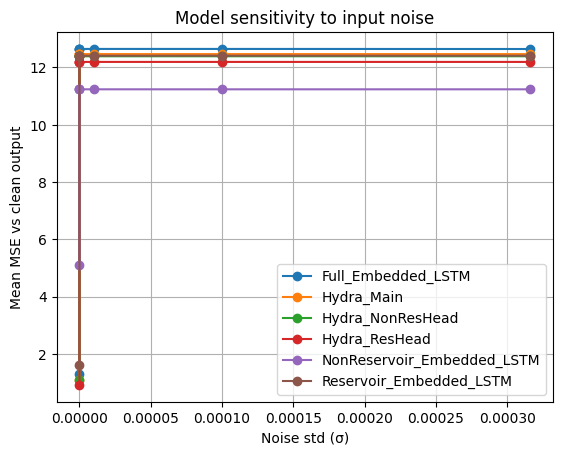

In [70]:
import matplotlib.pyplot as plt

noise_variances = [1e-3, 1e-2, 1e-1, 0.25, 0.5, 1.0, 5, 10, 100] # , 
noise_variances = [1e-30, 1e-20, 1e-15, 1e-10, 1e-8, 1e-7] # ,  1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 0.25, 0.5, 1.0 
df = compute_noise_sensitivity(
    model_names=model_names,
    models=no_flow_models,
    dataloader=test_reservoir_dataloader,
    warmup=warmup,
    noise_variances = noise_variances,       
    device="cpu",
    time_interval=10,
    max_batches=100,
    use_flow=False,
    output_path="/perm/mokr/noise_sensitivity.csv",
)

for model_name, group in df.groupby("model"):
    # plt.plot(group["noise_std"], group["mean_nse"], marker="o", label=model_name)
    plt.plot(group["noise_std"], group["mean_mse"], marker="o", label=model_name)

plt.xlabel("Noise std (σ)")
plt.ylabel("Mean MSE vs clean output")
plt.title("Model sensitivity to input noise")
plt.legend()
plt.grid(True)
plt.show()

In [67]:
df

,model,noise_variance,noise_std,mean_mse,n_samples
0,Full_Embedded_LSTM,0.000000e+00,0.000000e+00,1.544542,500
1,Full_Embedded_LSTM,1.000000e-20,1.000000e-10,13.740284,500
2,Full_Embedded_LSTM,1.000000e-15,3.162278e-08,13.740818,500
3,Full_Embedded_LSTM,1.000000e-10,1.000000e-05,13.740332,500
4,Full_Embedded_LSTM,1.000000e-08,1.000000e-04,13.740739,500
...,...,...,...,...,...
79,Reservoir_Embedded_LSTM,1.000000e-02,1.000000e-01,13.592137,500
80,Reservoir_Embedded_LSTM,1.000000e-01,3.162278e-01,13.579352,500
81,Reservoir_Embedded_LSTM,2.500000e-01,5.000000e-01,13.900780,500
82,Reservoir_Embedded_LSTM,5.000000e-01,7.071068e-01,14.180641,500
